# Manifold Boundary Approximation for the Rigid-Body Lattice Model (6o2h, P1)

This notebook runs the Manifold Boundary Approximation Method (MBAM; Transtrum &
Qiu 2014) on the 126-parameter rigid-body model of `rigid_body_diffuse_6o2h.ipynb`,
fully automatically, and documents every reduction with figures.

**Inputs.** Everything comes from one file written by the original notebook. Add
one cell at the very end of `rigid_body_diffuse_6o2h.ipynb` and run it:

```python
%run -i export_mbam_bundle.py
```

It writes `synthetic_mbam_bundle.npz`: the lattice, the six contacts and their
frames, the prior, the ground truth, the λ-selected fit, the synthetic data with
its train/held-out split and CV folds, and three things that need the electron
density: $G(\mathbf q)$ on an independent dense "oracle" $q$-set, $G$ on the $l=0$
and $l=\tfrac12$ planes, and the original model's intensities at the data points
(used to check that the forward model here is the same one).

**What it produces.** For every MBAM step: the geodesic (how the Fisher spectrum
collapses as it approaches the boundary, which stiffness eigenvalues run away),
the limit that was taken and what it means physically, the refit, and the cost in
$\chi^2$. Across steps: fit quality, information criteria and likelihood-ratio
tests against the number of parameters; the full spectrum staircase; the anatomy
of every eliminated direction; the model's structure contact by contact; a
statistically grounded assignment of each reduced model to a physical class;
band structures and diffuse maps of selected models; a per-step table (CSV); and
an animated GIF of the per-step dashboards.

**Runtime.** MBAM removes parameters one boundary at a time. A step takes from a
few seconds (limits the fit or a direct test finds) to a minute or two (long
geodesics), and later steps are slower because the remaining boundaries are farther
away. Expect on the order of an hour for the whole path. The loop checkpoints after
every step (`mbam_checkpoint.pkl`) and resumes where it stopped when rerun.
`MBAM_TIME_BUDGET` ends it cleanly after a set time. Changing any MBAM or fitting
setting invalidates the checkpoint and starts over.

**Outline.**
1. Settings and the forward model (with infinite-stiffness limits handled exactly).
2. Matrix-log coordinates and the reduced-model family.
3. The metric question: is $M$ needed, and what does it add? (with numerical checks)
4. The MBAM loop, and a greedy continuation where MBAM finds no more boundaries.
5. Summary diagnostics.
6. Classes of models.
7. Selected models: band structures and diffuse maps.
8. A movie of the reduction (optional: `MAKE_MOVIE`).

In [1]:
import os, time, pickle, hashlib, json, warnings
import numpy as np
import scipy.linalg as sla
from scipy.linalg import expm, expm_frechet, eigh as geigh
from scipy.integrate import solve_ivp, RK45, OdeSolution
from scipy.optimize import brentq
from scipy.optimize import least_squares
from scipy.stats import chi2 as chi2_dist
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
from IPython.display import display, Image as IPImage
import imageio.v2 as iio2

np.set_printoptions(precision=4, suppress=True)

# --------------------------------------------------------------------------- files
BUNDLE   = 'synthetic_mbam_bundle.npz'   # written by export_mbam_bundle.py
OUT      = 'mbam_'                       # prefix of every figure / table / cache written here
STEP_DIR = OUT + 'steps'                 # one dashboard PNG per MBAM step goes here
os.makedirs(STEP_DIR, exist_ok=True)

# --------------------------------------------------------------------------- MBAM
MBAM_START      = 'unregularized'  # 'unregularized': refit the full model with lambda = 0,
                                   #   starting from the lambda-selected fit (recommended);
                                   # 'regularized': start at the lambda-selected fit itself;
                                   # 'truth': start at the ground truth (noise-free design study)
MBAM_MAX_STEPS  = 200              # hard cap on reduction steps
MBAM_MIN_PARAMS = 1                # stop when the model has this few parameters left
TAU_MAX         = 100.0            # geodesic arc-length budget (sigma units; ~ sqrt(delta chi^2)).
                                   #   MBAM stops when no boundary lies within it along the
                                   #   N_TRY_DIRS sloppiest directions; raise it to push further
                                   #   into the regime where reductions cost a lot
S_CAP           = 15.0             # geodesic stops when a log-stiffness eigenvalue reaches this
                                   #   (a factor e^15 ~ 3e6 from the prior)
SPEED_CAP       = 1e4              # ... or when the parameter speed grows by this factor
S_ID_MIN        = 4.0              # an eigenvalue must be at least this far out to count as a limit
SHARE_MIN       = 0.05             # and carry at least this share of the final squared speed
TAU_MAX_HARD    = 600.0            # if nothing is found within TAU_MAX, the two sloppiest
GEO_MAX_RHS_HARD = 5000            #   candidates are followed again with these budgets
BOUNDARY_CHOICE = 'cheapest'       # 'cheapest': refit every boundary the geodesics reach and keep
                                   #   the one with the smallest refitted chi^2 (default);
                                   # 'closest': keep the one reached after the shortest arc
                                   #   length, as in the original MBAM (faster)
BEAM_WIDTH      = 2                # models kept at each depth (beam search); 1 = a single greedy
                                   #   path. Beams are ranked by AIC (chi^2 + 2p); the reported path
                                   #   is the best beam at the end. Runtime grows roughly with it
N_TRY_DIRS      = 2                # starting directions tried per family (full spectrum and
                                   #   stiffness-only); the closest boundary wins
FREEZE_G        = 1.0              # the sloppiest direction is frozen (fixed at its fitted value)
                                   #   only if it is mostly orientation and its g is below this:
                                   #   the data cannot fix the angle to within ~1 radian.
                                   #   Well-determined angles are never frozen
LIMIT_TOL       = 0.5              # limit-consistency check: chi^2 between the boundary point
                                   #   and the limiting model must be below this
GEO_RTOL        = 1e-4             # geodesic ODE tolerances (the limit test, not the ODE
                                   #   accuracy, decides when a boundary is reached)
GEO_MAX_RHS     = 1500             # evaluation budget per geodesic
GEO_ATOL        = 1e-6
H_AVV           = 1e-5             # parameter step for the directional derivative A_vv
G_DIRECT        = 1e-6             # below this g, try jumping straight to the limit of the
                                   #   eigenvalue that dominates the direction (no geodesic)

FALLBACK        = 'greedy'         # no boundary within the geodesic budgets:
                                   #   'greedy': one step of the greedy search (the limit with the
                                   #             lowest refitted chi^2), then MBAM again
                                   #   'stop':   end the reduction there
GREEDY_TOP_K    = 5                # candidates refit in full per greedy step (all are first ranked
                                   #   by a one-step Gauss-Newton estimate of the refit cost)

# --------------------------------------------------------------------------- fitting
S_BARRIER       = 17.0             # soft wall on |log-stiffness eigenvalue| during fits; above
                                   #   S_CAP, so a refit never fights a point a geodesic reached
BARRIER_W       = 1.0
FIT_MAX_NFEV    = 300
FIT_ROUNDS      = 4                # refit rounds of FIT_MAX_NFEV until the optimizer converges
RUNAWAY_MARGIN  = 0.5              # an eigenvalue within this of the wall after a fit is a
                                   #   fit-driven limit and is taken immediately
DO_CV           = True             # 3-fold CV (the original notebook's folds) for every model
DO_CLASS_FITS   = True             # translation-only class distance for every model
CLASS_TOL       = 3.84             # chi^2 distance below which a model is statistically
                                   #   indistinguishable from a class (95% point of chi^2_1)

# --------------------------------------------------------------------------- figures
SHOW_STEP_DASHBOARDS = [0, 1, 2]   # steps whose dashboards are shown inline (all are saved);
                                   # class transitions and selected models are added automatically
DPI = 110

# --------------------------------------------------------------------------- movie (section 8)
MAKE_MOVIE          = True         # False skips section 8
MOVIE_BUNDLE        = 'synthetic_movie_bundle.npz'   # from export_mbam_movie.py
MOVIE_FRAME_SECONDS = 2.5          # slow version: seconds per frame
MOVIE_FAST_SECONDS  = 0.5          # fast version: seconds per frame (2 frames per second)
MOVIE_TARGET        = 'truth'      # 'truth' or 'noisy': the "actual" pattern next to the prediction
MOVIE_PLANE_L       = 0.0          # 0.0 or 0.5: the reciprocal-space plane shown
MOVIE_STEPS         = None         # None: every record; or a list of step numbers
RESUME = True                      # continue from OUT + 'checkpoint.pkl' if it matches
MBAM_TIME_BUDGET = None            # seconds; if set, the loop stops after this long and
                                   #   simply continues from the checkpoint when rerun

t_start = time.time()

## 1. The bundle and the forward model

The forward model is the original one, rewritten in a form that also covers the
reduced models MBAM produces. For contact $\mathbf n$ let $N_{\mathbf n}$ map a
lab-frame displacement (referenced at the partner's centre of mass) to the local
frame at the contact centroid, so $K_{\rm lab}=N^{\mathsf T}K_{\rm loc}N$ as in
`K_local_to_lab`. With $M_{\mathbf n}(\mathbf q)=A_{\mathbf n}-e^{i\mathbf q\cdot\mathbf R_{\mathbf n}}I$,
the local relative displacement of a Bloch amplitude $u$ is
$\Delta_{\mathbf n}=B_{\mathbf n}(\mathbf q)u$ with $B_{\mathbf n}=N_{\mathbf n}M_{\mathbf n}$, and

$$D(\mathbf q)=\sum_{\mathbf n}B_{\mathbf n}^\dagger K_{\mathbf n}^{\rm loc}B_{\mathbf n}.$$

**Infinite stiffness, exactly.** A reduced model can have directions of infinite
stiffness: a contact that forbids the relative displacement along a covector
$c$, i.e. $c^{\mathsf T}\Delta_{\mathbf n}=0$. In Bloch space that is the linear
constraint $C_k(\mathbf q)^\dagger u=0$ with $C_k=B_{\mathbf n}^\dagger c$. Taking
$s\to\infty$ in $D+s\,CC^\dagger$ gives the constrained intensity, computed from
the bordered (KKT) system

$$\begin{pmatrix}D&C\\C^\dagger&0\end{pmatrix}\begin{pmatrix}v\\\mu\end{pmatrix}
=\begin{pmatrix}G\\0\end{pmatrix},\qquad I=G^\dagger v .$$

With no constraints this is $I=G^\dagger D^{-1}G$. Differentiating the bordered
system gives closed-form derivatives with $w_{\mathbf n}=B_{\mathbf n}v$:

$$\frac{\partial I}{\partial K^{\rm loc}_{\mathbf n}}=-\mathrm{Re}\,(w^*_{\mathbf n}w_{\mathbf n}^{\mathsf T}),\qquad
\frac{\partial I}{\partial c_k}=-2\,\mathrm{Re}\,(\mu_k\,w^*_{\mathbf n}).$$

A constraint column vanishes on the planes $\mathbf q\cdot\mathbf R_{\mathbf n}\in2\pi\mathbb Z$
when the covector's translational part is parallel to $\mathbf R_{\mathbf n}$ (a pure
relative-rotation constraint, for instance): there every molecule rotates in phase
with its neighbour, so the constraint is automatically satisfied. The solver
drops such columns point by point.

In [2]:
Z = np.load(BUNDLE, allow_pickle=False)
B_recip  = Z['B_recip']; A_orth = Z['A_orth']
CELL     = Z['cell']
NC       = len(Z['contact_n'])
CONTACTS = [tuple(int(x) for x in n) for n in Z['contact_n']]
R_N      = Z['contact_R_n']; R_FRAME = Z['contact_R_frame']
C_LOCAL  = Z['contact_c_local']; GAMMA = Z['contact_Gamma']
N_PAIRS  = Z['contact_n_pairs']; RHO_G = Z['contact_rho_g']
M_MAT    = Z['M_mat']; FREQ_UNIT = float(Z['freq_unit'])
K_PRIOR  = Z['K_prior_local']                  # (NC, 6, 6), local frame at the centroid
L_PRIOR  = Z['L_prior']; L_TRUE = Z['L_true']
K_TRUE   = np.einsum('nij,nkj->nik', L_TRUE, L_TRUE)
THETA_FIT_ORIG = Z['theta_fit']; LAMBDA_ORIG = float(Z['lambda_prior'])
LAMBDA_SCAN_ORIG = Z['lambda_scan']; GEN_SPEC_ORIG = Z['gen_spec']
CLABEL = [str(c) for c in CONTACTS]
CCOL = plt.cm.tab10(np.arange(NC) % 10)

def skew(v):
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

def ad_translation(R):
    A = np.eye(6); A[3:6, 0:3] = -skew(R); return A

def Gc_inv_matrix(c):
    G = np.eye(6); G[3:6, 0:3] = skew(c); return G

# lab displacement (at the partner's COM) -> local displacement at the contact centroid
N_MAP = np.array([Gc_inv_matrix(C_LOCAL[n]) @ GAMMA[n].T for n in range(NC)])
P_MAP = np.array([N_MAP[n] @ ad_translation(R_N[n]) for n in range(NC)])

def sym_sqrt(A, inv=False):
    w, V = np.linalg.eigh(0.5*(A + A.T))
    return (V*(w**(-0.5 if inv else 0.5))) @ V.T

SREF  = np.array([sym_sqrt(K_PRIOR[n]) for n in range(NC)])           # K_prior^{1/2}
SREFI = np.array([sym_sqrt(K_PRIOR[n], inv=True) for n in range(NC)]) # K_prior^{-1/2}

class DataSet:
    """q-points with their coupling vectors, observations and errors. B_n(q) is
    built on demand in chunks, so large sets (maps) never hold it all at once."""
    def __init__(self, hkl, G, y=None, sigma=None, name='', near=None):
        self.hkl = np.asarray(hkl, float); self.G = np.asarray(G, complex)
        self.q = self.hkl @ B_recip.T
        self.y = None if y is None else np.asarray(y, float)
        self.sigma = None if sigma is None else np.asarray(sigma, float)
        self.name = name
        self.near = np.zeros(len(self.q), bool) if near is None else np.asarray(near, bool)
        self._B = None
    def __len__(self):
        return len(self.q)
    def B(self, sl=slice(None)):
        if self._B is not None and sl == slice(None):
            return self._B
        ph = np.exp(1j*(self.q[sl] @ R_N.T))                             # (n, NC)
        B = P_MAP[None] - ph[:, :, None, None]*N_MAP[None]              # (n, NC, 6, 6)
        if sl == slice(None) and len(self.q) <= 5000:
            self._B = B
        return B
    def subset(self, mask, name=None):
        return DataSet(self.hkl[mask], self.G[mask],
                       None if self.y is None else self.y[mask],
                       None if self.sigma is None else self.sigma[mask],
                       name or self.name, self.near[mask])

train_mask = Z['train_mask']
ALL    = DataSet(Z['q_all'], Z['G_all'], Z['I_obs_all'], Z['sigma_all'], 'all', Z['is_near_all'])
TRAIN  = ALL.subset(train_mask, 'train')
TEST   = ALL.subset(~train_mask, 'held out')
ORACLE = DataSet(Z['q_oracle'], Z['G_oracle'], Z['I_true_oracle'], Z['sigma_oracle'],
                 'oracle', Z['oracle_is_near'])
I_TRUE_ALL = Z['I_true_all']
CV_PERM, CV_NFOLDS = Z['cv_perm'], int(Z['cv_nfolds'])
CV_FOLDS = np.array_split(CV_PERM, max(CV_NFOLDS, 1))
print(f"{NC} contacts: {', '.join(CLABEL)}")
print(f"data: {len(TRAIN)} training, {len(TEST)} held out, {len(ORACLE)} oracle points "
      f"({ORACLE.near.sum()} near-Bragg); CV with {CV_NFOLDS} folds over {len(ALL)} points")

6 contacts: (-1, -1, 0), (-1, 0, -1), (-1, 0, 0), (0, -1, 0), (0, -1, 1), (0, 0, -1)
data: 246 training, 34 held out, 1866 oracle points (266 near-Bragg); CV with 3 folds over 280 points


In [3]:
def solve_intensity(ds, Kloc, Ccov, sl=slice(None), want_cov=False):
    """Constrained one-phonon intensity.

    Kloc : list of (6,6) local-frame finite stiffnesses (None = zero).
    Ccov : list of (6, r_n) local constraint covectors (r_n may be 0).
    Returns I, v (Bloch response), mu (unnormalized multipliers, (n, r)),
    owner (contact index of each constraint column) and, if asked, the full
    displacement covariance (n, 6, 6)."""
    B = ds.B(sl); G = ds.G[sl]; n = len(G)
    D = np.zeros((n, 6, 6), complex)
    cols, owner = [], []
    for c in range(NC):
        if Kloc[c] is not None:
            D += np.einsum('nji,jk,nkl->nil', B[:, c].conj(), Kloc[c], B[:, c], optimize=True)
        for k in range(Ccov[c].shape[1]):
            cols.append(np.einsum('nji,j->ni', B[:, c].conj(), Ccov[c][:, k]))
            owner.append(c)
    r = len(cols)
    if r == 0:
        if want_cov:
            Dinv = np.linalg.inv(D)
            v = np.einsum('nij,nj->ni', Dinv, G)
        else:
            Dinv = None
            v = np.linalg.solve(D, G[:, :, None])[:, :, 0]
        I = np.real(np.einsum('ni,ni->n', G.conj(), v))
        return I, v, np.zeros((n, 0), complex), [], Dinv
    C = np.stack(cols, axis=2)                                          # (n, 6, r)
    nrm = np.linalg.norm(C, axis=1)                                     # (n, r)
    ref = np.maximum(nrm.max(axis=0, keepdims=True), 1e-300)
    inactive = nrm < 1e-9*ref                                           # vanishing columns
    Cn = np.where(inactive[:, None, :], 0.0, C/np.where(inactive, 1.0, nrm)[:, None, :])
    m = 6 + r
    KKT = np.zeros((n, m, m), complex)
    KKT[:, :6, :6] = D; KKT[:, :6, 6:] = Cn; KKT[:, 6:, :6] = np.conj(np.swapaxes(Cn, 1, 2))
    idx = np.arange(r)
    KKT[:, 6 + idx, 6 + idx] = inactive.astype(float)                  # drops inactive rows
    if want_cov:
        rhs = np.zeros((n, m, 6), complex); rhs[:, :6, :] = np.eye(6)[None]
        X = np.linalg.solve(KKT, rhs)
        Sig = X[:, :6, :]
        v = np.einsum('nij,nj->ni', Sig, G)
        mu = np.einsum('nij,nj->ni', X[:, 6:, :], G)
    else:
        rhs = np.zeros((n, m), complex); rhs[:, :6] = G
        X = np.linalg.solve(KKT, rhs[:, :, None])[:, :, 0]
        v, mu, Sig = X[:, :6], X[:, 6:], None
    mu = np.where(inactive, 0.0, mu/np.where(inactive, 1.0, nrm))
    I = np.real(np.einsum('ni,ni->n', G.conj(), v))
    return I, v, mu, owner, Sig

def intensity_chunked(ds, Kloc, Ccov, chunk=4000):
    out = np.zeros(len(ds))
    for s in range(0, len(ds), chunk):
        sl = slice(s, min(s + chunk, len(ds)))
        out[sl] = solve_intensity(ds, Kloc, Ccov, sl)[0]
    return out

# --- check against the original notebook's intensities at its fit -------------------
TRIL_I, TRIL_J = np.tril_indices(6)
def theta_to_L(theta):
    L = np.zeros((NC, 6, 6))
    for c in range(NC):
        L[c][TRIL_I, TRIL_J] = theta[21*c:21*(c + 1)]
    return L

def L_to_theta(L):
    return np.concatenate([L[c][TRIL_I, TRIL_J] for c in range(NC)])

_Lfit = theta_to_L(THETA_FIT_ORIG)
K_FIT_ORIG = np.einsum('nij,nkj->nik', _Lfit, _Lfit)
NO_CONSTR = [np.zeros((6, 0)) for _ in range(NC)]
_I_here = intensity_chunked(ALL, list(K_FIT_ORIG), NO_CONSTR)
_rel = np.max(np.abs(_I_here - Z['I_fit_all'])/np.maximum(np.abs(Z['I_fit_all']), 1e-30))
print(f"forward model vs. the original notebook at its fit: max relative difference {_rel:.2e}")
assert _rel < 1e-6, "the forward model here does not reproduce the original notebook"
_I_true_here = intensity_chunked(ALL, list(K_TRUE), NO_CONSTR)
print(f"   and at the truth: {np.max(np.abs(_I_true_here - I_TRUE_ALL)/np.abs(I_TRUE_ALL)):.2e}")

forward model vs. the original notebook at its fit: max relative difference 8.93e-13
   and at the truth: 1.55e-12


## 2. Coordinates and the family of reduced models

**Matrix-log coordinates.** Each contact's stiffness is written relative to the
geometric prior,

$$K_{\mathbf n}=K_{\mathbf n,\rm prior}^{1/2}\,e^{S_{\mathbf n}}\,K_{\mathbf n,\rm prior}^{1/2},
\qquad S_{\mathbf n}=S_{\mathbf n}^{\mathsf T},$$

with the 21 coordinates $\phi=(\mathrm{diag}\,S,\ \sqrt2\,\mathrm{upper}\,S)$. These
are to matrices what log-parameters are to positive scalars:

* every $\phi$ gives a positive-definite $K$, and every $K$ has exactly one $\phi$;
* $\|\phi\|^2=\|\log(K_{\rm prior}^{-1/2}KK_{\rm prior}^{-1/2})\|_F^2$, so the original
  regularizer is exactly the ridge $\lambda\|\phi\|^2$, and the affine-invariant
  metric $M$ of the original notebook is the identity at the prior;
* the two kinds of boundary of a stiffness matrix, an eigenvalue going to $0$ or to
  $\infty$, both sit at infinity ($\sigma\to\mp\infty$ for an eigenvalue $\sigma$ of
  $S$), exactly as $\log k\to\pm\infty$ for a scalar rate constant in the classic
  MBAM examples.

**The reduced models.** In the prior-whitened coordinates $y=K_{\rm prior}^{1/2}\Delta$
of a contact, MBAM can send a stiffness eigenvalue to $\infty$ (the contact then
forbids relative motion along that direction: a constraint, block **C**) or to $0$
(the contact no longer resists it: block **Z**). The remaining directions keep a
finite stiffness (block **F**). A reduced contact is therefore an orthonormal frame
$R$ of whitened space split into $C\oplus Z\oplus F$, plus a symmetric $S_F$ on $F$:

$$K^{\rm loc}=K_{\rm prior}^{1/2}\,U_F e^{S_F}U_F^{\mathsf T}K_{\rm prior}^{1/2},\qquad
c_k=K_{\rm prior}^{1/2}u_{C,k}.$$

The frame is free: $R=R_0\,e^{\Xi}$ with $\Xi$ antisymmetric and nonzero only
between different blocks, so the *orientation* of each constrained or released
direction stays a fitted parameter. One limit therefore removes exactly one
parameter (one eigenvalue), as MBAM requires. Counting per contact,

$$p=n_Cn_Z+n_Cn_F+n_Zn_F+\tfrac12n_F(n_F+1),$$

which is 21 for the full contact, 20 after one limit, and drops by more than one
only at corners (a second constraint in the same contact also makes the rotation
*within* the constrained plane irrelevant).

Orientation angles are radians in whitened space. A direction that is invisible to
the data and consists only of orientation (a constrained direction whose exact
tilt does not matter) has no boundary to run into; MBAM *freezes* it at its current
value instead, which also removes one parameter.

In [4]:
def sym_basis(n):
    """Orthonormal basis of symmetric n x n matrices (Frobenius): E_ii, then
    (E_ij + E_ji)/sqrt2 for i < j in row-major order -- the original notebook's
    [diag, sqrt2*upper] vectorization."""
    out = []
    for i in range(n):
        E = np.zeros((n, n)); E[i, i] = 1.0; out.append(E)
    for i, j in zip(*np.triu_indices(n, 1)):
        E = np.zeros((n, n)); E[i, j] = E[j, i] = 1/np.sqrt(2); out.append(E)
    return np.array(out) if out else np.zeros((0, n, n))

SYM_BASIS = {n: sym_basis(n) for n in range(7)}

def sym_vec(S):
    n = S.shape[0]
    return np.r_[np.diag(S), np.sqrt(2)*S[np.triu_indices(n, 1)]] if n else np.zeros(0)

def sym_unvec(s, n):
    return np.tensordot(s, SYM_BASIS[n], 1) if n else np.zeros((0, 0))

def exp_sym(S):
    """exp of a symmetric matrix and the Daleckii-Krein kernel for its derivative."""
    w, V = np.linalg.eigh(0.5*(S + S.T))
    ew = np.exp(w)
    dw = w[:, None] - w[None, :]
    same = np.abs(dw) < 1e-10
    Phi = np.where(same, ew[:, None], (ew[:, None] - ew[None, :])/np.where(same, 1.0, dw))
    return (V*ew) @ V.T, w, V, Phi

def antisym_pair(a, b):
    E = np.zeros((6, 6)); E[a, b] = 1.0; E[b, a] = -1.0; return E

def _avec(A):                       # antisymmetric 6x6 -> 15-vector, <A,B> = tr(A^T B)/2
    return A[np.triu_indices(6, 1)]

def _amat(v):
    A = np.zeros((6, 6)); A[np.triu_indices(6, 1)] = v; return A - A.T

def cross_block_space(labels):
    """Unit antisymmetric generators rotating one block into another."""
    return [antisym_pair(a, b) for a in range(6) for b in range(a + 1, 6)
            if labels[a] != labels[b]]

class ContactState:
    """One contact of a reduced model (see the markdown above)."""
    def __init__(self, c, R0=None, labels=None, frozen=None, Xi0=None):
        self.c = c
        self.R0 = np.eye(6) if R0 is None else np.array(R0, float)
        self.labels = np.array(['F']*6) if labels is None else np.array(labels)
        self.frozen = [] if frozen is None else [np.array(f) for f in frozen]
        self.Xi0 = np.zeros((6, 6)) if Xi0 is None else np.array(Xi0, float)
        self._build_gens()

    def _build_gens(self):
        W = cross_block_space(self.labels)
        if not W:
            self.gens = np.zeros((0, 6, 6)); return
        Wm = np.array([_avec(A) for A in W])                       # (w, 15), orthonormal rows
        if self.frozen:
            Fm = np.array([_avec(f) for f in self.frozen])
            Fm = (Fm @ Wm.T) @ Wm                                  # project onto W
            Fm = Fm[np.linalg.norm(Fm, axis=1) > 1e-8]
            if len(Fm):
                Qf = np.linalg.svd(Fm, full_matrices=False)[2]
                Qf = Qf[:np.linalg.matrix_rank(Fm, tol=1e-8)]
                Pm = Wm - (Wm @ Qf.T) @ Qf                         # remove frozen span
                U, s, Vt = np.linalg.svd(Pm, full_matrices=False)
                Wm = Vt[s > 1e-8]
        self.gens = np.array([_amat(v) for v in Wm]) if len(Wm) else np.zeros((0, 6, 6))

    iC = property(lambda s: np.where(s.labels == 'C')[0])
    iZ = property(lambda s: np.where(s.labels == 'Z')[0])
    iF = property(lambda s: np.where(s.labels == 'F')[0])
    nC = property(lambda s: int(np.sum(s.labels == 'C')))
    nZ = property(lambda s: int(np.sum(s.labels == 'Z')))
    nF = property(lambda s: int(np.sum(s.labels == 'F')))
    n_orient = property(lambda s: len(s.gens))
    n_s = property(lambda s: s.nF*(s.nF + 1)//2)
    p = property(lambda s: s.n_orient + s.n_s)

    def rotation(self, xi, deriv=False):
        Xi = self.Xi0 + (np.tensordot(xi, self.gens, 1) if len(xi) else 0.0)
        if not deriv:
            return self.R0 @ expm(Xi), None
        if not len(xi):
            return self.R0 @ expm(Xi), np.zeros((0, 6, 6))
        Rot = None; dR = []
        for g in self.gens:
            E, dE = expm_frechet(Xi, g)
            Rot = E; dR.append(self.R0 @ dE)
        return self.R0 @ Rot, np.array(dR)

    def maps(self, params, deriv=False):
        """K (local, finite part), constraint covectors, and their derivatives with
        respect to this contact's parameters."""
        no, nF = self.n_orient, self.nF
        xi, s = params[:no], params[no:]
        R, dR = self.rotation(xi, deriv)
        iF, iC = self.iF, self.iC
        UF, UC = R[:, iF], R[:, iC]
        Sr = SREF[self.c]
        if nF:
            X, w, V, Phi = exp_sym(sym_unvec(s, nF))
            K = Sr @ (UF @ X @ UF.T) @ Sr
        else:
            X = None; K = None
        Cc = Sr @ UC
        if not deriv:
            return K, Cc, None, None
        p = self.p
        dK = np.zeros((p, 6, 6)); dC = np.zeros((p, 6, len(iC)))
        for j in range(no):
            dUF, dUC = dR[j][:, iF], dR[j][:, iC]
            if nF:
                dP = dUF @ X @ UF.T; dP = dP + dP.T
                dK[j] = Sr @ dP @ Sr
            dC[j] = Sr @ dUC
        if nF:
            Et = np.einsum('ai,jab,bk->jik', V, SYM_BASIS[nF], V)          # basis in eigenframe
            dX = np.einsum('ai,jik,bk->jab', V, Phi[None]*Et, V)
            dK[no:] = np.einsum('ab,jbc,dc->jad', Sr @ UF, dX, Sr @ UF)
        return K, Cc, dK, dC

    def s_metric(self, params):
        """Affine-invariant metric on the finite block, in the s coordinates."""
        nF = self.nF
        if not nF:
            return np.zeros((0, 0))
        S = sym_unvec(params[self.n_orient:], nF)
        X, w, V, Phi = exp_sym(S)
        Et = np.einsum('ai,jab,bk->jik', V, SYM_BASIS[nF], V)
        wgt = Phi**2*np.exp(-w[:, None] - w[None, :])
        return np.einsum('jab,kab,ab->jk', Et, Et, wgt)

    def eig_S(self, params):
        nF = self.nF
        if not nF:
            return np.zeros(0), np.zeros((0, 0))
        return np.linalg.eigh(sym_unvec(params[self.n_orient:], nF))

    def copy(self):
        return ContactState(self.c, self.R0.copy(), self.labels.copy(),
                            [f.copy() for f in self.frozen], self.Xi0.copy())

    # --- reductions ------------------------------------------------------------
    def absorbed(self, params):
        """Same physical state with the current rotation folded into R0
        (orientation parameters reset to zero); frozen directions are carried along
        by conjugation, which is exact to first order in the rotation."""
        no = self.n_orient
        Xi = self.Xi0 + (np.tensordot(params[:no], self.gens, 1) if no else 0.0)
        Q = expm(Xi)
        new = ContactState(self.c, self.R0 @ Q, self.labels.copy(),
                           [Q.T @ f @ Q for f in self.frozen], np.zeros((6, 6)))
        return new, params[no:].copy()

    def limit(self, params, e, kind):
        """Send the S_F eigenvalue with F-eigenvector e (unit, length nF) to
        +inf (kind 'C') or -inf (kind 'Z'). Returns (new state, new params)."""
        st, s = self.absorbed(params)
        nF = st.nF
        S = sym_unvec(s, nF)
        e = e/np.linalg.norm(e)
        w, V = np.linalg.eigh(S)
        # basis of e-perp inside F: project the eigenvectors, orthonormalize
        Vp = V - np.outer(e, e @ V)
        U, sv, _ = np.linalg.svd(Vp, full_matrices=False)
        Vr = U[:, :nF - 1]
        Qf = np.column_stack([e, Vr])                                  # rotation of F
        iF = st.iF
        R0 = st.R0.copy()
        R0[:, iF] = st.R0[:, iF] @ Qf
        Qfull = np.eye(6); Qfull[np.ix_(iF, iF)] = Qf
        frozen = [Qfull.T @ f @ Qfull for f in st.frozen]
        labels = st.labels.copy(); labels[iF[0]] = kind
        new = ContactState(self.c, R0, labels, frozen, np.zeros((6, 6)))
        S_new = Vr.T @ S @ Vr
        params_new = np.r_[np.zeros(new.n_orient), sym_vec(0.5*(S_new + S_new.T))]
        return new, params_new

    def freeze(self, params, direction_xi):
        """Fix the orientation combination direction_xi (coefficients on self.gens)
        at its current value. Exact: the current state is reproduced."""
        no = self.n_orient
        xi = params[:no]
        d = np.tensordot(direction_xi, self.gens, 1)
        d = d/np.sqrt(0.5*np.sum(d*d))
        Xi0 = self.Xi0 + np.tensordot(xi, self.gens, 1)
        new = ContactState(self.c, self.R0.copy(), self.labels.copy(),
                           self.frozen + [d], Xi0)
        return new, np.r_[np.zeros(new.n_orient), params[no:]]

    def describe(self):
        return f"C{self.nC} Z{self.nZ} F{self.nF} (p={self.p})"


class ReducedModel:
    """A product of contact states; the parameter vector is their concatenation."""
    def __init__(self, contacts):
        self.contacts = contacts
    @property
    def p(self):
        return sum(cs.p for cs in self.contacts)
    def slices(self):
        out, i = [], 0
        for cs in self.contacts:
            out.append(slice(i, i + cs.p)); i += cs.p
        return out
    def copy(self):
        return ReducedModel([cs.copy() for cs in self.contacts])
    def mats(self, phi):
        Ks, Cs = [], []
        for cs, sl in zip(self.contacts, self.slices()):
            K, Cc, _, _ = cs.maps(phi[sl])
            Ks.append(K); Cs.append(Cc)
        return Ks, Cs
    def predict(self, phi, ds):
        Ks, Cs = self.mats(phi)
        return intensity_chunked(ds, Ks, Cs)
    def predict_jac(self, phi, ds):
        """I and dI/dphi from the bordered system (closed form) chained through
        the per-contact maps."""
        Ks, Cs, dKs, dCs = [], [], [], []
        for cs, sl in zip(self.contacts, self.slices()):
            K, Cc, dK, dC = cs.maps(phi[sl], deriv=True)
            Ks.append(K); Cs.append(Cc); dKs.append(dK); dCs.append(dC)
        I, v, mu, owner, _ = solve_intensity(ds, Ks, Cs)
        B = ds.B()
        J = np.zeros((len(ds), self.p))
        col = 0
        for c, (cs, sl) in enumerate(zip(self.contacts, self.slices())):
            if cs.p == 0:
                continue
            w = np.einsum('nij,nj->ni', B[:, c], v)                          # local rel. displacement
            WK = -np.real(np.conj(w)[:, :, None]*w[:, None, :]).reshape(len(ds), 36)
            J[:, sl] = WK @ dKs[c].reshape(cs.p, 36).T
            ks = [k for k, o in enumerate(owner) if o == c]
            for kk, k in enumerate(ks):
                gc = -2*np.real(mu[:, k, None]*np.conj(w))                 # (n, 6)
                J[:, sl] += gc @ dCs[c][:, :, kk].T
        return I, J
    def metric(self, phi):
        M = np.zeros((self.p, self.p))
        for cs, sl in zip(self.contacts, self.slices()):
            no = cs.n_orient
            idx = np.arange(sl.start, sl.stop)
            M[idx[:no], idx[:no]] = 1.0
            if cs.nF:
                M[np.ix_(idx[no:], idx[no:])] = cs.s_metric(phi[sl])
        return M
    def describe(self):
        return ' | '.join(f"{CLABEL[cs.c]}: {cs.describe()}" for cs in self.contacts)


def full_model():
    return ReducedModel([ContactState(c) for c in range(NC)])

def phi_from_K(Kloc):
    """Matrix-log coordinates of a set of local stiffnesses (full model)."""
    out = []
    for c in range(NC):
        P = SREFI[c] @ Kloc[c] @ SREFI[c]
        w, V = np.linalg.eigh(0.5*(P + P.T))
        out.append(sym_vec((V*np.log(w)) @ V.T))
    return np.concatenate(out)

# --- residuals, chi^2, fits --------------------------------------------------------
def resid(model, phi, ds):
    return (model.predict(phi, ds) - ds.y)/ds.sigma

def resid_jac(model, phi, ds):
    I, J = model.predict_jac(phi, ds)
    return (I - ds.y)/ds.sigma, J/ds.sigma[:, None]

def chi2(model, phi, ds):
    r = resid(model, phi, ds); return float(r @ r)

def barrier(model, phi, need_jac=True):
    """Soft wall at |sigma| = S_BARRIER on every log-stiffness eigenvalue, so that an
    unregularized fit cannot run a sloppy eigenvalue to overflow. Zero inside."""
    rs, Js = [], []
    for cs, sl in zip(model.contacts, model.slices()):
        if not cs.nF:
            continue
        w, V = cs.eig_S(phi[sl])
        for j in range(cs.nF):
            x = abs(w[j]) - S_BARRIER
            rs.append(BARRIER_W*max(x, 0.0)**2)
            if need_jac:
                row = np.zeros(model.p)
                if x > 0:
                    v = V[:, j]
                    dsig = np.r_[v**2, np.sqrt(2)*np.outer(v, v)[np.triu_indices(cs.nF, 1)]]
                    row[sl.start + cs.n_orient:sl.stop] = 2*BARRIER_W*x*np.sign(w[j])*dsig
                Js.append(row)
    rs = np.array(rs)
    return rs, (np.array(Js).reshape(len(rs), model.p) if need_jac else None)

def fit_model(model, phi0, ds, lam=0.0, max_nfev=FIT_MAX_NFEV, use_barrier=True, rounds=None):
    """Least-squares fit (trust-region reflective, analytic Jacobian). lam > 0 adds
    the ridge lam*||s||^2 on the finite-block coordinates (for the full model that is
    exactly the original geodesic regularizer)."""
    if model.p == 0:
        return phi0.copy(), None
    sel = np.zeros(model.p, bool)
    for cs, sl in zip(model.contacts, model.slices()):
        sel[sl.start + cs.n_orient:sl.stop] = True
    cache = {}
    def fun(x):
        k = x.tobytes()
        if k not in cache:
            cache.clear()
            r, J = resid_jac(model, x, ds)
            parts, jparts = [r], [J]
            if use_barrier:
                rb, Jb = barrier(model, x)
                parts.append(rb); jparts.append(Jb)
            if lam > 0:
                parts.append(np.sqrt(lam)*x[sel])
                jparts.append(np.sqrt(lam)*np.eye(model.p)[sel])
            cache[k] = (np.concatenate(parts), np.vstack(jparts))
        return cache[k]
    x = np.asarray(phi0, float)
    for _ in range(FIT_ROUNDS if rounds is None else rounds):   # restart until converged
        res = least_squares(lambda x: fun(x)[0], x, jac=lambda x: fun(x)[1], method='trf',
                            x_scale=1.0, ftol=1e-10, xtol=1e-10, gtol=1e-10, max_nfev=max_nfev)
        x = res.x
        if res.status != 0:                    # stopped by a tolerance, not by max_nfev
            break
    return x, res

def runaway_directions(model, phi, margin=RUNAWAY_MARGIN):
    """Eigenvalues that an unregularized fit has pushed to the wall: the best fit
    sits on (numerically at) a boundary, so the limit is taken directly."""
    out = []
    for cs, sl in zip(model.contacts, model.slices()):
        if not cs.nF:
            continue
        w, V = cs.eig_S(phi[sl])
        for j in range(cs.nF):
            if abs(w[j]) > S_BARRIER - margin:
                out.append((cs.c, V[:, j], 'C' if w[j] > 0 else 'Z', float(w[j])))
    return out

def apply_limits(model, phi, limits):
    """limits: list of (contact index, F-eigenvector, kind). Several limits in one
    contact are applied in turn, each eigenvector re-expressed in the reduced F."""
    new = model.copy(); new_phi = []
    by_c = {}
    for c, e, kind in limits:
        by_c.setdefault(c, []).append((np.asarray(e, float), kind))
    for cs, sl in zip(model.contacts, model.slices()):
        st, pr = cs.copy(), phi[sl].copy()
        if cs.c in by_c:
            for e, kind in by_c[cs.c]:
                # e is in the coordinates of the F block as it was before this step;
                # map it into the current (already reduced) F block
                if st.nF < len(e):
                    Rf_old = cs.rotation(phi[sl][:cs.n_orient])[0][:, cs.iF]
                    Rf_now = st.rotation(pr[:st.n_orient])[0][:, st.iF]
                    e = Rf_now.T @ (Rf_old @ e)
                    e = e/np.linalg.norm(e)
                st, pr = st.limit(pr, e, kind)
        new.contacts[cs.c] = st
        new_phi.append(pr)
    return new, np.concatenate(new_phi) if new_phi else np.zeros(0)

def freeze_orientation(model, phi, v):
    """Freeze the orientation part of direction v in the contact that dominates it.
    One orientation combination of one contact is fixed, so exactly one parameter is
    removed; the other contacts' orientations stay free and adjust in the refit."""
    norms = [np.linalg.norm(v[sl][:cs.n_orient]) if cs.n_orient else 0.0
             for cs, sl in zip(model.contacts, model.slices())]
    c_star = int(np.argmax(norms))
    new = model.copy(); parts = []
    for cs, sl in zip(model.contacts, model.slices()):
        if cs.c == c_star:
            st, pr = cs.freeze(phi[sl], v[sl][:cs.n_orient])
        else:
            st, pr = cs.copy(), phi[sl].copy()
        new.contacts[cs.c] = st; parts.append(pr)
    return new, np.concatenate(parts)


M_FULL  = full_model()
PHI_REG = phi_from_K(K_FIT_ORIG)           # the original notebook's (regularized) fit

## 3. Is the metric $M$ needed, and what does it add?

**No regularizer is used anywhere in this notebook.** Every fit minimizes $\chi^2$
alone. The only trace of the regularizer is its *metric*: the affine-invariant
metric $M$ that the original notebook derived from the geodesic distance. It is used
for three bookkeeping jobs, never in the geometry MBAM integrates:

1. **Choosing where to start each geodesic.** "The sloppiest direction" is the
   smallest generalized eigenvalue $g$ of $(J^{\mathsf T}J, M)$: the least
   $\Delta\chi^2$ per squared geodesic unit (one unit is a factor $e$ in one
   stiffness eigenvalue). The smallest eigenvector of $J^{\mathsf T}J$ alone is not a
   well-defined object when parameters carry different units.
2. **Unit-free thresholds and spectra.** Because $J^{\mathsf T}J$ and $M$ transform
   alike, $g$ is unit-free. Every threshold stated in $g$ (`G_DIRECT`, `FREEZE_G`), the
   spectrum figures and the count of measured directions use it. As a stiffness
   eigenvalue runs to $0$ or $\infty$ the data stop responding and $g\to0$; in $M$ both
   kinds of boundary lie at infinite distance, as they do for log-parameters.
3. **Telling orientation from stiffness.** Whether a sloppy direction is mostly a
   rotation of locked or released directions (and should be frozen) is judged in $M$.

One job $M$ is deliberately *not* given: reading off which eigenvalue diverged at a
boundary. Near a boundary the affine-invariant metric weights a rotation between
eigenvectors whose log-eigenvalues differ by $\Delta$ by
$[\sinh(\Delta/2)/(\Delta/2)]^2$, which grows exponentially. In $M$, the eigenvalue
that is running away therefore carries a vanishing share of the speed. Section 4
measures that share in spectral coordinates instead.

The geodesic itself is integrated with $g_{\rm data}=J^{\mathsf T}J$ only. It is a
curve on the model manifold (a set of predictions), so it does not depend on units
or coordinates. The cells below check each of these statements numerically, at the
original notebook's fit (the point where its invariant spectrum was computed):

* the raw spectrum of $J^{\mathsf T}J$ in Cholesky coordinates, in Cholesky
  coordinates with rotations measured in degrees, and in matrix-log coordinates:
  three different answers;
* the generalized spectrum of $(J^{\mathsf T}J,M)$ in the same three systems: one
  answer, equal to the original notebook's;
* the "sloppiest direction" according to the raw spectra (a unit artefact) and
  according to $M$ (the same physical direction in every system);
* a geodesic integrated in Cholesky and in matrix-log coordinates from the same
  physical starting velocity: the same curve of predictions;
* the same geodesic in the regularized geometry, with the prior's residuals
  $\sqrt\lambda\,\phi$ treated as data, as one would if $M$ were "added to the
  metric": the Fisher matrix stays above $\lambda$ in matrix-log coordinates, every boundary
  is infinitely far away,
  and MBAM has nothing to find. Regularization and MBAM are different answers to the
  same sloppiness: the first holds sloppy directions near the prior, the second
  removes them.

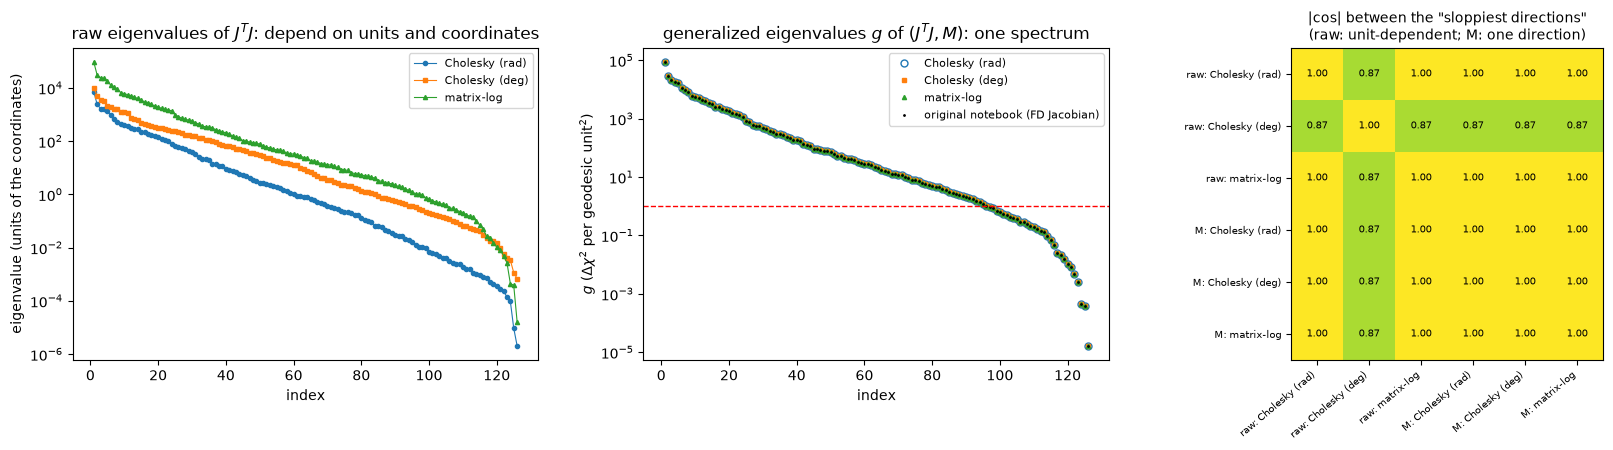

largest relative difference among the 100 best-determined g values, vs matrix-log: Cholesky (rad) 8.2e-13, Cholesky (deg) 2.2e-12, matrix-log 0.0e+00
   and the original notebook's spectrum: 2.9e-08
raw spectra: largest/smallest ratio of the smallest eigenvalue across systems 3.3e+02
M-sloppiest direction, |cos| of the angle between the stiffness changes (vs matrix-log): 1.000000, 1.000000, 1.000000


In [5]:
# --- the three coordinate systems ---------------------------------------------------

def theta_resid_jac(theta, ds):
    """Residuals and Jacobian in the original Cholesky coordinates."""
    L = theta_to_L(theta); K = np.einsum('nij,nkj->nik', L, L)
    I, v, _, _, _ = solve_intensity(ds, list(K), NO_CONSTR)
    B = ds.B(); J = np.zeros((len(ds), 21*NC))
    for c in range(NC):
        w = np.einsum('nij,nj->ni', B[:, c], v)
        WK = -np.real(np.conj(w)[:, :, None]*w[:, None, :])
        dL = 2.0*(WK @ L[c][None])
        J[:, 21*c:21*(c + 1)] = dL[:, TRIL_I, TRIL_J]
    return (I - ds.y)/ds.sigma, J/ds.sigma[:, None]

def theta_resid(theta, ds):
    L = theta_to_L(theta); K = np.einsum('nij,nkj->nik', L, L)
    return (intensity_chunked(ds, list(K), NO_CONSTR) - ds.y)/ds.sigma

def theta_metric(theta):
    """metric_at() of the original notebook: sum tr(K^-1 dK_a K^-1 dK_b)."""
    L = theta_to_L(theta); Mt = np.zeros((21*NC, 21*NC))
    for c in range(NC):
        Ki = np.linalg.inv(L[c] @ L[c].T)
        Zs = []
        for a in range(21):
            E = np.zeros((6, 6)); E[TRIL_I[a], TRIL_J[a]] = 1.0
            Zs.append(Ki @ (E @ L[c].T + L[c] @ E.T))
        Zs = np.array(Zs)
        Mt[21*c:21*(c + 1), 21*c:21*(c + 1)] = np.einsum('aij,bji->ab', Zs, Zs)
    return 0.5*(Mt + Mt.T)

# rotations in degrees: Delta' = T Delta, T = diag(180/pi I, I)  =>  L' = T^-1 L,
# i.e. theta = D theta' with D = 180/pi on the Cholesky entries of the three
# rotational rows. A pure change of units.
D_DEG = np.ones(21*NC)
for c in range(NC):
    D_DEG[21*c:21*(c + 1)][TRIL_I < 3] = 180/np.pi

def dK_of_direction(coords, base, d):
    """Per-contact dK (local frame) of a parameter-space direction d at base."""
    if coords in ('theta', 'theta_deg'):
        dth = d*D_DEG if coords == 'theta_deg' else d
        bth = base*D_DEG if coords == 'theta_deg' else base
        L, dL = theta_to_L(bth), theta_to_L(dth)
        return np.einsum('nij,nkj->nik', dL, L) + np.einsum('nij,nkj->nik', L, dL)
    out = []
    for cs, sl in zip(M_FULL.contacts, M_FULL.slices()):
        _, _, dK, _ = cs.maps(base[sl], deriv=True)
        out.append(np.tensordot(d[sl], dK, 1))
    return np.array(out)

def block_fractions(dK):
    """RR / TR / TT shares of a stiffness change, measured in the prior-whitened
    frame at each contact centroid (where the prior is block-diagonal), plus the
    share of each contact."""
    X = np.einsum('nij,njk,nkl->nil', SREFI, dK, SREFI)
    rr = np.sum(X[:, :3, :3]**2, axis=(1, 2)); tt = np.sum(X[:, 3:, 3:]**2, axis=(1, 2))
    tr = 2*np.sum(X[:, :3, 3:]**2, axis=(1, 2)); tot = (rr + tr + tt).sum()
    return np.array([rr.sum(), tr.sum(), tt.sum()])/tot, (rr + tr + tt)/tot

theta0 = THETA_FIT_ORIG
_, J_th = theta_resid_jac(theta0, TRAIN)
J_dg = J_th*D_DEG[None, :]
_, J_ph = resid_jac(M_FULL, PHI_REG, TRAIN)
M_th = theta_metric(theta0); M_dg = D_DEG[:, None]*M_th*D_DEG[None, :]
M_ph = M_FULL.metric(PHI_REG)
SYSTEMS = {'Cholesky (rad)': ('theta', J_th, M_th, theta0),
           'Cholesky (deg)': ('theta_deg', J_dg, M_dg, theta0/D_DEG),
           'matrix-log': ('phi', J_ph, M_ph, PHI_REG)}

raw_spec, gen_spec, raw_dir, gen_dir = {}, {}, {}, {}
for name, (co, J_, M_, base) in SYSTEMS.items():
    F_ = J_.T @ J_
    w, V = np.linalg.eigh(0.5*(F_ + F_.T)); raw_spec[name] = w[::-1]; raw_dir[name] = V[:, 0]
    g, Vg = sla.eigh(0.5*(F_ + F_.T), 0.5*(M_ + M_.T)); gen_spec[name] = g[::-1]; gen_dir[name] = Vg[:, 0]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (name, w), mk in zip(raw_spec.items(), ['o', 's', '^']):
    ax[0].semilogy(np.arange(1, len(w) + 1), np.maximum(w, 1e-300), mk + '-', ms=3, lw=0.8, label=name)
ax[0].set_title('raw eigenvalues of $J^TJ$: depend on units and coordinates')
ax[0].set_xlabel('index'); ax[0].set_ylabel('eigenvalue (units of the coordinates)'); ax[0].legend(fontsize=8)
for (name, g), mk in zip(gen_spec.items(), ['o', 's', '^']):
    ax[1].semilogy(np.arange(1, len(g) + 1), np.maximum(g, 1e-300), mk, ms=5 if mk == 'o' else 3,
                   mfc='none' if mk == 'o' else None, label=name)
if len(GEN_SPEC_ORIG):
    ax[1].semilogy(np.arange(1, len(GEN_SPEC_ORIG) + 1), np.maximum(GEN_SPEC_ORIG, 1e-300), 'k.', ms=2,
                   label='original notebook (FD Jacobian)')
ax[1].axhline(1, color='r', ls='--', lw=1)
ax[1].set_title('generalized eigenvalues $g$ of $(J^TJ, M)$: one spectrum')
ax[1].set_xlabel('index'); ax[1].set_ylabel(r'$g$ ($\Delta\chi^2$ per geodesic unit$^2$)'); ax[1].legend(fontsize=8)
names = list(SYSTEMS)
_dirs6 = [dK_of_direction(SYSTEMS[n][0], SYSTEMS[n][3], raw_dir[n]) for n in names] + \
         [dK_of_direction(SYSTEMS[n][0], SYSTEMS[n][3], gen_dir[n]) for n in names]
# compare the directions as stiffness changes in the prior-whitened frame, where
# rotational, coupling and translational entries are commensurate
_vecs = [np.einsum('nij,njk,nkl->nil', SREFI, d, SREFI).ravel() for d in _dirs6]
_vecs = [v/np.linalg.norm(v) for v in _vecs]
C6 = np.abs(np.array([[a_ @ b_ for b_ in _vecs] for a_ in _vecs]))
_lab6 = [f'raw: {n}' for n in names] + [f'M: {n}' for n in names]
ax[2].imshow(C6, vmin=0, vmax=1, cmap='viridis')
for i in range(6):
    for j in range(6):
        ax[2].text(j, i, f'{C6[i, j]:.2f}', ha='center', va='center', fontsize=7,
                   color='w' if C6[i, j] < 0.6 else 'k')
ax[2].set_xticks(range(6)); ax[2].set_xticklabels(_lab6, rotation=40, ha='right', fontsize=7)
ax[2].set_yticks(range(6)); ax[2].set_yticklabels(_lab6, fontsize=7)
ax[2].set_title('|cos| between the "sloppiest directions"\n(raw: unit-dependent; M: one direction)', fontsize=10)
plt.tight_layout(); plt.savefig(OUT + 'metric_spectra.png', dpi=DPI); plt.show()

_d = [np.max(np.abs(gen_spec[n][:100] - gen_spec[names[2]][:100])/gen_spec[names[2]][:100]) for n in names]
print("largest relative difference among the 100 best-determined g values, vs matrix-log: "
      + ", ".join(f"{n} {x:.1e}" for n, x in zip(names, _d)))
if len(GEN_SPEC_ORIG):
    print(f"   and the original notebook's spectrum: "
          f"{np.max(np.abs(GEN_SPEC_ORIG[:100] - gen_spec[names[2]][:100])/gen_spec[names[2]][:100]):.1e}")
print("raw spectra: largest/smallest ratio of the smallest eigenvalue across systems "
      f"{max(raw_spec[n][-1] for n in names)/max(min(raw_spec[n][-1] for n in names), 1e-300):.1e}")
_cos = [abs(np.dot(dK_of_direction(SYSTEMS[a][0], SYSTEMS[a][3], gen_dir[a]).ravel(),
                   dK_of_direction(SYSTEMS[names[2]][0], SYSTEMS[names[2]][3], gen_dir[names[2]]).ravel()))
        /np.linalg.norm(dK_of_direction(SYSTEMS[a][0], SYSTEMS[a][3], gen_dir[a]))
        /np.linalg.norm(dK_of_direction(SYSTEMS[names[2]][0], SYSTEMS[names[2]][3], gen_dir[names[2]])) for a in names]
print("M-sloppiest direction, |cos| of the angle between the stiffness changes (vs matrix-log): "
      + ", ".join(f"{x:.6f}" for x in _cos))

**A geodesic does not care about units.** Below, the same geodesic is integrated
in Cholesky and in matrix-log coordinates, from the same point and the same
physical starting velocity (mapped between the systems by the chain rule). The
predictions along the two curves agree to the ODE tolerance.

The second half compares the data geometry with the *regularized* one, in which the
prior's residuals $\sqrt\lambda\,\phi$ are appended to the data. In matrix-log
coordinates they are linear, so they add $\lambda I$ to $J^{\mathsf T}J$ and nothing to
the acceleration. Both geodesics start along the same sloppiest direction, each with
unit speed *in its own geometry*, so each arc length is a distance in that geometry.
In the data geometry the Fisher matrix loses rank and the boundary (a stiffness
eigenvalue at infinity) is reached after a finite arc length. In the regularized
geometry the Fisher matrix never drops below $\lambda$. The arc length needed to
move a log-stiffness eigenvalue grows at least as $\sqrt\lambda\,|\Delta\sigma|$
(dotted line; the eigenvalue cannot move faster than $\|\Delta\phi\|$), so the
boundary is infinitely far away.

In [6]:
def geodesic_core(rfun, rjfun, x0, v0, tau_max, events=(), aug_lambda=0.0, max_rhs=6000,
                  stop_fn=None):
    """Integrate x'' = -(J^T J)^+ J^T A_vv(x, x') from (x0, v0) with RK45.

    rfun(x) -> residuals, rjfun(x) -> (residuals, Jacobian). A_vv is the second
    directional derivative of the residuals along the velocity, from a central
    difference of the analytic J v. aug_lambda > 0 appends sqrt(lambda)*x to the residuals
    (linear, so it adds lambda*I to J^T J and nothing to A_vv). Steps are taken one
    at a time, so a failure or an exhausted budget still returns the path so far;
    terminal events are located by root finding on the dense output. stop_fn(t, y),
    if given, is called after every step; a non-None return ends the integration
    (reason 'limit reached') and is stored as out['stop_info']."""
    p = len(x0)
    state = {'n': 0}
    class _Budget(Exception):
        pass
    def rhs(t, y):
        state['n'] += 1
        if state['n'] > max_rhs:
            raise _Budget()
        x, v = y[:p], y[p:]
        r, J = rjfun(x)
        # A_vv = d/dt [J(x + t v) v] by a central difference of the analytic
        # Jacobian-vector product. (A second difference of the residuals is swamped
        # by round-off along sloppy directions, where |v| is in the hundreds.)
        vn = np.linalg.norm(v); td = 1e-3                     # step of ~1e-3 sigma in data space
        if td*vn <= 0.05:                                      # small parameter step: cheap and accurate
            A = (rfun(x + td*v) + rfun(x - td*v) - 2*r)/td**2
        else:                                                  # fast, sloppy motion: difference J v instead
            t = H_AVV/vn
            A = (rjfun(x + t*v)[1] @ v - rjfun(x - t*v)[1] @ v)/(2*t)
        if aug_lambda > 0:
            J = np.vstack([J, np.sqrt(aug_lambda)*np.eye(p)]); A = np.r_[A, np.zeros(p)]
        a = -np.linalg.lstsq(J, A, rcond=1e-15)[0]
        if not np.all(np.isfinite(a)):
            raise np.linalg.LinAlgError('non-finite acceleration')
        return np.r_[v, a]
    y0 = np.r_[x0, v0].astype(float)
    out = {'status': 'ok', 'reason': 'tau_max', 'sol': None, 't_end': 0.0, 'y_end': y0}
    ts, interps = [0.0], []
    try:
        solver = RK45(rhs, 0.0, y0, tau_max, rtol=GEO_RTOL, atol=GEO_ATOL)
        ev_prev = [ev(0.0, y0) for ev in events]
        while solver.status == 'running':
            try:
                solver.step()
            except _Budget:
                out.update(status='failed', reason='rhs budget'); break
            except (np.linalg.LinAlgError, FloatingPointError, ValueError) as e:
                out.update(status='failed', reason=f'linalg: {str(e)[:40]}'); break
            if solver.status == 'failed':
                out.update(status='failed', reason='integrator'); break
            interp = solver.dense_output(); t_new = solver.t
            ts.append(t_new); interps.append(interp)
            hit = None
            for i, ev in enumerate(events):
                val = ev(t_new, solver.y)
                crossed = (val < 0 <= ev_prev[i]) if ev.direction < 0 else \
                          (val > 0 >= ev_prev[i]) if ev.direction > 0 else (np.sign(val) != np.sign(ev_prev[i]))
                if crossed:
                    try:
                        tr = brentq(lambda t: ev(t, interp(t)), ts[-2], t_new, xtol=1e-12)
                    except ValueError:
                        tr = t_new
                    if hit is None or tr < hit[0]:
                        hit = (tr, getattr(ev, 'name', 'event'))
                ev_prev[i] = val
            if hit is not None:
                ts[-1] = max(hit[0], ts[-2] + 1e-15); out['reason'] = hit[1]; break
            if stop_fn is not None:
                info = stop_fn(t_new, solver.y)
                if info is not None:
                    out['reason'] = 'limit reached'; out['stop_info'] = info; break
    except (np.linalg.LinAlgError, FloatingPointError, ValueError) as e:
        out.update(status='failed', reason=f'linalg: {str(e)[:40]}')
    if interps:
        sol = OdeSolution(ts, interps)
        out['sol'] = sol; out['t_end'] = float(ts[-1]); out['y_end'] = sol(ts[-1])
    out['n_rhs'] = state['n']
    return out

def make_events(model):
    p = model.p
    def ev_cap(t, y):
        m = 0.0
        for cs, sl in zip(model.contacts, model.slices()):
            if cs.nF:
                m = max(m, float(np.abs(cs.eig_S(y[:p][sl])[0]).max()))
        return S_CAP - m
    ev_cap.terminal, ev_cap.direction, ev_cap.name = True, -1, 'eigenvalue cap'
    speed0 = {}
    def ev_speed(t, y):
        s = np.linalg.norm(y[p:])
        if 'v' not in speed0:
            speed0['v'] = s
        return np.log(SPEED_CAP) - np.log(max(s, 1e-300)/speed0['v'])
    ev_speed.terminal, ev_speed.direction, ev_speed.name = True, -1, 'speed cap'
    return [ev_cap, ev_speed]

def dphi_dtheta_map(theta):
    """d(theta)/d(phi) at a point, for mapping a velocity from matrix-log to Cholesky."""
    L = theta_to_L(theta); T = np.zeros((21*NC, 21*NC))
    phi = phi_from_K(np.einsum('nij,nkj->nik', L, L))
    for cs, sl in zip(M_FULL.contacts, M_FULL.slices()):
        _, _, dK, _ = cs.maps(phi[sl], deriv=True)
        c = cs.c; Li = np.linalg.inv(L[c])
        for a in range(21):
            Y = Li @ dK[a] @ Li.T
            Ph = np.tril(Y); Ph[np.diag_indices(6)] *= 0.5        # dL = L Phi(L^-1 dK L^-T)
            T[21*c:21*(c + 1), sl.start + a] = (L[c] @ Ph)[TRIL_I, TRIL_J]
    return T

direction 30 (g = 0.988) meets 'speed cap' at tau = 1.265; comparing the coordinate systems up to tau = 1.138
invariance test along direction 30 (g = 0.988): after travelling 1.138 sigma-units in data space, the two curves differ by 4.66e-05


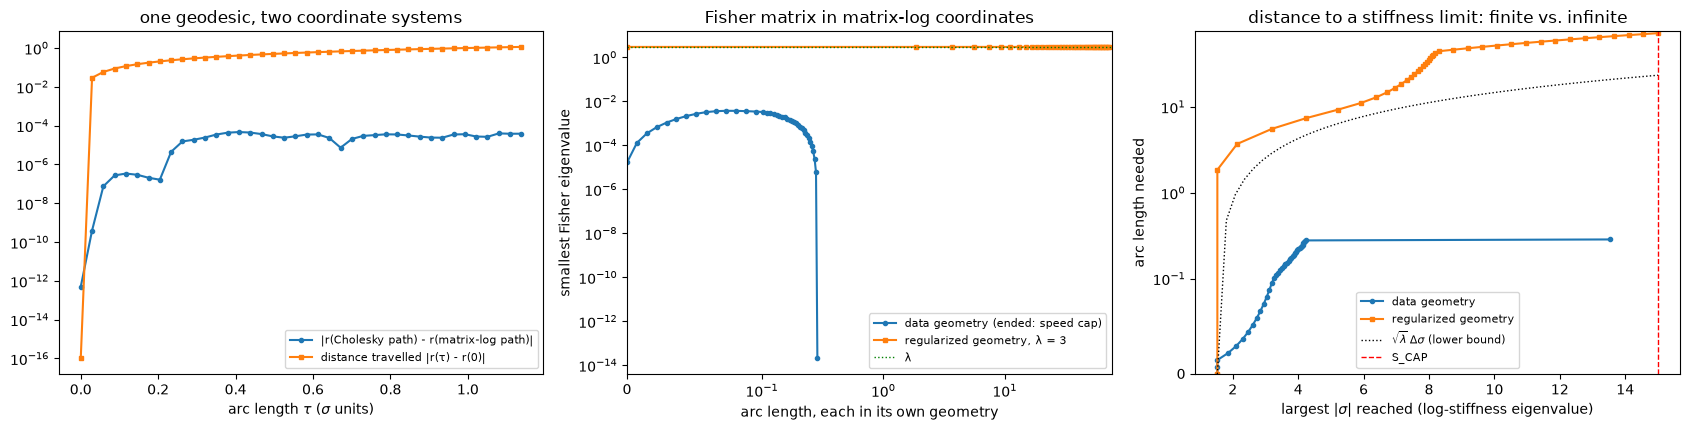

data geometry: 'speed cap' after arc length 0.286 (largest |sigma| 13.5)
regularized geometry: arc length 72.1 to reach |sigma| = 15.0 ('eigenvalue cap'); its smallest Fisher eigenvalue never fell below 3 (lambda = 3)


In [7]:
# direction for the invariance test: a moderately sloppy one, so the path is long
# enough to bend but stays clear of the boundary
_gp, _Vp = sla.eigh(J_ph.T @ J_ph, M_ph)
_k = int(np.argmin(np.abs(np.log(np.maximum(_gp, 1e-300)) - np.log(1.0))))
_v_phi = _Vp[:, _k]/np.linalg.norm(J_ph @ _Vp[:, _k])
_v_th = dphi_dtheta_map(theta0) @ _v_phi
# first find how far this direction is from a boundary, then compare the two
# coordinate systems on the stretch before it (90% of the way)
geo_ph = geodesic_core(lambda x: resid(M_FULL, x, TRAIN), lambda x: resid_jac(M_FULL, x, TRAIN),
                       PHI_REG, _v_phi, 6.0, events=make_events(M_FULL), max_rhs=3000)
TAU_DEMO = 0.9*geo_ph['t_end'] if geo_ph['reason'] != 'tau_max' else 6.0
print(f"direction {_k} (g = {_gp[_k]:.3g}) meets '{geo_ph['reason']}' at tau = {geo_ph['t_end']:.3f}; "
      f"comparing the coordinate systems up to tau = {TAU_DEMO:.3f}")
geo_th = geodesic_core(lambda x: theta_resid(x, TRAIN), lambda x: theta_resid_jac(x, TRAIN),
                       theta0, _v_th, TAU_DEMO, max_rhs=3000)
_tt = np.linspace(0, min(TAU_DEMO, geo_th.get('t_end', 0.0)), 40)
_rph = np.array([resid(M_FULL, geo_ph['sol'](t)[:M_FULL.p], TRAIN) for t in _tt])
_rth = np.array([theta_resid(geo_th['sol'](t)[:21*NC], TRAIN) for t in _tt])
_dev = np.linalg.norm(_rph - _rth, axis=1); _trav = np.linalg.norm(_rph - _rph[0], axis=1)
print(f"invariance test along direction {_k} (g = {_gp[_k]:.3g}): after travelling "
      f"{_trav[-1]:.3f} sigma-units in data space, the two curves differ by {_dev.max():.2e}")

# --- the same start, sloppiest direction: data geometry vs regularized geometry -------
# Unit speed in each geometry's own metric: |J v| = 1 for the data, |J v|^2 + lambda|v|^2 = 1
# for the regularized one, so tau is each geodesic's own arc length.
_d0 = _Vp[:, 0]
_v_dat = _d0/np.linalg.norm(J_ph @ _d0)
_v_reg = _d0/np.sqrt(np.linalg.norm(J_ph @ _d0)**2 + LAMBDA_ORIG*float(_d0 @ _d0))
geo_data = geodesic_core(lambda x: resid(M_FULL, x, TRAIN), lambda x: resid_jac(M_FULL, x, TRAIN),
                         PHI_REG, _v_dat, TAU_MAX, events=make_events(M_FULL))
geo_reg = geodesic_core(lambda x: resid(M_FULL, x, TRAIN), lambda x: resid_jac(M_FULL, x, TRAIN),
                        PHI_REG, _v_reg, 200.0, aug_lambda=LAMBDA_ORIG,
                        events=make_events(M_FULL)[:1], max_rhs=2000)

def _fisher_path(geo, aug, n=40):
    """Smallest eigenvalue of J^T J (+ lambda I) in matrix-log coordinates and the
    largest |sigma| along an integrated geodesic."""
    if geo['sol'] is None:
        return np.zeros(1), np.full(1, np.nan), np.full(1, np.nan)
    ts = np.linspace(0, geo['t_end'], n); lm, sm = [], []
    for t in ts:
        x = geo['sol'](t)[:M_FULL.p]
        _, J = resid_jac(M_FULL, x, TRAIN)
        lm.append(np.linalg.eigvalsh(J.T @ J + aug*np.eye(len(x)))[0])
        sm.append(max(np.abs(cs.eig_S(x[sl])[0]).max() for cs, sl in zip(M_FULL.contacts, M_FULL.slices())))
    return ts, np.array(lm), np.array(sm)
pd_ = _fisher_path(geo_data, 0.0)
pr_ = _fisher_path(geo_reg, LAMBDA_ORIG)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].semilogy(_tt, np.maximum(_dev, 1e-16), 'o-', ms=3, label='|r(Cholesky path) - r(matrix-log path)|')
ax[0].semilogy(_tt, np.maximum(_trav, 1e-16), 's-', ms=3, label='distance travelled |r(τ) - r(0)|')
ax[0].set_xlabel(r'arc length $\tau$ ($\sigma$ units)'); ax[0].legend(fontsize=8)
ax[0].set_title('one geodesic, two coordinate systems')
ax[1].semilogy(pd_[0], np.maximum(pd_[1], 1e-300), 'o-', ms=3, label=f"data geometry (ended: {geo_data['reason']})")
ax[1].semilogy(pr_[0], np.maximum(pr_[1], 1e-300), 's-', ms=3, label=f'regularized geometry, λ = {LAMBDA_ORIG:g}')
ax[1].axhline(LAMBDA_ORIG, color='g', ls=':', lw=1, label='λ')
ax[1].set_xscale('symlog', linthresh=0.1); ax[1].set_xlim(left=0)
ax[1].set_xlabel('arc length, each in its own geometry'); ax[1].set_ylabel('smallest Fisher eigenvalue')
ax[1].legend(fontsize=8); ax[1].set_title('Fisher matrix in matrix-log coordinates')
ax[2].plot(pd_[2], pd_[0], 'o-', ms=3, label='data geometry')
ax[2].plot(pr_[2], pr_[0], 's-', ms=3, label='regularized geometry')
_sg = np.linspace(pr_[2][0], np.nanmax(np.r_[pr_[2], pd_[2]]), 50)
ax[2].plot(_sg, np.sqrt(LAMBDA_ORIG)*(_sg - pr_[2][0]), 'k:', lw=1, label=r'$\sqrt{\lambda}\,\Delta\sigma$ (lower bound)')
ax[2].axvline(S_CAP, color='r', ls='--', lw=1, label='S_CAP')
ax[2].set_yscale('symlog', linthresh=0.1); ax[2].set_ylim(bottom=0)
ax[2].set_xlabel(r'largest $|\sigma|$ reached (log-stiffness eigenvalue)'); ax[2].set_ylabel('arc length needed')
ax[2].set_title('distance to a stiffness limit: finite vs. infinite'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT + 'metric_geodesics.png', dpi=DPI); plt.show()
print(f"data geometry: '{geo_data['reason']}' after arc length {geo_data['t_end']:.3f} "
      f"(largest |sigma| {pd_[2][-1]:.1f})")
print(f"regularized geometry: arc length {geo_reg['t_end']:.1f} to reach |sigma| = {pr_[2][-1]:.1f} "
      f"('{geo_reg['reason']}'); its smallest Fisher eigenvalue never fell below {np.nanmin(pr_[1]):.3g} "
      f"(lambda = {LAMBDA_ORIG:g})")

## 4. The MBAM loop

Each step:

1. **Spectrum and freezes.** At the current best fit, solve $(J^{\mathsf T}J)v=g\,Mv$.
   If the sloppiest direction is mostly orientation angles and $g<$ `FREEZE_G` ($=1$:
   the data cannot fix the angle to within about a radian), it is frozen at its
   fitted value. Angles are compact and have no boundaries, so that is the only
   reduction available for them, and freezing an angle the data cannot determine
   costs nothing they can see. Well-determined angles are never frozen.
2. **Where to look for a boundary.** Two families of starting directions are tried,
   interleaved: the sloppiest directions of the full spectrum, and the sloppiest
   *stiffness* combinations with the angles relaxed (generalized eigenvectors of the
   Schur complement $F_{ss}-F_{so}F_{oo}^{+}F_{os}$ of $F=J^{\mathsf T}J$ against $M_{ss}$,
   lifted with $v_o=-F_{oo}^{+}F_{os}v_s$). They find different boundaries. A limit that
   needs eigenvectors to turn first is reached only from the full spectrum; one hidden
   behind well-determined angles only from the stiffness family. Which of the boundaries
   found is taken is set by `BOUNDARY_CHOICE` (see below). A nearly invisible candidate ($g<$ `G_DIRECT`) is first tested *directly*:
   its dominant eigenvalue is sent to its limit, and the step is accepted if that costs
   $\Delta\chi^2<$ `LIMIT_TOL` without any refit.
3. **Geodesic.** Integrate $\ddot\phi=-(J^{\mathsf T}J)^{+}J^{\mathsf T}A_{vv}$ at unit
   speed in data space ($A_{vv}$ from a central difference of the analytic $Jv$). The
   first direction is followed to its boundary, and the opposite direction only up to
   that arc length. The arc length $\tau$ is in $\sigma$ units.
4. **Which limit, and when it is reached.** After every ODE step the velocity is split
   into *spectral coordinates*: the velocity of each log-stiffness eigenvalue (log
   units) and the rotation rates of eigenvectors and orientations (radians). An
   eigenvalue counts as a candidate if it is far out ($|\sigma|\ge$ `S_ID_MIN`),
   moving outward, and carrying a real share of the speed. The geodesic stops as soon
   as sending the leading candidate (or the leading two) to its limit changes the
   predictions by less than `LIMIT_TOL` in $\chi^2$. At that point the boundary model
   is statistically indistinguishable from where the geodesic is. Growing eigenvalues
   go to $C$ and shrinking ones to $Z$. Caps on $|\sigma|$ (`S_CAP`) and on the speed
   (`SPEED_CAP`) end runaway integrations, and the same test is applied there. Each
   step is classified:
   * **single**: one eigenvalue carries most of the speed;
   * **multiple**: two eigenvalues go together (their relative rate is recorded, see
     question 1 below);
   * **mixed**: one eigenvalue goes to its limit while eigenvectors are still turning.
5. **When boundaries are far.** If nothing is found within `TAU_MAX`, the two
   sloppiest candidates are followed again with `TAU_MAX_HARD` and `GEO_MAX_RHS_HARD`.
   If they still meet no boundary, there is no MBAM step to take. With
   `FALLBACK = 'greedy'` the loop takes one greedy step (below) and returns to MBAM;
   with `'stop'` it ends. A limit that no geodesic reaches is never taken by MBAM.
6. **Refit** the reduced model to the training data (unregularized). If the fit
   pushes an eigenvalue to the numerical wall, the best fit is on a boundary and
   that limit is taken at once (a *fit-driven* step, no geodesic needed).

**Which boundary? (`BOUNDARY_CHOICE`)** A step's geodesics usually reach several
boundaries. The original MBAM takes the one reached after the shortest arc length
(`'closest'`). Arc length bounds the cost of jumping to a boundary *before* refitting
($\Delta\chi^2\approx\tau^2$ or less along a unit-speed geodesic). But a boundary is a whole
face of the manifold, and refitting moves along it. Some faces come much closer to the
data than the point where the geodesic happened to arrive, and what matters
statistically is the cost *after* refitting. So the default (`'cheapest'`) refits every
distinct boundary found and takes the one with the smallest refitted $\Delta\chi^2$. Every
candidate is still a genuine boundary reached by a geodesic; only the choice among them
changes. Two caveats:

* taking the minimum over several candidates makes the training $\chi^2$, and so the
  likelihood-ratio and information-criterion numbers, slightly optimistic (the held-out
  and oracle numbers are unaffected);
* a cheap refit that lands far from the boundary point means the remaining parameters
  compensated, so the step is less of a local approximation of the model it came from.

Section 5 shows, step by step, how the nearest and the cheapest boundaries compared.

**Beam search (`BEAM_WIDTH`).** The best boundary at each step does not guarantee the
best model several steps deep, because eliminations interact: a cheap first step can
make every later step expensive. With `BEAM_WIDTH` $=B>1$ the loop keeps the $B$ best
models at each depth instead of one. Every kept model is expanded (each distinct
boundary its geodesics reach becomes a refit candidate), models reached by different
routes that predict the same data to within 0.05σ are merged, and the $B$ best candidates by AIC ($\chi^2+2p$, so a step
that removes several parameters at once is compared fairly with single eliminations)
become the next beam. The reported path, which every figure below uses, is the best
beam at the end; the beam figure in Section 5 also shows the best fit found at each
model size across all beams. `BEAM_WIDTH = 1` is the single greedy path. Runtime grows
roughly in proportion to $B$.

**Question 1: single parameters or combinations?** Whether a boundary looks like
"one parameter runs off" depends on the coordinates. In Cholesky coordinates
$K=LL^{\mathsf T}$, sending one stiffness eigenvalue to infinity moves many entries
of $L$ at once, with fixed ratios. The rotational-stiffness limit at a fixed Schur
complement, $K_{RR}\to\infty$, $K_{TR}\sim K_{RR}^{1/2}$, is the textbook example:
a "product converges while both factors diverge" boundary. In the eigen-coordinates
of the prior-relative stiffness the same boundary is one or several eigenvalues of
$S$ going to $+\infty$, with the finite block automatically equal to the Schur
complement. Every step below records both views: how many *eigenvalues* diverge
(and, if several, the exponent relating them, $s_b\propto s_a^{k}$), and how many
*Cholesky entries* participate (participation ratio of the final velocity in $L$).
Section 5 summarizes what this model actually does.

In [8]:
def gen_spectrum(model, phi, ds):
    r, J = resid_jac(model, phi, ds)
    F = J.T @ J; M = model.metric(phi)
    g, V = sla.eigh(0.5*(F + F.T), 0.5*(M + M.T))
    return g, V, J, r, M

def orientation_share(model, v, M):
    o = sum(np.sum(v[sl][:cs.n_orient]**2) for cs, sl in zip(model.contacts, model.slices()))
    return float(o/max(v @ M @ v, 1e-300))

def limit_label(model, phi, c, e, kind):
    """Physical meaning of the direction that went to a limit, in the local frame at
    the contact centroid (z along R_n). For a constraint the covector (what is
    forbidden) is described; for a release, the displacement (what is now free)."""
    cs = model.contacts[c]; sl = model.slices()[c]
    R, _ = cs.rotation(phi[sl][:cs.n_orient])
    u = R[:, cs.iF] @ e                                       # whitened direction
    rho = float(np.sum(u[:3]**2))                             # rotational weight
    vec = SREF[c] @ u if kind == 'C' else SREFI[c] @ u
    a, b = vec[:3], vec[3:]
    twist = float(a[2]**2/max(a @ a, 1e-300)); normal = float(b[2]**2/max(b @ b, 1e-300))
    if rho > 0.8:
        what = 'rotation'
    elif rho < 0.2:
        what = 'translation'
    else:
        what = 'rotation+translation'
    verb = 'locks relative' if kind == 'C' else 'releases relative'
    sub = []
    if rho > 0.2:
        sub.append('twist' if twist > 0.5 else 'tilt')
    if rho < 0.8:
        sub.append('normal' if normal > 0.5 else 'shear')
    return dict(u=u, rho=rho, twist=twist, normal=normal,
                text=f"{CLABEL[c]} {verb} {what} ({', '.join(sub)}; rot. weight {rho:.2f})")

def spectral_speed(model, phi, v):
    """Split a velocity into eigenvalue velocities (log-stiffness per unit tau) and
    rotation rates (radians per unit tau): rotations of S_F's eigenvectors and the
    orientation parameters. Unlike the affine-invariant norm, these stay bounded as an
    eigenvalue runs off, so the share of the diverging eigenvalue is visible."""
    out, rot2, extra = [], 0.0, 0.0
    for cs, sl in zip(model.contacts, model.slices()):
        rot2 += float(np.sum(v[sl][:cs.n_orient]**2))
        if not cs.nF:
            continue
        w, V = cs.eig_S(phi[sl])
        St = V.T @ sym_unvec(v[sl][cs.n_orient:], cs.nF) @ V
        iu = np.triu_indices(cs.nF, 1)
        gap = (w[:, None] - w[None, :])[iu]; off = St[iu]
        big = np.abs(gap) > 1e-3
        rot2 += float(np.sum((off[big]/gap[big])**2)); extra += float(2*np.sum(off[~big]**2))
        for j in range(cs.nF):
            out.append(dict(c=cs.c, j=j, sigma=float(w[j]), sigdot=float(St[j, j]), e=V[:, j],
                            kind='C' if w[j] > 0 else 'Z'))
    tot = sum(d['sigdot']**2 for d in out) + rot2 + extra
    for d in out:
        d['share'] = d['sigdot']**2/max(tot, 1e-300)
    out.sort(key=lambda d: -d['share'])
    return out, rot2/max(tot, 1e-300)

def identify_limit(model, phi, v):
    cands, rsh = spectral_speed(model, phi, v)
    valid = [d for d in cands if abs(d['sigma']) >= S_ID_MIN and d['sigma']*d['sigdot'] > 0
             and d['share'] >= SHARE_MIN]
    chosen = (valid[:1] + [d for d in valid[1:] if d['share'] >= 0.25*valid[0]['share']]) if valid else []
    s1 = cands[0]['share'] if cands else 0.0
    if rsh >= 0.7 and not chosen:
        cat = 'orientation'
    elif not chosen:
        cat = 'unresolved'
    elif len(chosen) >= 2:
        cat = 'multiple'
    elif s1 >= 0.6 and rsh < 0.3:
        cat = 'single'
    else:
        cat = 'mixed'
    return dict(cands=cands[:8], chosen=chosen, orient_share=rsh, category=cat)

def _limit_trials(model, x, v, ds):
    """Candidate limits at a point of a geodesic, and the cheapest of them.
    Candidates: eigenvalues far out (|sigma| >= S_ID_MIN) that are moving outward with
    a real share of the speed, plus the two farthest out whatever their motion (the
    geodesic may pass close to a boundary face it is not heading for); singly, and
    the leading pairs. Cost = chi^2 between the limiting model and the current point."""
    cands, rsh = spectral_speed(model, x, v)
    far = [d for d in cands if abs(d['sigma']) >= S_ID_MIN]
    moving = [d for d in far if d['sigma']*d['sigdot'] > 0 and d['share'] >= SHARE_MIN]
    by_sigma = sorted(far, key=lambda d: -abs(d['sigma']))
    singles, seen = [], set()
    for d in moving[:3] + by_sigma[:2]:
        if (d['c'], d['j']) not in seen:
            seen.add((d['c'], d['j'])); singles.append(d)
    trials = [[d] for d in singles] + ([moving[:2]] if len(moving) >= 2 else []) + \
             ([by_sigma[:2]] if len(by_sigma) >= 2 else [])
    if not trials:
        return None
    r_here = resid(model, x, ds); best = None
    for choice in trials:
        try:
            m2, psi = apply_limits(model, x, [(d['c'], d['e'], d['kind']) for d in choice])
            dchi = float(np.sum((resid(m2, psi, ds) - r_here)**2))
        except (np.linalg.LinAlgError, FloatingPointError, ValueError):
            continue                                  # e.g. the limit leaves the lattice unstable
        if np.isfinite(dchi) and (best is None or dchi < best['dchi']):
            best = dict(choice=choice, dchi=dchi, m2=m2, psi=psi, x=x.copy(), v=v.copy(),
                        rshare=rsh, cands=cands[:8])
        if best is not None and best['dchi'] < LIMIT_TOL:
            break
    return best

def make_jump_test(model, ds):
    """stop_fn for the geodesic: stop as soon as a limit costs less than LIMIT_TOL."""
    def stop_fn(t, y):
        best = _limit_trials(model, y[:model.p], y[model.p:], ds)
        return best if (best is not None and best['dchi'] < LIMIT_TOL) else None
    return stop_fn

def end_jump_test(model, y, ds):
    """The same test at the end of a geodesic stopped by a cap, a budget or a failure."""
    best = _limit_trials(model, y[:model.p], y[model.p:], ds)
    return best if (best is not None and best['dchi'] < LIMIT_TOL) else None

def forced_limit(model, y, ds):
    """At the end of an expensive geodesic that met no boundary: the cheapest limit
    among those the geodesic is heading to (no threshold)."""
    return _limit_trials(model, y[:model.p], y[model.p:], ds)

def _geo_record(model, geo, sign, k, gk, tried, chi0, step, spec, cat=None):
    si = geo['stop_info']; choice = si['choice']
    if cat is None:
        cat = 'multiple' if len(choice) >= 2 else \
              ('single' if choice[0]['share'] >= 0.6 and si['rshare'] < 0.3 else 'mixed')
    labs = [dict(c=d['c'], kind=d['kind'], sigma=d['sigma'], share=d['share'],
                 **limit_label(model, si['x'], d['c'], d['e'], d['kind'])) for d in choice]
    rec = dict(step=step, action='geodesic', p_before=model.p, category=cat, limits=labs,
               tau=float(geo['t_end']), dir_index=k, sign=sign, g_dir=float(gk), reason=geo['reason'],
               n_rhs=geo['n_rhs'], cands=si['cands'], orient_share=si['rshare'], dchi2_limit=si['dchi'],
               path=path_diagnostics(model, geo, TRAIN, choice), tried=tried, chi2_before=chi0,
               dchi2_boundary=float(np.sum(resid(model, si['x'], TRAIN)**2)) - chi0,
               spectrum_before=np.asarray(spec), stage=2)
    return rec, si['m2'], si['psi']

def path_diagnostics(model, geo, ds, chosen=(), n=28):
    """Along an integrated geodesic: lowest generalized eigenvalues, every contact's
    log-stiffness eigenvalues, chi^2 and distance travelled, and, for limits in
    the diverging contact, the view in the original Cholesky coordinates."""
    if geo.get('sol') is None:
        return None
    p = model.p
    ts = np.linspace(0, geo['t_end'], n)
    r0 = resid(model, geo['sol'](0)[:p], ds)
    out = dict(tau=ts, glow=[], sig=[], chi2=[], dist=[], chol={})
    for t in ts:
        x = geo['sol'](t)[:p]
        r, J = resid_jac(model, x, ds)
        g = sla.eigh(J.T @ J, model.metric(x), eigvals_only=True)
        out['glow'].append(np.r_[g[:6], np.full(max(0, 6 - len(g)), np.nan)])
        sg = np.full((NC, 6), np.nan)
        for cs, sl in zip(model.contacts, model.slices()):
            if cs.nF:
                sg[cs.c, :cs.nF] = cs.eig_S(x[sl])[0]
        out['sig'].append(sg); out['chi2'].append(float(r @ r)); out['dist'].append(float(np.linalg.norm(r - r0)))
    for k in ('glow', 'sig', 'chi2', 'dist'):
        out[k] = np.array(out[k])
    for d in chosen:                                   # Cholesky view of the diverging contact
        cs = model.contacts[d['c']]; sl = model.slices()[d['c']]
        if cs.nF == 0:
            continue
        th = []
        for t in ts:
            K, _, _, _ = cs.maps(geo['sol'](t)[:p][sl])
            try:   # released directions get a 1e-9 x prior floor, so L exists
                th.append(np.linalg.cholesky(0.5*(K + K.T) + 1e-9*K_PRIOR[d['c']])[TRIL_I, TRIL_J])
            except np.linalg.LinAlgError:
                th.append(np.full(21, np.nan))
        th = np.array(th)
        vth = th[-1] - th[-4]
        pr = float(np.sum(vth**2)**2/max(np.sum(vth**4), 1e-300)) if np.all(np.isfinite(vth)) else np.nan
        with np.errstate(divide='ignore', invalid='ignore'):
            ratio = np.abs(np.log(np.abs(th[-1])/np.maximum(np.abs(th[0]), 1e-12*np.abs(th[0]).max())))
        out['chol'][d['c']] = dict(theta=th, pr=pr, n_moved=int(np.sum(ratio > 1.0)))
    # exponents between simultaneously diverging eigenvalues, s_b ~ s_a^k
    if len(chosen) >= 2:
        def track(d):
            cs = model.contacts[d['c']]; sl = model.slices()[d['c']]
            vals = []
            for t in ts:
                w, V = cs.eig_S(geo['sol'](t)[:p][sl])
                vals.append(w[np.argmax(np.abs(V.T @ d['e']))])
            return np.array(vals)
        a = track(chosen[0]); tail = slice(int(0.6*n), n)
        out['exponents'] = [float(np.polyfit(a[tail], track(d)[tail], 1)[0]) for d in chosen[1:]]
    return out

# --- statistics of a fitted model -------------------------------------------------------
def r_cc(I, y):
    return float(np.sum(np.abs(I - y))/np.sum(np.abs(y))), float(np.corrcoef(I, y)[0, 1])

def model_stats(model, phi, ref=None, cv=DO_CV):
    p = model.p; n = len(TRAIN)
    I_tr = model.predict(phi, TRAIN); I_te = model.predict(phi, TEST); I_or = model.predict(phi, ORACLE)
    chi_tr = float(np.sum(((I_tr - TRAIN.y)/TRAIN.sigma)**2))
    chi_te = float(np.sum(((I_te - TEST.y)/TEST.sigma)**2))
    e_or = ((I_or - ORACLE.y)/ORACLE.sigma)**2
    st = dict(p=p, chi2_train=chi_tr, chi2_test=chi_te,
              chi2nu_train=chi_tr/max(n - p, 1), chi2_test_pp=chi_te/len(TEST),
              oracle=float(e_or.mean()), oracle_near=float(e_or[ORACLE.near].mean()) if ORACLE.near.any() else np.nan,
              oracle_mid=float(e_or[~ORACLE.near].mean()),
              AIC=chi_tr + 2*p, BIC=chi_tr + p*np.log(n),
              AICc=chi_tr + 2*p + (2*p*(p + 1)/(n - p - 1) if n - p - 1 > 0 else np.inf))
    st['R_train'], st['CC_train'] = r_cc(I_tr, TRAIN.y)
    st['R_test'], st['CC_test'] = r_cc(I_te, TEST.y)
    if ref is not None and ref['p'] > p:
        d = chi_tr - ref['chi2_train']
        st['LR_dchi2'] = d; st['LR_dp'] = ref['p'] - p
        st['LR_pval'] = float(chi2_dist.sf(max(d, 0.0), ref['p'] - p))
    else:
        st['LR_dchi2'], st['LR_dp'], st['LR_pval'] = 0.0, 0, 1.0
    if cv:
        Rs, cs_ = [], []
        for ds_tr, ds_te in CV_SETS:
            x, _ = fit_model(model, phi, ds_tr, max_nfev=CV_MAX_NFEV, rounds=1)
            I = model.predict(x, ds_te)
            Rs.append(r_cc(I, ds_te.y)[0]); cs_.append(float(np.mean(((I - ds_te.y)/ds_te.sigma)**2)))
        st['R_cv'], st['R_cv_se'] = float(np.mean(Rs)), float(np.std(Rs)/np.sqrt(len(Rs)))
        st['chi2_cv'], st['chi2_cv_se'] = float(np.mean(cs_)), float(np.std(cs_)/np.sqrt(len(cs_)))
    return st

# --- classes ------------------------------------------------------------------------------
_rng_probe = np.random.default_rng(5)
PROBE = ORACLE.subset(np.isin(np.arange(len(ORACLE)), _rng_probe.choice(len(ORACLE), 24, replace=False)), 'probe')
WTT = np.array([sym_sqrt(K_PRIOR[c][3:, 3:]) for c in range(NC)])

def trans_predict_jac(s, ds, need_jac=True):
    """Translation-only Born-von Karman class: D_T(q) = sum 2(1 - cos q.R_n) K_n^TT,
    I = G_v^dag D_T^-1 G_v, with K^TT = W e^S W (W = prior TT block^(1/2)); 36 params."""
    n = len(ds); cosf = 2*(1 - np.cos(ds.q @ R_N.T))
    D = np.zeros((n, 3, 3)); dKb = []
    for c in range(NC):
        X, w, V, Phi = exp_sym(sym_unvec(s[6*c:6*c + 6], 3))
        Kb = R_FRAME[c] @ (WTT[c] @ X @ WTT[c]) @ R_FRAME[c].T
        D += cosf[:, c, None, None]*Kb[None]
        if need_jac:
            Et = np.einsum('ai,jab,bk->jik', V, SYM_BASIS[3], V)
            dX = np.einsum('ai,jik,bk->jab', V, Phi[None]*Et, V)
            dKb.append(np.einsum('ab,jbc,dc->jad', R_FRAME[c] @ WTT[c], dX, R_FRAME[c] @ WTT[c]))
    Gv = ds.G[:, 3:]
    v = np.linalg.solve(D.astype(complex), Gv[:, :, None])[:, :, 0]
    I = np.real(np.einsum('ni,ni->n', Gv.conj(), v))
    if not need_jac:
        return I, None
    WK = -np.real(np.conj(v)[:, :, None]*v[:, None, :]).reshape(n, 9)
    J = np.zeros((n, 6*NC))
    for c in range(NC):
        J[:, 6*c:6*c + 6] = cosf[:, c, None]*(WK @ dKb[c].reshape(6, 9).T)
    return I, J

def trans_class_distance(target, ds, s0):
    """chi^2 distance from a model's noise-free predictions to the best member of the
    translation-only class (with the same soft wall on log-stiffness eigenvalues)."""
    def fun(s):
        I, J = trans_predict_jac(s, ds)
        rb, Jb = [], []
        for c in range(NC):
            w, V = np.linalg.eigh(sym_unvec(s[6*c:6*c + 6], 3))
            for j in range(3):
                x = abs(w[j]) - S_BARRIER; row = np.zeros(6*NC)
                if x > 0:
                    vv = V[:, j]
                    row[6*c:6*c + 6] = 2*BARRIER_W*x*np.sign(w[j])*np.r_[vv**2, np.sqrt(2)*np.outer(vv, vv)[np.triu_indices(3, 1)]]
                rb.append(BARRIER_W*max(x, 0)**2); Jb.append(row)
        return np.r_[(I - target)/ds.sigma, rb], np.vstack([J/ds.sigma[:, None], np.array(Jb)])
    cache = {}
    def f(s):
        k = s.tobytes()
        if k not in cache:
            cache.clear(); cache[k] = fun(s)
        return cache[k]
    try:
        res = least_squares(lambda s: f(s)[0], s0, jac=lambda s: f(s)[1], method='trf',
                            x_scale=1.0, max_nfev=80, ftol=1e-10, xtol=1e-10)
    except (np.linalg.LinAlgError, FloatingPointError, ValueError):
        return np.nan, s0                             # the class model went singular on the way
    I, _ = trans_predict_jac(res.x, ds, need_jac=False)
    return float(np.sum(((I - target)/ds.sigma)**2)), res.x

def trans_start(model, phi):
    """Translation-only start from the model's own finite TT blocks."""
    Ks, _ = model.mats(phi); s = []
    for c in range(NC):
        if Ks[c] is None:
            s.append(np.zeros(6)); continue
        Wi = np.linalg.inv(WTT[c]); P = Wi @ Ks[c][3:, 3:] @ Wi
        w, V = np.linalg.eigh(0.5*(P + P.T)); w = np.clip(w, np.exp(-S_BARRIER + 1), None)
        s.append(sym_vec((V*np.log(w)) @ V.T))
    return np.concatenate(s)

def class_info(model, phi, s_prev=None):
    """Structural facts (are rotations frozen by the constraints? translational rank
    of each contact) and statistical ones (how much of the signal involves rotations;
    chi^2 distance to the best translation-only model)."""
    Ks, Cs = model.mats(phi)
    # 1. rotations frozen? (at generic q the allowed motions contain no rotation)
    B = PROBE.B(); rotfree = []
    for i in range(len(PROBE)):
        cols = [B[i, c].conj().T @ Cs[c] for c in range(NC) if Cs[c].shape[1]]
        if not cols:
            rotfree.append(1.0); continue
        Cm = np.hstack(cols); U, s, _ = np.linalg.svd(Cm)
        rank = int(np.sum(s > 1e-9*max(s.max(), 1e-300)))
        Q = U[:, rank:]
        rotfree.append(float(np.linalg.norm(Q[:3, :], 2)) if Q.shape[1] else 0.0)
    frozen = bool(max(rotfree) < 1e-6)
    # 2. translational rank of each contact (finite TT block + translational parts
    #    of its constraints), relative to the prior's translational stiffness
    tt_rank = []
    for c in range(NC):
        kT = np.trace(K_PRIOR[c][3:, 3:])/3
        parts = []
        if Ks[c] is not None:
            w, V = np.linalg.eigh(Ks[c][3:, 3:]); parts += [V[:, j] for j in range(3) if w[j] > 1e-6*kT]
        for k in range(Cs[c].shape[1]):
            cv = Cs[c][3:, k]
            if np.linalg.norm(cv) > 1e-3*np.linalg.norm(Cs[c][:, k]):
                parts.append(cv/np.linalg.norm(cv))
        tt_rank.append(int(np.linalg.matrix_rank(np.array(parts), tol=1e-6)) if parts else 0)
    # 3. rotational share of the scattering, from the model's own covariance
    I, v, mu, owner, Sig = solve_intensity(TRAIN, Ks, Cs, want_cov=True)
    Gv = TRAIN.G[:, 3:]
    I_v = np.real(np.einsum('ni,nij,nj->n', Gv.conj(), Sig[:, 3:, 3:], Gv))
    d_rot = float(np.sum(((I - I_v)/TRAIN.sigma)**2))
    # 4. distance to the translation-only class
    if DO_CLASS_FITS:
        starts = [s_prev] if s_prev is not None else [trans_start(model, phi)]
        best = min((trans_class_distance(I, TRAIN, s0) for s0 in starts), key=lambda t: t[0])
        d_T, s_T = best
    else:
        d_T, s_T = np.nan, None
    return dict(rot_frozen=frozen, rot_free_max=float(max(rotfree)), tt_rank=tt_rank,
                d_rot=d_rot, d_T=d_T, s_T=s_T,
                active=[int(Ks[c] is not None or Cs[c].shape[1] > 0) for c in range(NC)])

def band_freqs(model, phi):
    """Band structure of a (possibly constrained) model along the original path:
    frequencies of the pencil (Q^dag D Q, Q^dag M Q) on the allowed subspace."""
    Ks, Cs = model.mats(phi)
    q = BS_Q; ph = np.exp(1j*(q @ R_N.T))
    B = P_MAP[None] - ph[:, :, None, None]*N_MAP[None]
    out = np.full((len(q), 6), np.nan)
    for i in range(len(q)):
        D = np.zeros((6, 6), complex)
        for c in range(NC):
            if Ks[c] is not None:
                D += B[i, c].conj().T @ Ks[c] @ B[i, c]
        cols = [B[i, c].conj().T @ Cs[c] for c in range(NC) if Cs[c].shape[1]]
        if cols:
            U, s, _ = np.linalg.svd(np.hstack(cols))
            Q = U[:, int(np.sum(s > 1e-9*max(s.max(), 1e-300))):]
        else:
            Q = np.eye(6)
        if Q.shape[1] == 0:
            continue
        ev = sla.eigh(Q.conj().T @ D @ Q, Q.conj().T @ M_MAT @ Q, eigvals_only=True)
        f = np.sqrt(np.maximum(ev, 0))*FREQ_UNIT
        out[i, :len(f)] = f
    return out

BS_Q, BS_X, BS_TICKS, BS_LABELS = Z['bs_q_cart'], Z['bs_x'], Z['bs_ticks'], [str(s) for s in Z['bs_labels']]
BS_TRUE = band_freqs(full_model(), phi_from_K(K_TRUE))
CV_MAX_NFEV = 60
CV_SETS = []
for _f in CV_FOLDS:
    _te = np.zeros(len(ALL), bool); _te[_f] = True
    CV_SETS.append((ALL.subset(~_te, 'cv-train'), ALL.subset(_te, 'cv-test')))

In [9]:
# --- start point --------------------------------------------------------------------------
if MBAM_START == 'truth':                      # noise-free design study
    for ds_, I_ in ((TRAIN, I_TRUE_ALL[train_mask]), (TEST, I_TRUE_ALL[~train_mask]), (ALL, I_TRUE_ALL)):
        ds_.y = I_.copy()
    for (a, b) in CV_SETS:
        a.y = intensity_chunked(a, list(K_TRUE), NO_CONSTR); b.y = intensity_chunked(b, list(K_TRUE), NO_CONSTR)
    PHI_START = phi_from_K(K_TRUE)
else:
    PHI_START = PHI_REG.copy()

def _bundle_key():
    h = hashlib.sha1()
    for k in ('theta_fit', 'I_obs_all', 'q_all', 'sigma_all'):
        h.update(np.ascontiguousarray(np.round(Z[k]/max(np.abs(Z[k]).max(), 1e-300), 9)).tobytes())
    h.update(repr((MBAM_START, TAU_MAX, S_CAP, SPEED_CAP, S_ID_MIN, SHARE_MIN, N_TRY_DIRS, FREEZE_G,
                   LIMIT_TOL, S_BARRIER, BARRIER_W, FIT_MAX_NFEV, RUNAWAY_MARGIN, DO_CV, DO_CLASS_FITS, BOUNDARY_CHOICE, BEAM_WIDTH)).encode())
    return h.hexdigest()[:16]
CKPT = OUT + 'checkpoint.pkl'
KEY = _bundle_key()

def save_ckpt(state):
    with open(CKPT + '.tmp', 'wb') as f:
        pickle.dump(state, f)
    os.replace(CKPT + '.tmp', CKPT)

def finish_record(rec, model, phi, ref, s_prev):
    """Statistics, spectrum, classes and band structure of the model after a step."""
    st = model_stats(model, phi, ref)
    g, V, J, r, M = gen_spectrum(model, phi, TRAIN) if model.p else (np.zeros(0),) * 5
    ci = class_info(model, phi, s_prev)
    raw = np.linalg.eigvalsh(J.T @ J) if model.p else np.zeros(0)
    rec.update(stats=st, spectrum=np.asarray(g), raw_spectrum=raw, classes=ci, model=model.copy(), phi=phi.copy(),
               bands=band_freqs(model, phi), structure=[(cs.nC, cs.nZ, cs.nF, cs.p) for cs in model.contacts],
               r_train=resid(model, phi, TRAIN))
    return rec

def fit_and_runaways(model, phi, records, ref, s_prev, refit=True):
    """Refit; while the fit pushes an eigenvalue to the wall, take that limit."""
    if refit:
        phi, _ = fit_model(model, phi, TRAIN)
    while True:
        run = runaway_directions(model, phi)
        if not run or model.p <= MBAM_MIN_PARAMS:
            return model, phi
        c, e, kind, sig = max(run, key=lambda t: abs(t[3]))
        lab = limit_label(model, phi, c, e, kind)
        m2, psi = apply_limits(model, phi, [(c, e, kind)])
        dlim = float(np.sum((resid(model, phi, TRAIN) - resid(m2, psi, TRAIN))**2))
        rec = dict(step=len(records), action='fit-driven', p_before=model.p, category='fit-driven',
                   limits=[dict(c=c, kind=kind, sigma=sig, share=np.nan, **lab)], tau=0.0,
                   dchi2_boundary=0.0, dchi2_limit=dlim, geo=None, path=None, tried=[],
                   chi2_before=float(np.sum(resid(model, phi, TRAIN)**2)), t=0.0)
        t0 = time.time()
        model, phi = m2, psi
        phi, _ = fit_model(model, phi, TRAIN)
        rec = finish_record(rec, model, phi, ref, s_prev); rec['t'] = time.time() - t0
        s_prev = rec['classes']['s_T']
        records.append(rec)
        print(f"  step {rec['step']:3d}  p={model.p:3d}  fit-driven: {lab['text']}  "
              f"chi2_train={rec['stats']['chi2_train']:.1f}")

def profiled_directions(model, phi, J, M):
    """Sloppiest stiffness combinations with the orientation angles relaxed.

    Generalized eigenvectors of the Schur complement F_ss - F_so F_oo^+ F_os (the
    stiffness block of J^T J with the angles profiled out) against the inherited
    affine-invariant metric M_ss, ascending, each lifted to the full parameter space
    with v_o = -F_oo^+ F_os v_s (the angles follow at no first-order cost)."""
    F = J.T @ J
    o = np.concatenate([np.arange(sl.start, sl.start + cs.n_orient)
                        for cs, sl in zip(model.contacts, model.slices())]).astype(int)
    s = np.setdiff1d(np.arange(model.p), o)
    if not len(s):
        return np.zeros(0), np.zeros((model.p, 0))
    Sch = F[np.ix_(s, s)]
    if len(o):
        w, U = np.linalg.eigh(F[np.ix_(o, o)])
        keep = w > 1e-10*max(w.max(), 1e-300)
        Foo_pinv = (U[:, keep]/w[keep]) @ U[:, keep].T
        Fso = F[np.ix_(s, o)]
        Sch = Sch - Fso @ Foo_pinv @ Fso.T
    gs, Vs = sla.eigh(0.5*(Sch + Sch.T), M[np.ix_(s, s)])
    W = np.zeros((model.p, len(s)))
    W[s] = Vs
    if len(o):
        W[o] = -Foo_pinv @ Fso.T @ Vs
    return gs, W

def _direct_test(model, phi, vk, gk, lab, tried, chi0, step, g, r0):
    """Nearly invisible direction: jump straight to the limit of the eigenvalue that
    dominates it, and accept if that costs less than LIMIT_TOL without any refit."""
    lim0 = identify_limit(model, phi, vk)
    for d in [c for c in lim0['cands'] if c['share'] >= 0.2][:2]:
        for kind in (('Z', 'C') if d['sigma'] <= 0 else ('C', 'Z')):
            try:
                m2, psi = apply_limits(model, phi, [(d['c'], d['e'], kind)])
                dchi = float(np.sum((resid(m2, psi, TRAIN) - r0)**2))
            except (np.linalg.LinAlgError, FloatingPointError, ValueError):
                continue
            if not np.isfinite(dchi):
                continue
            tried.append(dict(k=lab, sign=0, g=float(gk), reason=f'direct {kind}', tau=0.0,
                              n_rhs=0, status='ok', dchi2_limit=dchi))
            if dchi < LIMIT_TOL:
                lb = limit_label(model, phi, d['c'], d['e'], kind)
                rec = dict(step=step, action='direct', p_before=model.p, category='direct',
                           limits=[dict(c=d['c'], kind=kind, sigma=d['sigma'], share=d['share'], **lb)],
                           tau=0.0, dir_index=lab, sign=0, g_dir=float(gk), reason='direct', n_rhs=0,
                           cands=lim0['cands'], orient_share=lim0['orient_share'], dchi2_limit=dchi,
                           path=None, tried=tried, chi2_before=chi0, dchi2_boundary=dchi,
                           spectrum_before=np.asarray(g))
                return rec, m2, psi
    return None

def _search(model, phi, J, cands, tau_max, max_rhs, tried, stage):
    """Geodesics along each candidate (both signs). Returns every boundary found, as
    (geo, sign, label, g). With BOUNDARY_CHOICE = 'closest' later integrations are capped
    at the shortest arc length found so far, since only the nearest one will be used."""
    rfun = lambda x: resid(model, x, TRAIN)
    rjfun = lambda x: resid_jac(model, x, TRAIN)
    stop_fn = make_jump_test(model, TRAIN)
    found, cap = [], tau_max
    for lab, gk, vk in cands:
        vel = vk/max(np.linalg.norm(J @ vk), 1e-12*np.linalg.norm(J, 2)*np.linalg.norm(vk))
        for sign in (+1, -1):
            geo = geodesic_core(rfun, rjfun, phi, sign*vel, cap, events=make_events(model),
                                max_rhs=max_rhs, stop_fn=stop_fn)
            info = dict(k=lab, sign=sign, g=float(gk), reason=geo['reason'] + ('' if stage == 1 else ' (stage 2)'),
                        tau=geo.get('t_end', np.nan), n_rhs=geo['n_rhs'], status=geo['status'])
            tried.append(info)
            if geo.get('stop_info') is None and geo['reason'] != 'tau_max' and geo['t_end'] > 0:
                si = end_jump_test(model, geo['y_end'], TRAIN)      # ended by a cap or a failure
                if si is not None:
                    geo['stop_info'] = si
            if geo.get('stop_info') is not None:
                info['dchi2_limit'] = geo['stop_info']['dchi']
                found.append((geo, sign, lab, gk))
                if BOUNDARY_CHOICE == 'closest':
                    cap = min(cap, geo['t_end'])
    return found

def _refit_boundaries(model, found, chi0, refit_all):
    """Distinct boundaries ordered by arc length (a limit reached twice counts once),
    refit: all of them, or only the nearest. Returns (entries, options table)."""
    distinct = []
    for it in sorted(found, key=lambda t: t[0]['t_end']):
        si = it[0]['stop_info']
        sig = [(d['c'], d['kind']) for d in si['choice']]
        us = [limit_label(model, si['x'], d['c'], d['e'], d['kind'])['u'] for d in si['choice']]
        if not any(o['sig'] == sig and all(abs(float(a @ b)) > 0.995 for a, b in zip(o['us'], us))
                   for o in distinct):
            distinct.append(dict(item=it, sig=sig, us=us))
    options = []
    for k, dct in enumerate(distinct):
        geo, sign, lab, gk = dct['item']; si = geo['stop_info']
        r_b = resid(si['m2'], si['psi'], TRAIN)
        opt = dict(label=lab, sign=sign, tau=float(geo['t_end']), nearest=(k == 0), chosen=False,
                   what='; '.join(f"{CLABEL[d['c']]} {'lock' if d['kind'] == 'C' else 'release'}" for d in si['choice']),
                   dchi2_boundary=float(r_b @ r_b) - chi0, dchi2_refit=np.nan, refit_shift=np.nan)
        if refit_all or k == 0:
            try:
                x, _ = fit_model(si['m2'], si['psi'], TRAIN)
                r_x = resid(si['m2'], x, TRAIN)
                if np.all(np.isfinite(r_x)):
                    opt['dchi2_refit'] = float(r_x @ r_x) - chi0
                    opt['refit_shift'] = float(np.linalg.norm(r_x - r_b))   # how far the refit moved (sigma units)
                    dct['x'] = x
            except (np.linalg.LinAlgError, FloatingPointError, ValueError):
                pass
        options.append(opt)
    return distinct, options

def _child(make, m2, x, what='', action='', tau=0.0, chi0=np.nan):
    """A candidate reduction: the reduced model, its refit parameters, its chi^2, a short
    description, and a function that builds its step record (only called if it is kept)."""
    r = resid(m2, x, TRAIN)
    return dict(make=make, m2=m2, x=x, chi2=float(r @ r), p=m2.p, r=r, what=what, action=action,
                tau=float(tau), chi0=float(chi0))

def mbam_expand(model, phi, step, stage2=True, n_children=1):
    """Candidate reductions of one model, best first, each already refit. A freeze or a
    direct limit gives one candidate. A geodesic search gives one per distinct boundary
    reached, or, if n_children == 1, only the one BOUNDARY_CHOICE picks. Returns [] if
    there is nothing to take."""
    global LAST_TRIED
    g, V, J, r0, M = gen_spectrum(model, phi, TRAIN)
    chi0 = float(r0 @ r0)
    tried = []
    gscale = float(np.max(np.abs(g))) if len(g) else 1.0
    if len(g) and g[0] < -1e-8*gscale:
        raise FloatingPointError(f"negative Fisher eigenvalue {g[0]:.3g} (largest {gscale:.3g}): "
                                 f"the model has become numerically degenerate")
    if orientation_share(model, V[:, 0], M) > 0.5 and g[0] < FREEZE_G:
        m2, psi = freeze_orientation(model, phi, V[:, 0])
        rec = dict(step=step, action='freeze', p_before=model.p, category='orientation',
                   limits=[], tau=0.0, dchi2_boundary=0.0, dchi2_limit=0.0, geo=None, path=None,
                   tried=tried, g_dir=float(g[0]), dir_index=0, chi2_before=chi0,
                   freeze_note=f"orientation direction with g = {max(g[0], 0.0):.2g} frozen (not determined by the data)")
        x, _ = fit_model(m2, psi, TRAIN)
        return [_child(lambda rec=rec: rec, m2, x, what=rec['freeze_note'], action='orientation', chi0=chi0)]
    gs, Wd = profiled_directions(model, phi, J, M)
    cands = []
    for k in range(N_TRY_DIRS):
        if k < len(g):
            cands.append((f'full {k}', float(g[k]), V[:, k]))
        if k < len(gs):
            cands.append((f'stiffness {k}', float(gs[k]), Wd[:, k]))
    for lab, gk, vk in cands:
        if gk < G_DIRECT:
            out = _direct_test(model, phi, vk, gk, lab, tried, chi0, step, g, r0)
            if out is not None:
                rec, m2, psi = out
                x, _ = fit_model(m2, psi, TRAIN)
                return [_child(lambda rec=rec: rec, m2, x, what=rec['limits'][0]['text'] if rec['limits'] else '',
                               action='direct', chi0=chi0)]
    found, stage = _search(model, phi, J, cands, TAU_MAX, GEO_MAX_RHS, tried, 1), 1
    if not found and stage2:
        found, stage = _search(model, phi, J, cands[:2], TAU_MAX_HARD, GEO_MAX_RHS_HARD, tried, 2), 2
    if not found:
        LAST_TRIED = tried
        return []
    distinct, options = _refit_boundaries(model, found, chi0, BOUNDARY_CHOICE == 'cheapest' or n_children > 1)
    ok = [i for i, d in enumerate(distinct) if 'x' in d]
    if not ok:
        LAST_TRIED = tried
        return []
    chi_of = lambda i: options[i]['dchi2_refit']
    if n_children > 1:
        order = sorted(ok, key=chi_of)
    elif BOUNDARY_CHOICE == 'cheapest':
        order = [min(ok, key=chi_of)]
    else:
        order = [ok[0]]
    children = []
    for idx in order:
        def make(dct=distinct[idx], idx=idx):
            geo, sign, lab, gk = dct['item']
            rec, _, _ = _geo_record(model, geo, sign, lab, gk, tried, chi0, step, g)
            rec['stage'] = stage
            rec['options'] = [dict(o, chosen=(j == idx)) for j, o in enumerate(options)]
            return rec
        children.append(_child(make, distinct[idx]['item'][0]['stop_info']['m2'], distinct[idx]['x'],
                               what=options[idx]['what'], action='geodesic', tau=options[idx]['tau'], chi0=chi0))
    return children

### The greedy continuation

With `FALLBACK = 'greedy'` (the default), when no geodesic reaches a boundary within
the budgets, the loop takes one step of a best-first search over the same family of
limits and then returns to MBAM:

* every remaining finite stiffness eigen-direction of every contact is sent to $0$
  (release) and, separately, to $\infty$ (lock);
* each candidate is ranked by a one-step Gauss-Newton estimate of its refitted
  $\chi^2$, and the best `GREEDY_TOP_K` (plus the two with the smallest jump) are refit
  in full;
* the candidate with the lowest refitted training $\chi^2$ is taken. That is the
  likelihood-ratio choice among the one-step reductions.

Each step is still a true boundary limit of the current model, and the models stay
nested, so the statistics of Section 5 apply unchanged. What changes is how the
boundary is chosen. MBAM takes the boundary the manifold leads to from the best fit;
the greedy search takes whichever face costs least after refitting, one step at a
time.

Fixing a parameter at its fitted value is never a candidate. It costs exactly
nothing on the training data, so a $\chi^2$-greedy search would freeze everything.
As in MBAM, only orientation directions the data cannot determine ($g<$ `FREEZE_G`) are
frozen. The search ends when no limit can be refit, typically because every
remaining release would leave the lattice without restoring forces, or at
`MBAM_MIN_PARAMS`.

In [10]:
def limit_candidates(model, phi):
    out = []
    for cs, sl in zip(model.contacts, model.slices()):
        if not cs.nF:
            continue
        w, V = cs.eig_S(phi[sl])
        for j in range(cs.nF):
            for kind in ('Z', 'C'):
                out.append(dict(c=cs.c, j=j, sigma=float(w[j]), e=V[:, j], kind=kind))
    return out

def greedy_step(model, phi, step):
    """One greedy reduction: the limit whose refit costs the least training chi^2."""
    g, V, J, r0, M = gen_spectrum(model, phi, TRAIN)
    chi0 = float(r0 @ r0)
    if model.p and orientation_share(model, V[:, 0], M) > 0.5 and \
            -1e-8*max(np.max(np.abs(g)), 1e-300) <= g[0] < FREEZE_G:
        m2, psi = freeze_orientation(model, phi, V[:, 0])
        rec = dict(step=step, action='freeze', p_before=model.p, category='orientation', limits=[],
                   tau=0.0, dchi2_boundary=0.0, dchi2_limit=0.0, path=None, tried=[], g_dir=float(g[0]),
                   dir_index=0, chi2_before=chi0, freeze_note=f"orientation direction with g = {g[0]:.1e} frozen")
        return rec, m2, psi
    rows = []
    for d in limit_candidates(model, phi):
        try:
            m2, psi = apply_limits(model, phi, [(d['c'], d['e'], d['kind'])])
            if m2.p:
                r, Jr = resid_jac(m2, psi, TRAIN)
                if not (np.all(np.isfinite(r)) and np.all(np.isfinite(Jr))):
                    continue
                est = float(np.sum((r + Jr @ np.linalg.lstsq(Jr, -r, rcond=1e-12)[0])**2))
            else:
                r = resid(m2, psi, TRAIN); est = float(r @ r)
            jump = float(r @ r)
        except (np.linalg.LinAlgError, FloatingPointError, ValueError):
            continue                                   # e.g. the release leaves the lattice unstable
        if np.isfinite(jump):
            rows.append(dict(cand=d, m2=m2, psi=psi, jump=jump - chi0, est=est - chi0))
    if not rows:
        return None
    pick = set(sorted(range(len(rows)), key=lambda i: rows[i]['est'])[:GREEDY_TOP_K]) | \
           set(sorted(range(len(rows)), key=lambda i: rows[i]['jump'])[:2])
    best = None
    for i in sorted(pick):
        try:
            x, _ = fit_model(rows[i]['m2'], rows[i]['psi'], TRAIN)
            c2 = chi2(rows[i]['m2'], x, TRAIN)
        except (np.linalg.LinAlgError, FloatingPointError, ValueError):
            continue
        if np.isfinite(c2):
            rows[i]['refit'] = c2 - chi0; rows[i]['x'] = x
            if best is None or c2 < best[0]:
                best = (c2, i)
    if best is None:
        return None
    row = rows[best[1]]; d = row['cand']
    lab = limit_label(model, phi, d['c'], d['e'], d['kind'])
    table = [(CLABEL[q['cand']['c']], q['cand']['kind'], q['cand']['sigma'], q['jump'], q['est'],
              q.get('refit', np.nan)) for q in rows]
    rec = dict(step=step, action='greedy', p_before=model.p, category='greedy',
               limits=[dict(c=d['c'], kind=d['kind'], sigma=d['sigma'], share=np.nan, **lab)],
               tau=0.0, dchi2_boundary=row['jump'], dchi2_limit=0.0, path=None, tried=[],
               chi2_before=chi0, greedy_table=table, n_candidates=len(rows))
    return rec, row['m2'], row['x']

In [ ]:
# --- run (resumable) --------------------------------------------------------------------
records, model_cur, phi_cur, _st = None, None, None, {}
STOP_REASON = 'not finished'
MODE, GREEDY_START = 'mbam', None
BEAMS, BEAM_LOG, ITER = None, [], 0
if RESUME and os.path.exists(CKPT):
    try:
        with open(CKPT, 'rb') as f:
            _st = pickle.load(f)
        if _st.get('key') == KEY:
            records, model_cur, phi_cur = _st['records'], _st['model'], _st['phi']
            STOP_REASON = _st.get('stop_reason', STOP_REASON)
            MODE, GREEDY_START = _st.get('mode', 'mbam'), _st.get('greedy_start', None)
            BEAMS, BEAM_LOG, ITER = _st.get('beams'), _st.get('beam_log', []), _st.get('iteration', 0)
            print(f"resumed from {CKPT}: {len(records)} records on the best path, p = {model_cur.p}, "
                  f"finished = {_st.get('finished', False)}")
        else:
            print("checkpoint is for different inputs or settings -- starting over")
    except Exception as e:
        print(f"checkpoint unreadable ({e}) -- starting over")
finished = bool(records is not None and _st.get('finished', False))
_reopen = finished and not str(STOP_REASON).startswith(('error', 'reached'))
if _reopen:
    finished = False
    print("MBAM had stopped for lack of nearby boundaries; trying again"
          + (" with the greedy fallback" if FALLBACK == 'greedy' else ""))

def _score(chi2_, p):
    """Beam ranking: AIC, so steps that remove different numbers of parameters compare
    fairly; for single eliminations it is just chi^2."""
    return chi2_ + 2*p

def _best(bs):
    return min(bs, key=lambda b: _score(b['records'][-1]['stats']['chi2_train'], b['records'][-1]['model'].p))

def _state(fin):
    bb = _best(BEAMS)
    return dict(key=KEY, records=bb['records'], model=bb['model'], phi=bb['phi'], finished=fin,
                stop_reason=STOP_REASON, mode=MODE, greedy_start=GREEDY_START, beams=BEAMS,
                beam_log=BEAM_LOG, iteration=ITER)

def _tag(k):
    return f"[beam {k}] " if BEAM_WIDTH > 1 else ""

if records is None:
    model_cur = full_model()
    if MBAM_START == 'unregularized':
        print("refitting the full model without the regularizer ...")
    phi0 = PHI_START.copy()
    if MBAM_START != 'regularized':
        phi0, _ = fit_model(model_cur, phi0, TRAIN)
    rec0 = dict(step=0, action='start', p_before=model_cur.p, category='start', limits=[], tau=0.0,
                dchi2_boundary=0.0, dchi2_limit=0.0, geo=None, path=None, tried=[], t=0.0,
                chi2_before=np.nan)
    rec0 = finish_record(rec0, model_cur, phi0, None, None)
    REF0 = rec0['stats']; records = [rec0]
    print(f"start ({MBAM_START}): p = {model_cur.p}, chi2_train = {REF0['chi2_train']:.2f} "
          f"(N = {len(TRAIN)}), chi2_test/N = {REF0['chi2_test_pp']:.3f}, oracle = {REF0['oracle']:.4f}")
    model_cur, phi_cur = fit_and_runaways(model_cur, phi0, records, REF0, rec0['classes']['s_T'],
                                          refit=False)
    BEAMS = [dict(records=records, model=model_cur, phi=phi_cur, done=False, why='')]
    save_ckpt(_state(False))
if BEAMS is None:                           # a checkpoint made before beam search existed
    BEAMS = [dict(records=records, model=model_cur, phi=phi_cur, done=finished, why='')]
if _reopen:
    for b in BEAMS:
        b['done'] = False
REF0 = records[0]['stats']

while not finished:
    live = [b for b in BEAMS if not b['done'] and b['model'].p > MBAM_MIN_PARAMS]
    if not live:
        STOP_REASON = ('reached MBAM_MIN_PARAMS' if any(b['model'].p <= MBAM_MIN_PARAMS for b in BEAMS)
                       else '; '.join(sorted({b['why'] for b in BEAMS if b['why']})) or 'nothing left to reduce')
        finished = True; break
    if max(len(b['records']) for b in BEAMS) > MBAM_MAX_STEPS:
        STOP_REASON = 'reached MBAM_MAX_STEPS'; finished = True; break
    if MBAM_TIME_BUDGET and time.time() - t_start > MBAM_TIME_BUDGET:
        print(f"time budget reached after {ITER} iterations -- rerun this cell to continue"); break
    t_step = time.time(); ITER += 1
    children = []
    for bi, b in enumerate(BEAMS):
        if b['done'] or b['model'].p <= MBAM_MIN_PARAMS:
            continue
        step = len(b['records']); LAST_TRIED = []
        try:
            # after a greedy step, try MBAM again but skip the expensive stage 2
            ch = mbam_expand(b['model'], b['phi'], step, stage2=b['records'][-1]['action'] != 'greedy',
                             n_children=BEAM_WIDTH)
            if not ch and FALLBACK == 'greedy':
                print(f"  {_tag(bi)}no boundary within the geodesic budgets at p = {b['model'].p}; one greedy step")
                if GREEDY_START is None:
                    GREEDY_START = step
                out = greedy_step(b['model'], b['phi'], step)
                if out is not None:
                    rec_g, m2g, xg = out
                    _r0 = resid(b['model'], b['phi'], TRAIN)
                    ch = [_child(lambda rec_g=rec_g: rec_g, m2g, xg, what=rec_g['limits'][0]['text'] if rec_g['limits'] else '',
                                 action='greedy', chi0=float(_r0 @ _r0))]
        except Exception as err:                           # this beam stops; the others go on
            import traceback; traceback.print_exc()
            b['done'] = True; b['why'] = f"error at p = {b['model'].p}: {err!r}"
            print(f"  {_tag(bi)}stopped by an error: {err!r}")
            continue
        if not ch:
            b['done'] = True
            b['why'] = (f"no boundary within the geodesic budgets at p = {b['model'].p}"
                        + (" and no limit could be refit" if FALLBACK == 'greedy' else ""))
            print(f"  {_tag(bi)}{b['why']}")
            for t_ in LAST_TRIED[-6:]:
                print(f"     direction {t_['k']} (g = {t_['g']:.2e}), sign {t_['sign']:+d}: ended by "
                      f"'{t_['reason']}' at tau = {t_['tau']:.3g} after {t_['n_rhs']} evaluations")
            continue
        for c in ch:
            c['parent'] = bi
        children += ch
    if not children:
        continue                                           # the check above ends the run
    children.sort(key=lambda c: _score(c['chi2'], c['p']))
    keep = []
    for c in children:
        if len(keep) == BEAM_WIDTH:
            break
        if any(c['p'] == k_['p'] and np.max(np.abs(c['r'] - k_['r'])) < 0.05 for k_ in keep):
            continue                     # practically the same model (within 0.05 sigma at every point)
        keep.append(c)
    _ents = {}
    for c in children:                    # every candidate, kept or not: the graph of boundaries
        _kk = next((i for i, k_ in enumerate(keep) if k_ is c), None)
        _ents[id(c)] = dict(iteration=ITER, p=c['p'], chi2=c['chi2'], parent=c['parent'], kept=_kk is not None,
                            k=_kk, dchi2=c['chi2'] - c['chi0'], what=c['what'], action=c['action'], tau=c['tau'],
                            r=np.asarray(c['r'], dtype=np.float32))
        BEAM_LOG.append(_ents[id(c)])
    new = []
    for k, c in enumerate(keep):
        path = list(BEAMS[c['parent']]['records'])
        t0 = time.time()
        try:
            rec = c['make']()
            phi2, _res = fit_model(c['m2'], c['x'], TRAIN)
            rec = finish_record(rec, c['m2'], phi2, REF0, path[-1]['classes']['s_T'])
            rec['fit_converged'] = bool(_res is None or _res.status != 0)
            rec['t'] = time.time() - t0; rec['beam'] = k; rec['parent_beam'] = c['parent']
            path.append(rec)
            _ents[id(c)].update(chi2=rec['stats']['chi2_train'], dchi2=rec['stats']['chi2_train'] - rec['chi2_before'],
                                action=rec['category'], tau=rec['tau'],
                                what=rec['limits'][0]['text'] if rec['limits'] else rec.get('freeze_note', ''))
            lab = rec['limits'][0]['text'] if rec['limits'] else rec.get('freeze_note', '')
            extra = f" (+{len(rec['limits']) - 1} more)" if len(rec['limits']) > 1 else ''
            print(f"  {_tag(k)}step {rec['step']:3d}  p={c['m2'].p:3d}  {rec['category']:<11s} tau={rec['tau']:7.3f}  "
                  f"dchi2={rec['stats']['chi2_train'] - rec['chi2_before']:9.3f}  {lab}{extra}"
                  + (f"  (from beam {c['parent']})" if BEAM_WIDTH > 1 else "")
                  + f"  [{time.time() - t_step:.0f} s]" + ("" if rec['fit_converged'] else "  (refit NOT converged)"),
                  flush=True)
            mdl, ph = fit_and_runaways(c['m2'], phi2, path, REF0, rec['classes']['s_T'])
            new.append(dict(records=path, model=mdl, phi=ph, done=False, why=''))
        except Exception as err:
            import traceback; traceback.print_exc()
            print(f"  {_tag(k)}candidate dropped after an error: {err!r}")
    if new:
        BEAMS = new
    else:
        for b in BEAMS:
            b['done'] = True; b['why'] = b['why'] or 'every candidate failed'
    bb = _best(BEAMS); records, model_cur, phi_cur = bb['records'], bb['model'], bb['phi']
    save_ckpt(_state(False))
bb = _best(BEAMS); records, model_cur, phi_cur = bb['records'], bb['model'], bb['phi']
save_ckpt(_state(finished))
print(f"stop reason: {STOP_REASON}")
print(f"\nMBAM {'finished' if finished else 'paused'}: {len(records)} records on the best path"
      + (f" (best of {len(BEAMS)} beams)" if BEAM_WIDTH > 1 else "")
      + f", final p = {records[-1]['model'].p}, total time {time.time() - t_start:.0f} s")

resumed from mbam_checkpoint.pkl: 42 records on the best path, p = 46, finished = False


## 5. What happened, step by step

Every record is one reduction. `action` says how the boundary was found:

* **geodesic**: integrated along the sloppiest direction until a boundary;
* **direct**: a nearly invisible direction ($g<$ `G_DIRECT`) whose dominant
  eigenvalue could be sent to its limit at a $\chi^2$ cost below `LIMIT_TOL` even
  without refitting;
* **fit-driven**: the unregularized refit itself pushed an eigenvalue to the
  numerical wall, i.e. the best fit lies on the boundary;
* **freeze**: an orientation direction with no boundary was fixed at its value;
* **greedy**: after MBAM ran out of nearby boundaries, the limit with the lowest
  refitted $\chi^2$ among all candidates (Section 4).

The table is also written to `mbam_steps.csv`. Afterwards each step gets a
dashboard, saved for every step under `mbam_steps/` and shown inline for a few:

1. the generalized spectrum before and after the reduction;
2. the lowest $g$ along the geodesic, which collapses at the boundary;
3. every log-stiffness eigenvalue along the geodesic, with the one that ran
   away drawn heavily;
4. the $\chi^2$ cost and the data-space distance along the path, which tracks
   $\tau$ by construction;
5. the eliminated direction in the contact frame (prior-whitened, $z$ along
   $\mathbf R_{\mathbf n}$);
6. where in $q$ the refit gained or lost $\chi^2$;
7. the band structure before and after, with the truth;
8. the numbers.

In [ ]:
REC = records
NREC = len(REC)
P_ARR = np.array([r['model'].p for r in REC])
def ST(k):
    return np.array([r['stats'].get(k, np.nan) for r in REC], float)
ACOL = {'start': 'k', 'fit-driven': '#7f8c8d', 'direct': '#16a085', 'geodesic': '#2471a3', 'freeze': '#d35400', 'greedy': '#7d3c98'}
CATCOL = {'single': '#2471a3', 'multiple': '#c0392b', 'mixed': '#8e44ad', 'orientation': '#d35400',
          'direct': '#16a085', 'fit-driven': '#7f8c8d', 'start': 'k', 'unresolved': '#f1c40f', 'greedy': '#7d3c98', 'forced': '#e67e22'}
def _kappa(spec):
    spec = np.asarray(spec, float)
    if not len(spec):
        return np.nan
    gmax = spec.max()
    return float(gmax/max(spec.min(), 1e-16*gmax))
DCHI = np.array([r['stats']['chi2_train'] - r['chi2_before'] if np.isfinite(r['chi2_before']) else 0.0 for r in REC])

# reference points: the original regularized fit, and the truth
REG_STATS  = model_stats(full_model(), PHI_REG, None, cv=False)
TRUE_STATS = model_stats(full_model(), phi_from_K(K_TRUE), None, cv=False)
_row = [r for r in LAMBDA_SCAN_ORIG if abs(r[0] - LAMBDA_ORIG) < 1e-12]
REG_RCV = (float(_row[0][1]), float(_row[0][2])/np.sqrt(CV_NFOLDS)) if _row else (np.nan, np.nan)
REG_BANDS = band_freqs(full_model(), PHI_REG)

def describe_record(r):
    if r['limits']:
        return '; '.join(L['text'] + (' -> inf' if L['kind'] == 'C' else ' -> 0') for L in r['limits'])
    return r.get('freeze_note', 'start')

import csv
_cols = ['step', 'action', 'category', 'p', 'removed', 'tau', 'dchi2_refit', 'chi2_train', 'chi2_test_pp',
         'oracle', 'AICc', 'BIC', 'LR_pval', 'R_cv', 'd_T', 'rot_frozen', 'kappa', 'converged', 'what']
with open(OUT + 'steps.csv', 'w', newline='') as f:
    wr = csv.writer(f); wr.writerow(_cols)
    for r, dc in zip(REC, DCHI):
        st = r['stats']
        wr.writerow([r['step'], r['action'], r['category'], r['model'].p, r['p_before'] - r['model'].p,
                     f"{r['tau']:.4g}", f"{dc:.4g}", f"{st['chi2_train']:.4g}", f"{st['chi2_test_pp']:.4g}",
                     f"{st['oracle']:.4g}", f"{st['AICc']:.5g}", f"{st['BIC']:.5g}", f"{st['LR_pval']:.3g}",
                     f"{st.get('R_cv', np.nan):.4g}", f"{r['classes']['d_T']:.4g}",
                     r['classes']['rot_frozen'], f"{_kappa(r['spectrum']):.3g}", r.get('fit_converged', True), describe_record(r)])
print(f"{'step':>4s} {'action':<10s} {'cat.':<11s} {'p':>4s} {'-p':>3s} {'tau':>7s} {'dchi2':>9s} "
      f"{'chi2_tr':>8s} {'te/N':>6s} {'oracle':>7s} {'LR p':>6s}  what")
for r, dc in zip(REC, DCHI):
    st = r['stats']
    print(f"{r['step']:4d} {r['action']:<10s} {r['category']:<11s} {r['model'].p:4d} "
          f"{r['p_before'] - r['model'].p:3d} {r['tau']:7.3f} {dc:9.3f} {st['chi2_train']:8.2f} "
          f"{st['chi2_test_pp']:6.3f} {st['oracle']:7.4f} {st['LR_pval']:6.3f}  {describe_record(r)[:110]}")
print(f"\nwritten to {OUT}steps.csv")
_neg = [(r['step'], dc) for r, dc in zip(REC, DCHI) if dc < -1.0]
_unc = [r['step'] for r in REC if not r.get('fit_converged', True)]
if _neg:
    print("WARNING: refits that lowered chi^2 by more than 1 (the model before them was not at its "
          "best fit): " + ", ".join(f"step {s} ({d:.3g})" for s, d in _neg))
if _unc:
    print(f"WARNING: refits that did not converge within FIT_ROUNDS x FIT_MAX_NFEV: steps {_unc}")

In [ ]:
from matplotlib.lines import Line2D
COMP_LABELS = [r'$\Omega_x$', r'$\Omega_y$', r'$\Omega_z$' + '\n(twist)', r'$v_x$', r'$v_y$', r'$v_z$' + '\n(normal)']

def class_label(ci):
    if ci['rot_frozen']:
        return 'T: rotations frozen'
    if np.isfinite(ci['d_T']) and ci['d_T'] <= CLASS_TOL:
        return 'R~T: rotations invisible'
    return 'R: rigid body'

def render_dashboard(i):
    r, prev = REC[i], REC[i - 1]
    fig = plt.figure(figsize=(19, 8.4))
    gs = fig.add_gridspec(2, 4, hspace=0.42, wspace=0.3)
    ax = [fig.add_subplot(gs[a, b]) for a in range(2) for b in range(4)]
    gb = np.sort(np.maximum(prev['spectrum'], 1e-30))[::-1]; ga = np.sort(np.maximum(r['spectrum'], 1e-30))[::-1]
    ax[0].semilogy(np.arange(1, len(gb) + 1), gb, 'o', ms=3, color='0.65', label=f'before (p={len(gb)})')
    ax[0].semilogy(np.arange(1, len(ga) + 1), ga, '.', ms=4, color='C0', label=f'after refit (p={len(ga)})')
    ax[0].axhline(1, color='r', ls='--', lw=0.8)
    ax[0].set_title('generalized spectrum $g$', fontsize=10); ax[0].set_xlabel('index'); ax[0].legend(fontsize=7)
    path = r.get('path')
    lim_c = {L['c'] for L in r['limits']}
    if path is not None:
        for j in range(path['glow'].shape[1]):
            ax[1].semilogy(path['tau'], np.maximum(path['glow'][:, j], 1e-30), lw=1.8 if j == 0 else 0.8,
                           label=f'$g_{j + 1}$' if j < 3 else None)
        ax[1].set_xlabel(r'arc length $\tau$ ($\sigma$ units)'); ax[1].legend(fontsize=7)
        ax[1].set_title('lowest $g$ along the geodesic', fontsize=10)
        for c in range(NC):
            for j in range(6):
                y = path['sig'][:, c, j]
                if np.all(np.isnan(y)):
                    continue
                ax[2].plot(path['tau'], y, color=CCOL[c], lw=2.2 if c in lim_c else 0.6,
                           alpha=1.0 if c in lim_c else 0.55)
        for s in (S_CAP, -S_CAP):
            ax[2].axhline(s, color='r', ls=':', lw=0.8)
        ax[2].legend([Line2D([0], [0], color=CCOL[c], lw=2) for c in range(NC)], CLABEL, fontsize=6, ncol=2)
        ax[2].set_xlabel(r'$\tau$'); ax[2].set_ylabel(r'$\sigma$ = log(stiffness / prior) eigenvalues')
        ax[2].set_title('stiffness eigenvalues along the geodesic', fontsize=10)
        ax[3].plot(path['tau'], path['chi2'] - path['chi2'][0], label=r'$\chi^2(\tau)-\chi^2(0)$')
        ax[3].plot(path['tau'], path['dist'], label=r'$|r(\tau)-r(0)|$')
        ax[3].plot(path['tau'], path['tau'], 'k:', lw=0.8, label=r'$\tau$')
        ax[3].set_xlabel(r'$\tau$'); ax[3].legend(fontsize=7); ax[3].set_title('cost along the path', fontsize=10)
    else:
        for a in ax[1:4]:
            a.text(0.5, 0.5, f"no geodesic\n({r['action']})", ha='center', va='center',
                   transform=a.transAxes, fontsize=11, color='0.4')
            a.set_xticks([]); a.set_yticks([])
    if r['limits']:
        w = 0.8/len(r['limits'])
        for k, L in enumerate(r['limits']):
            ax[4].bar(np.arange(6) - 0.4 + (k + 0.5)*w, L['u']**2, width=w, color=CCOL[L['c']],
                      label=f"{CLABEL[L['c']]} {'stiffness -> inf' if L['kind'] == 'C' else 'stiffness -> 0'}")
        ax[4].set_xticks(range(6)); ax[4].set_xticklabels(COMP_LABELS, fontsize=7)
        ax[4].set_ylim(0, 1); ax[4].legend(fontsize=7)
    else:
        ax[4].text(0.5, 0.5, r.get('freeze_note', ''), ha='center', va='center', transform=ax[4].transAxes,
                   fontsize=8, wrap=True)
    ax[4].set_title('eliminated direction (prior-whitened, contact frame)', fontsize=10)
    d = r['r_train']**2 - prev['r_train']**2
    qn = np.linalg.norm(TRAIN.q, axis=1)
    ax[5].scatter(qn[~TRAIN.near], d[~TRAIN.near], s=9, alpha=0.7, label='mid-zone')
    ax[5].scatter(qn[TRAIN.near], d[TRAIN.near], s=14, alpha=0.8, label='near-Bragg')
    ax[5].axhline(0, color='k', lw=0.6); ax[5].set_yscale('symlog', linthresh=0.1)
    ax[5].set_xlabel(r'$|q|$ (Å$^{-1}$)'); ax[5].set_ylabel(r'$\Delta r_i^2$ (after - before)')
    ax[5].legend(fontsize=7); ax[5].set_title(f"where the fit changed (total {DCHI[i]:+.2f})", fontsize=10)
    for s in range(6):
        ax[6].plot(BS_X, BS_TRUE[:, s], color='k', lw=0.6, alpha=0.6, label='truth' if s == 0 else None)
        ax[6].plot(BS_X, prev['bands'][:, s], color='0.6', ls='--', lw=0.9, label='before' if s == 0 else None)
        ax[6].plot(BS_X, r['bands'][:, s], color='C3', lw=1.0, label='after' if s == 0 else None)
    for ti in BS_TICKS:
        ax[6].axvline(BS_X[ti], color='k', lw=0.4)
    ax[6].set_xticks([BS_X[ti] for ti in BS_TICKS]); ax[6].set_xticklabels(BS_LABELS)
    ax[6].set_xlim(BS_X[0], BS_X[-1]); ax[6].set_ylim(0); ax[6].set_ylabel('THz'); ax[6].legend(fontsize=7)
    ax[6].set_title('band structure', fontsize=10)
    st, ci = r['stats'], r['classes']
    lines = [f"p {r['p_before']} -> {r['model'].p}   ({r['action']}, {r['category']})",
             f"tau to boundary      {r['tau']:.4f}",
             f"dchi2 at boundary    {r['dchi2_boundary']:+.4f}",
             f"limit consistency    {r['dchi2_limit']:.2e}",
             f"dchi2 after refit    {DCHI[i]:+.4f}",
             f"chi2 train           {st['chi2_train']:.2f}  (N = {len(TRAIN)})",
             f"chi2 held-out / N    {st['chi2_test_pp']:.3f}",
             f"oracle error / pt    {st['oracle']:.4f}",
             f"AICc / BIC           {st['AICc']:.1f} / {st['BIC']:.1f}",
             f"LR p vs. start       {st['LR_pval']:.3g}  (dp = {st['LR_dp']})",
             f"class                {class_label(ci)}",
             f"kappa (g_max/g_min)  {_kappa(r['spectrum']):.2e}",
             f"transl. ranks        {''.join(map(str, ci['tt_rank']))}",
             f"d_T / d_rot          {ci['d_T']:.3g} / {ci['d_rot']:.3g}"]
    if r.get('cands'):
        lines.append(f"top speed shares     " + ', '.join(f"{c['share']:.2f}" for c in r['cands'][:3]))
        lines.append(f"orientation share    {r.get('orient_share', np.nan):.2f}")
    if r.get('options'):
        _nr = next((o for o in r['options'] if o.get('nearest')), None)
        lines.append(f"boundaries found     {len(r['options'])}"
                     + (f"  (nearest: refit {_nr['dchi2_refit']:+.3g})" if _nr is not None and np.isfinite(_nr['dchi2_refit']) else ''))
    if r.get('greedy_table'):
        tb = sorted([t for t in r['greedy_table'] if np.isfinite(t[5])], key=lambda t: t[5])
        lines.append(f"greedy: best of {r['n_candidates']} limits")
        if len(tb) > 1:
            lines.append(f"runner-up refit dchi2 {tb[1][5]:+.3g} ({tb[1][0]} {tb[1][1]})")
    ax[7].axis('off'); ax[7].text(0, 1, '\n'.join(lines), va='top', family='monospace', fontsize=8.3)
    fig.suptitle(f"MBAM step {r['step']}: {describe_record(r)[:150]}", fontsize=11)
    fname = os.path.join(STEP_DIR, f"step_{r['step']:03d}.png")
    fig.savefig(fname, dpi=72); plt.close(fig)
    return fname

DASH = [render_dashboard(i) for i in range(1, NREC)]
print(f"{len(DASH)} dashboards written to {STEP_DIR}/")
_first = {}
for i in range(1, NREC):
    _first.setdefault(REC[i]['action'], i)
SHOW = sorted(set([i for i in SHOW_STEP_DASHBOARDS if 0 < i < NREC] + list(_first.values())))
for i in SHOW:
    display(IPImage(filename=DASH[i - 1]))

### Fit quality against model size

With the synthetic data's known $\sigma$, $\chi^2$ statistics are exact, so four
criteria can say how far the model can be reduced:

* **likelihood ratio** against the start model: $\Delta\chi^2$ against the
  $\chi^2_{\Delta p}$ quantiles;
* **information criteria**: AIC, its small-sample form AICc (which matters here,
  since $p$ is a large fraction of $N$), and BIC;
* **held-out and cross-validated $\chi^2$** per point (the folds are the original
  notebook's), with the one-standard-error rule applied along the MBAM path just as
  the original applies it along $\lambda$;
* the **oracle error**: the mean squared deviation from the noise-free truth on
  ~2000 independent $q$-points, in $\sigma^2$ per point. A new noisy measurement
  would have $\chi^2/N\approx1+$ this. It is only available for synthetic data,
  and it is the gold standard.

Dashed lines are the original notebook's regularized fit ($\lambda$ from its scan);
dotted lines are the truth.

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(16, 10))
a = ax[0, 0]
a.plot(P_ARR, ST('chi2_train')/len(TRAIN), 'o-', ms=3, label=r'training $\chi^2/N$')
a.plot(P_ARR, ST('chi2_test_pp'), 's-', ms=3, label=r'held-out $\chi^2/N$')
if DO_CV:
    a.errorbar(P_ARR, ST('chi2_cv'), yerr=ST('chi2_cv_se'), fmt='^-', ms=3, capsize=2, label=r'cross-validated $\chi^2/N$')
a.axhline(REG_STATS['chi2_test_pp'], color='C1', ls='--', lw=1, label='regularized fit, held-out')
a.axhline(1, color='k', ls=':', lw=1, label='noise level')
a.set_xlabel('number of parameters $p$'); a.set_yscale('log'); a.invert_xaxis(); a.legend(fontsize=8)
a.set_title('fit and generalization')
a = ax[0, 1]
for k, lab in (('oracle', 'all'), ('oracle_near', 'near-Bragg'), ('oracle_mid', 'mid-zone')):
    a.plot(P_ARR, ST(k), 'o-', ms=3, label=f'MBAM models, {lab}')
a.axhline(REG_STATS['oracle'], color='C1', ls='--', lw=1, label='regularized fit')
a.set_yscale('log'); a.invert_xaxis(); a.set_xlabel('$p$'); a.legend(fontsize=8)
a.set_ylabel(r'mean $((I-I_{\rm true})/\sigma)^2$'); a.set_title('error against the noise-free truth (oracle)')
a = ax[1, 0]
for k in ('AIC', 'AICc', 'BIC'):
    v = ST(k); a.plot(P_ARR, v - np.nanmin(v[np.isfinite(v)]), 'o-', ms=3, label=f'{k} (min at p = {P_ARR[int(np.nanargmin(np.where(np.isfinite(v), v, np.inf)))]})')
a.set_yscale('symlog', linthresh=1); a.invert_xaxis(); a.set_xlabel('$p$'); a.set_ylabel('criterion - its minimum')
a.legend(fontsize=8); a.set_title('information criteria')
a = ax[1, 1]
dp = P_ARR[0] - P_ARR; dchi = ST('chi2_train') - ST('chi2_train')[0]
a.plot(dp, dchi, 'o-', ms=3, label=r'$\chi^2-\chi^2_{\rm start}$')
_dpg = np.arange(1, max(dp.max(), 1) + 1)
for qq, ls in ((0.95, '--'), (0.999, ':')):
    a.plot(_dpg, chi2_dist.ppf(qq, _dpg), 'k', ls=ls, lw=1, label=rf'$\chi^2_{{\Delta p}}$ {qq:g} quantile')
a.set_xlabel(r'parameters removed $\Delta p$'); a.set_ylabel(r'$\Delta\chi^2$ (training)'); a.set_yscale('symlog', linthresh=1)
a.legend(fontsize=8); a.set_title('likelihood-ratio test against the start model')
_g0 = next((i for i, r in enumerate(REC) if r['action'] == 'greedy'), None)
if _g0 is not None:
    for a in (ax[0, 0], ax[0, 1], ax[1, 0]):
        a.axvline(P_ARR[_g0 - 1] - 0.5, color='0.4', ls='-.', lw=1)
        a.text(P_ARR[_g0 - 1] - 1, a.get_ylim()[1], 'first greedy step ->', va='top', fontsize=8, color='0.3')
    ax[1, 1].axvline(P_ARR[0] - P_ARR[_g0 - 1] + 0.5, color='0.4', ls='-.', lw=1)
plt.tight_layout(); plt.savefig(OUT + 'fit_vs_p.png', dpi=DPI); plt.show()
if _g0 is not None:
    print(f"the first greedy fallback step came after p = {P_ARR[_g0 - 1]} (dash-dot line); "
          f"from there MBAM and greedy steps can alternate (see the step table)")

def _best(k):
    v = ST(k); v = np.where(np.isfinite(v), v, np.inf); return int(np.argmin(v))
_lr_ok = [i for i in range(NREC) if REC[i]['stats']['LR_pval'] >= 0.05]
SEL = {'start': 0, 'AIC-best': _best('AIC'), 'AICc-best': _best('AICc'), 'BIC-best': _best('BIC'),
       'oracle-best': _best('oracle'), 'last LR-accepted': max(_lr_ok) if _lr_ok else 0, 'final': NREC - 1}
if DO_CV:
    _cv, _se = ST('chi2_cv'), ST('chi2_cv_se'); _i = int(np.nanargmin(_cv))
    SEL['CV 1-SE'] = max(i for i in range(NREC) if _cv[i] <= _cv[_i] + _se[_i])
print(f"MBAM stop reason: {STOP_REASON}\n")
print("How far can the model be reduced?")
for name, i in SEL.items():
    st = REC[i]['stats']
    print(f"  {name:<17s} step {REC[i]['step']:3d}  p = {P_ARR[i]:3d}   chi2_train {st['chi2_train']:8.2f}   "
          f"held-out chi2/N {st['chi2_test_pp']:6.3f}   oracle {st['oracle']:.4f}   LR p {st['LR_pval']:.3g}")
print(f"  {'regularized fit':<17s}           p = {21*NC:3d}   chi2_train {REG_STATS['chi2_train']:8.2f}   "
      f"held-out chi2/N {REG_STATS['chi2_test_pp']:6.3f}   oracle {REG_STATS['oracle']:.4f}   (R_cv {REG_RCV[0]:.4f})")
print(f"  {'truth':<17s}           p = {21*NC:3d}   chi2_train {TRUE_STATS['chi2_train']:8.2f}   "
      f"held-out chi2/N {TRUE_STATS['chi2_test_pp']:6.3f}   oracle {0.0:.4f}")

### The cost of each reduction

Left: $\Delta\chi^2$ of each step after refitting, coloured by how the boundary was
found. A reduction that removes a direction the data cannot see costs nothing; one
that removes noise-fitting freedom costs about one unit per parameter (lines at 1
and 3.84, the 95% point of $\chi^2_1$); one that removes signal costs much more.
Middle: arc length to the boundary against the $\chi^2$ cost at the boundary before
refitting. Along a geodesic at unit speed $\tau^2$ bounds that cost from above for a
nearly flat manifold. Right: the limit-consistency check (the limiting model
against the boundary point), and how many parameters each step removed (more than
one at corners).

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for act, col in ACOL.items():
    m = np.array([r['action'] == act for r in REC])
    if m.any():
        ax[0].scatter(np.arange(NREC)[m], DCHI[m], s=18, color=col, label=act)
for y in (1, 3.84):
    ax[0].axhline(y, color='r', ls=':', lw=0.8)
ax[0].axhline(0, color='k', lw=0.5); ax[0].set_yscale('symlog', linthresh=0.01)
ax[0].set_xlabel('step'); ax[0].set_ylabel(r'$\Delta\chi^2$ after refit'); ax[0].legend(fontsize=8)
ax[0].set_title('cost of each reduction')
geo_i = [i for i in range(NREC) if REC[i]['action'] == 'geodesic']
if geo_i:
    tau = np.array([REC[i]['tau'] for i in geo_i]); dcb = np.array([REC[i]['dchi2_boundary'] for i in geo_i])
    ax[1].scatter(tau, np.maximum(dcb, 1e-6), c=[CATCOL.get(REC[i]['category'], 'k') for i in geo_i], s=20)
    tt = np.linspace(0, max(tau.max(), 1e-3), 50); ax[1].plot(tt, tt**2, 'k:', lw=1, label=r'$\tau^2$')
    ax[1].set_xscale('symlog', linthresh=1e-2); ax[1].set_yscale('log'); ax[1].legend(fontsize=8)
ax[1].set_xlabel(r'arc length to the boundary $\tau$'); ax[1].set_ylabel(r'$\Delta\chi^2$ at the boundary')
ax[1].set_title('geodesic steps (colour = category)')
ax[2].semilogy(np.arange(NREC), np.maximum([r['dchi2_limit'] for r in REC], 1e-16), 'o', ms=3, label='limit consistency')
ax[2].axhline(LIMIT_TOL, color='r', ls='--', lw=1, label='LIMIT_TOL')
ax2 = ax[2].twinx(); ax2.step(np.arange(NREC), [r['p_before'] - r['model'].p for r in REC], where='mid', color='C2', lw=1)
ax2.set_ylabel('parameters removed', color='C2')
ax[2].set_xlabel('step'); ax[2].legend(fontsize=8, loc='upper left'); ax[2].set_title('checks and corners')
plt.tight_layout(); plt.savefig(OUT + 'step_costs.png', dpi=DPI); plt.show()

### How decisive was each greedy choice?

Left: for every greedy step, the estimated $\Delta\chi^2$ of every candidate limit
(grey), the refitted cost of those refit in full (blue), and the one taken (red star).
Right: the margin between the runner-up and the choice. Candidates within a few
units of each other are statistically interchangeable, so where the margin is small
the order of those steps carries no meaning.

In [ ]:
gi = [i for i, r in enumerate(REC) if r['action'] == 'greedy']
if gi:
    fig, ax = plt.subplots(1, 2, figsize=(17, 4.8))
    for i in gi:
        tb = REC[i]['greedy_table']
        est = np.array([t[4] for t in tb]); ref = np.array([t[5] for t in tb]); m = np.isfinite(ref)
        ax[0].scatter(np.full(len(est), P_ARR[i]), est, s=6, color='0.7')
        ax[0].scatter(np.full(m.sum(), P_ARR[i]), ref[m], s=14, color='C0')
        ax[0].scatter([P_ARR[i]], [DCHI[i]], marker='*', s=110, color='C3', zorder=5)
    ax[0].set_yscale('symlog', linthresh=0.1); ax[0].invert_xaxis()
    ax[0].set_xlabel('$p$ after the step'); ax[0].set_ylabel(r'$\Delta\chi^2$ of the candidate')
    ax[0].set_title('greedy steps: estimated (grey), refit (blue), taken (red)')
    margin = []
    for i in gi:
        ref = sorted(t[5] for t in REC[i]['greedy_table'] if np.isfinite(t[5]))
        margin.append(ref[1] - ref[0] if len(ref) > 1 else np.nan)
    ax[1].plot([P_ARR[i] for i in gi], margin, 'o-', ms=4)
    ax[1].axhline(3.84, color='r', ls=':', lw=1, label='3.84')
    ax[1].set_yscale('symlog', linthresh=0.1); ax[1].invert_xaxis(); ax[1].legend(fontsize=8)
    ax[1].set_xlabel('$p$'); ax[1].set_ylabel(r'runner-up minus chosen ($\Delta\chi^2$)')
    ax[1].set_title('margin of each greedy choice')
    plt.tight_layout(); plt.savefig(OUT + 'greedy_choices.png', dpi=DPI); plt.show()
else:
    print("no greedy steps (MBAM never ran out of boundaries, or FALLBACK = 'stop')")

### Is the nearest boundary the cheapest?

For every geodesic step that reached more than one distinct boundary: each boundary's
arc length $\tau$ against its refitted $\Delta\chi^2$ (grey), the one taken (red star) and the
nearest one (blue ring). With `BOUNDARY_CHOICE = 'closest'` only the nearest is refit,
so only it appears. The middle panel shows what taking the cheapest instead of the
nearest saved, step by step. The right panel shows how far each refit moved from the
boundary point, in $\sigma$ units; a large shift means the other parameters compensated.
A rank correlation between arc length and refitted cost is printed below the figure:
if the nearer boundary were reliably the cheaper, it would be strongly positive.

In [ ]:
opt_steps = [r for r in REC if len(r.get('options', [])) >= 2]
if opt_steps:
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    allt, allc = [], []
    for r in opt_steps:
        o = r['options']
        t = np.array([x['tau'] for x in o]); c = np.array([x['dchi2_refit'] for x in o]); m = np.isfinite(c)
        ax[0].scatter(t[m], c[m], s=12, color='0.6')
        allt += list(t[m]); allc += list(c[m])
        ch = next(x for x in o if x['chosen']); nr = next(x for x in o if x['nearest'])
        ax[0].scatter([ch['tau']], [ch['dchi2_refit']], marker='*', s=110, color='C3', zorder=5)
        if np.isfinite(nr['dchi2_refit']):
            ax[0].scatter([nr['tau']], [nr['dchi2_refit']], s=70, facecolors='none', edgecolors='C0', linewidths=1.5, zorder=6)
        sh = np.array([x['refit_shift'] for x in o])
        ax[2].scatter(np.full(m.sum(), r['step']), sh[m], s=12, color='0.6')
        ax[2].scatter([r['step']], [ch['refit_shift']], marker='*', s=90, color='C3', zorder=5)
    ax[0].set_xscale('symlog', linthresh=1); ax[0].set_yscale('symlog', linthresh=0.1)
    ax[0].set_xlabel(r'arc length to the boundary $\tau$'); ax[0].set_ylabel(r'$\Delta\chi^2$ after refit')
    ax[0].set_title('every boundary found: taken (red), nearest (blue ring)')
    sav = [(r['step'], next(x for x in r['options'] if x['nearest'])['dchi2_refit']
            - next(x for x in r['options'] if x['chosen'])['dchi2_refit']) for r in opt_steps]
    sav = [(s, v) for s, v in sav if np.isfinite(v)]
    if sav:
        ax[1].bar([s for s, _ in sav], [v for _, v in sav], color='C2')
    ax[1].set_yscale('symlog', linthresh=0.1); ax[1].set_xlabel('step')
    ax[1].set_ylabel(r'$\Delta\chi^2$(nearest) $-$ $\Delta\chi^2$(taken)'); ax[1].set_title('what choosing by refit cost saved')
    ax[2].set_yscale('symlog', linthresh=0.1); ax[2].set_xlabel('step')
    ax[2].set_ylabel(r'$|r_{\rm refit}-r_{\rm boundary}|$ ($\sigma$ units)'); ax[2].set_title('how far each refit moved')
    plt.tight_layout(); plt.savefig(OUT + 'nearest_vs_cheapest.png', dpi=DPI); plt.show()
    from scipy.stats import spearmanr
    if len(allt) > 3:
        _rs, _ps = spearmanr(allt, allc)
        print(f"rank correlation between arc length and refitted cost over {len(allt)} boundaries: "
              f"{_rs:+.2f} (p = {_ps:.2g})")
    _nd = sum(1 for r in opt_steps if not next(x for x in r['options'] if x['chosen'])['nearest'])
    print(f"{_nd} of {len(opt_steps)} steps with several boundaries took one other than the nearest; "
          f"total saved {sum(v for _, v in sav):.3g} in chi^2")
else:
    print("no step reached more than one distinct boundary")

### The beam: the best fit reachable at each model size

Every candidate the search evaluated (grey), the ones the beam kept (blue), the reported
path (red), and the lowest $\Delta\chi^2$ found at each parameter count across everything
evaluated (black, dashed), against the likelihood-ratio 95% threshold (dotted). Where the
dashed line sits below the red one, some other route reached a better model of that size.
With `BEAM_WIDTH = 1` this shows the single path and the candidates it compared.

In [ ]:
if BEAM_LOG:
    C0 = REC[0]['stats']['chi2_train']; P0 = REC[0]['model'].p
    bp = np.array([e['p'] for e in BEAM_LOG]); bc = np.array([e['chi2'] for e in BEAM_LOG]) - C0
    bk = np.array([e['kept'] for e in BEAM_LOG])
    rp = np.array([r['model'].p for r in REC]); rc = np.array([r['stats']['chi2_train'] for r in REC]) - C0
    allp, allc = np.r_[bp, rp], np.r_[bc, rc]
    ps = np.unique(allp)[::-1]; env = np.array([allc[allp == q].min() for q in ps])
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.scatter(bp[~bk], bc[~bk], s=10, color='0.7', label='candidates evaluated')
    ax.scatter(bp[bk], bc[bk], s=22, color='C0', label=f'kept in the beam (width {BEAM_WIDTH})')
    ax.plot(rp, rc, 'r-', lw=1.6, label='reported path')
    ax.plot(ps, env, 'k--', lw=1.0, label='best found at each p')
    _dpg = np.arange(1, P0)
    ax.plot(P0 - _dpg, chi2_dist.ppf(0.95, _dpg), 'k:', lw=1.0, label='likelihood-ratio 95% threshold')
    ax.set_yscale('symlog', linthresh=1); ax.invert_xaxis()
    ax.set_xlabel('number of parameters $p$'); ax.set_ylabel(r'$\chi^2-\chi^2_{\rm start}$ (training)')
    ax.legend(fontsize=8); ax.set_title('beam search: the best fit reachable at each model size')
    plt.tight_layout(); plt.savefig(OUT + 'beam_frontier.png', dpi=DPI); plt.show()
    _ok_env = ps[(ps < P0) & (env <= chi2_dist.ppf(0.95, np.maximum(P0 - ps, 1)))]
    _ok_path = rp[(rp < P0) & (rc <= chi2_dist.ppf(0.95, np.maximum(P0 - rp, 1)))]
    print(f"smallest model within the likelihood-ratio threshold: p = {_ok_env.min() if len(_ok_env) else P0} "
          f"(best found anywhere in the beam) vs p = {_ok_path.min() if len(_ok_path) else P0} (reported path); "
          f"{len(BEAM_LOG)} candidates evaluated over {ITER} iterations")
else:
    print("no beam log (a run made before beam search existed)")

### The graph of boundaries the beam search explored

Each node is a model: a face of the model manifold, reached by taking limits from the
full model. Each edge is one reduction (a boundary taken, an angle frozen, or a greedy
limit), labelled with its refit $\Delta\chi^2$. The **trellis** shows the search as it ran:
one column per iteration, one row per beam slot (0 is the best), edges from each model to
the one it came from. A node with no edge leaving it was dropped from the beam. The
**landscape** places every model by size and fit; candidates that were evaluated but not
kept appear in grey. The reported path is drawn in red. The graph is also written to
`OUT + 'boundary_graph.json'` and `OUT + 'boundary_graph.graphml'` (for Gephi, Cytoscape
or networkx).

A negative $\Delta\chi^2$ means the parent's refit had stopped in a local minimum and the
child's refit found a better one, so every node's $\chi^2$ is an upper bound on the best
fit of that face.

In [ ]:
import re, json, html as _html
import matplotlib
from collections import defaultdict

_ACTION_STYLE = {   # colour, marker
    'start': ('black', 's'), 'direct': ('#16a085', 'o'), 'single': ('#1f77b4', 'o'),
    'multiple': ('#9467bd', 'o'), 'mixed': ('#8e44ad', 'o'), 'orientation': ('#e67e22', 'D'),
    'greedy': ('#6c3483', 'o'), 'fit-driven': ('#7f8c8d', 'o'), 'forced': ('#c0392b', 'o'),
    'candidate': ('0.65', '.')}

def short_what(text):
    """'(-1, 0, -1) releases relative rotation+translation (...)' -> '(-1,0,-1) R r+t'."""
    if not text:
        return ''
    if text.startswith('orientation'):
        return 'angle'
    m = re.match(r'\(([-\d, ]+)\)\s+(releases|locks|release|lock)(?:\s+relative\s+([\w+]+))?', text)
    if not m:
        return text[:18]
    kind = 'R' if m.group(2).startswith('release') else 'L'
    mot = {'rotation': 'rot', 'translation': 'trans', 'rotation+translation': 'r+t'}.get(m.group(3) or '', m.group(3) or '')
    more = ' +' if ';' in text else ''
    return f"({m.group(1).replace(' ', '')}) {kind} {mot}".rstrip() + more

def graph_from_console(text, chi2_start):
    """Rebuild the kept-node tree from the printed '[beam k] step ...' lines."""
    pat = re.compile(r'\[beam (\d+)\] step\s+(\d+)\s+p=\s*(\d+)\s+(\S+)\s+tau=\s*([\d.]+)\s+'
                     r'dchi2=\s*(-?[\d.]+)\s+(.*?)\s+\(from beam (\d+)\)\s+\[\d+ s\](.*)$')
    nodes = {(0, 0): dict(id='0.0', t=0, k=0, p=None, chi2=chi2_start, action='start', what='full model',
                          kept=True, tau=0.0, note='')}
    edges = []
    for line in text.splitlines():
        m = pat.search(line)
        if not m:
            continue
        k, t, p, cat, tau, dchi, what, j, rest = m.groups()
        k, t, p, j = int(k), int(t), int(p), int(j)
        par = nodes[(t - 1, j)]
        nodes[(t, k)] = dict(id=f'{t}.{k}', t=t, k=k, p=p, chi2=par['chi2'] + float(dchi), action=cat,
                             what=what.strip(), kept=True, tau=float(tau),
                             note='refit not converged' if 'NOT converged' in rest else '')
        edges.append(dict(src=par['id'], dst=f'{t}.{k}', dchi2=float(dchi)))
    first = [n for n in nodes.values() if n['t'] == 1]
    nodes[(0, 0)]['p'] = first[0]['p'] + 1 if first else None
    return nodes, edges

def graph_from_beam_log(beam_log, rec0_chi2, p0):
    """Rebuild the graph from the checkpoint's BEAM_LOG: every candidate the search
    evaluated, kept or not, with its parent."""
    nodes = {(0, 0): dict(id='0.0', t=0, k=0, p=p0, chi2=rec0_chi2, action='start', what='full model',
                          kept=True, tau=0.0, note='')}
    edges = []
    by_t = defaultdict(list)
    for e in beam_log:
        by_t[e['iteration']].append(e)
    for t in sorted(by_t):
        rank = 0
        for i, e in enumerate(by_t[t]):
            par = nodes.get((t - 1, e['parent']))
            if par is None:
                continue
            if e['kept']:
                key, k = (t, e.get('k', rank)), e.get('k', rank); rank += 1
            else:
                key, k = (t, f'c{i}'), None
            nid = f'{t}.{k}' if k is not None else f'{t}.c{i}'
            nodes[key] = dict(id=nid, t=t, k=k, p=e['p'], chi2=e['chi2'], kept=bool(e['kept']),
                              action=(e.get('action') or 'single') if e['kept'] else 'candidate',
                              what=e.get('what', ''), tau=e.get('tau', np.nan), note='', r=e.get('r'))
            edges.append(dict(src=par['id'], dst=nid, dchi2=float(e.get('dchi2', e['chi2'] - par['chi2']))))
    return nodes, edges

def assign_faces(nodes, tol=0.05):
    """Models reached by different routes that predict the training data to within tol
    (sigma units) at every point are the same face of the manifold. Sets n['face'] and
    returns the number of distinct faces (needs the predictions stored in the beam log)."""
    root = {n['id']: n['id'] for n in nodes.values()}
    def find(i):
        while root[i] != i:
            root[i] = root[root[i]]; i = root[i]
        return i
    byp = defaultdict(list)
    for n in nodes.values():
        if n.get('r') is not None:
            byp[n['p']].append(n)
    for grp in byp.values():
        for i in range(len(grp)):
            for j in range(i + 1, len(grp)):
                if np.max(np.abs(np.asarray(grp[i]['r'], float) - np.asarray(grp[j]['r'], float))) < tol:
                    root[find(grp[j]['id'])] = find(grp[i]['id'])
    for n in nodes.values():
        n['face'] = find(n['id'])
    return len({n['face'] for n in nodes.values()})

def best_path_ids(nodes, edges, final_t=None):
    """Ids along the ancestry of the best (AIC) model at the last iteration."""
    kept = [n for n in nodes.values() if n['kept']]
    final_t = max(n['t'] for n in kept) if final_t is None else final_t
    last = [n for n in kept if n['t'] == final_t]
    cur = min(last, key=lambda n: n['chi2'] + 2*n['p'])
    parent = {e['dst']: e['src'] for e in edges}
    ids = [cur['id']]
    while ids[-1] in parent:
        ids.append(parent[ids[-1]])
    return ids[::-1]

def _fmt(d):
    if abs(d) < 5e-4:
        return '0'
    a = abs(d)
    s = f"{d:.3f}" if a < 0.1 else f"{d:.2f}" if a < 10 else f"{d:.1f}" if a < 100 else f"{d:,.0f}"
    return ('+' if d > 0 else '') + s

def draw_trellis(nodes, edges, path_ids, fname, per_panel=17, title=''):
    """Columns = iterations, rows = beam slots (0 = best). Each edge joins a model to the
    one it came from; its label, just before the child, is the refit dchi2."""
    kept = {n['id']: n for n in nodes.values() if n['kept']}
    T = max(n['t'] for n in kept.values()); B = max(n['k'] for n in kept.values()) + 1
    has_child = {e['src'] for e in edges if e['dst'] in kept}
    on_path = set(path_ids)
    n_cand = defaultdict(int)
    for n in nodes.values():
        n_cand[n['t']] += 1
    cand_known = any(not n['kept'] for n in nodes.values())
    DY = 1.6
    Y = lambda k: -DY*k
    panels = [(a_, min(a_ + per_panel, T)) for a_ in range(0, T, per_panel)]
    fig, axes = plt.subplots(len(panels), 1, figsize=(per_panel*1.2 + 2.5, 3.9*len(panels)), squeeze=False)
    cmap = plt.get_cmap('YlOrRd'); norm = matplotlib.colors.LogNorm(1e-2, 1e5)
    for ax, (a_, b_) in zip(axes[:, 0], panels):
        for e in edges:
            s, d = kept.get(e['src']), kept.get(e['dst'])
            if s is None or d is None or not (a_ < d['t'] <= b_):
                continue
            x0, y0, x1, y1 = s['t'], Y(s['k']), d['t'], Y(d['k'])
            onp = e['src'] in on_path and e['dst'] in on_path
            col = cmap(norm(max(e['dchi2'], 1e-2))) if e['dchi2'] > 5e-4 else ('#6fa8dc' if e['dchi2'] < -5e-4 else '0.72')
            if onp:
                ax.plot([x0, x1], [y0, y1], '-', color='k', lw=4.2, zorder=1, solid_capstyle='round')
            ax.plot([x0, x1], [y0, y1], '-', color=col, lw=1.8, zorder=2)
            if abs(e['dchi2']) >= 5e-4:
                xl = x1 - 0.36; yl = y0 + (y1 - y0)*(xl - x0)/(x1 - x0)
                ax.text(xl, yl + 0.1, _fmt(e['dchi2']), fontsize=7, ha='center', va='bottom', zorder=5,
                        color='#1f4e9c' if e['dchi2'] < 0 else 'k', fontweight='bold' if onp else 'normal',
                        bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.85))
        for n in kept.values():
            if not (a_ <= n['t'] <= b_):
                continue
            c, mk = _ACTION_STYLE.get(n['action'], ('C0', 'o'))
            sw = short_what(n['what']) if n['action'] != 'start' else 'start'
            if ' L ' in sw:
                mk = '^'
            elif ' R ' in sw:
                mk = 'v'
            dead = n['id'] not in has_child and n['t'] < T
            onp = n['id'] in on_path
            ax.scatter([n['t']], [Y(n['k'])], s=95, marker=mk, color=c, edgecolors='k',
                       linewidths=2.0 if onp else 0.5, zorder=4, alpha=0.4 if dead else 1)
            if dead:
                ax.scatter([n['t'] + 0.2], [Y(n['k']) - 0.05], marker='x', s=26, color='0.35', zorder=4)
            ax.text(n['t'], Y(n['k']) + 0.2, f"p={n['p']}", fontsize=7, ha='center', va='bottom', zorder=5,
                    fontweight='bold' if onp else 'normal')
            if sw and sw != 'angle':
                ax.text(n['t'], Y(n['k']) - 0.22, sw, fontsize=6, ha='center', va='top', color='0.25', zorder=5)
        if cand_known:
            for t in range(max(a_, 1), b_ + 1):
                ax.text(t, Y(B - 1) - 0.62, f"{n_cand[t]} cand.", fontsize=6, ha='center', color='0.45')
        ax.set_xlim(a_ - 0.55, b_ + 0.45); ax.set_ylim(Y(B - 1) - 0.8, 0.6)
        ax.set_yticks([Y(k) for k in range(B)]); ax.set_yticklabels([f'slot {k}' for k in range(B)])
        ax.set_xticks(range(a_, b_ + 1)); ax.tick_params(axis='x', labelsize=8)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
    axes[-1, 0].set_xlabel('iteration (each kept model is reduced once per iteration)')
    from matplotlib.lines import Line2D
    h = [Line2D([], [], marker=_ACTION_STYLE[a][1], ls='', color=_ACTION_STYLE[a][0], ms=8, label=a)
         for a in ('start', 'direct', 'single', 'mixed', 'orientation', 'greedy')]
    h += [Line2D([], [], marker='v', ls='', color='0.3', ms=8, label='release (stiffness -> 0)'),
          Line2D([], [], marker='^', ls='', color='0.3', ms=8, label='lock (stiffness -> inf)'),
          Line2D([], [], color='k', lw=4.2, label='reported path'),
          Line2D([], [], marker='x', ls='', color='0.35', ms=7, label='dropped from the beam')]
    fig.legend(handles=h, loc='lower center', bbox_to_anchor=(0.45, -0.035), ncol=10, fontsize=9, frameon=False)
    if title:
        fig.suptitle(title, fontsize=12)
    sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
    cb = fig.colorbar(sm, ax=axes[:, 0].tolist(), fraction=0.012, pad=0.01)
    cb.set_label(r'edge $\Delta\chi^2$ after refit (grey: free, blue: negative)')
    plt.savefig(fname, dpi=DPI, bbox_inches='tight'); plt.show()

def draw_landscape(nodes, edges, path_ids, fname, p0, chi2_0, title=''):
    """Every model by size and fit; edges from each model to its parent."""
    by_id = {n['id']: n for n in nodes.values()}
    on_path = set(path_ids)
    fig, ax = plt.subplots(figsize=(13, 6.5))
    y = lambda n: n['chi2'] - chi2_0
    for e in edges:
        s, d = by_id.get(e['src']), by_id.get(e['dst'])
        if s is None or d is None:
            continue
        onp = e['src'] in on_path and e['dst'] in on_path
        ax.annotate('', xy=(d['p'], y(d)), xytext=(s['p'], y(s)),
                    arrowprops=dict(arrowstyle='-|>', lw=2.4 if onp else (0.8 if d['kept'] else 0.4),
                                    color='k' if onp else ('0.45' if d['kept'] else '0.82'), shrinkA=2, shrinkB=2,
                                    mutation_scale=7), zorder=2 if onp else 1)
    for n in nodes.values():
        c, mk = _ACTION_STYLE.get(n['action'], ('C0', 'o'))
        ax.scatter([n['p']], [y(n)], s=40 if n['kept'] else 10, marker=mk if n['kept'] else '.', color=c,
                   edgecolors='k' if n['id'] in on_path else 'none', linewidths=1.4, zorder=3)
    dpg = np.arange(1, p0)
    ax.plot(p0 - dpg, chi2_dist.ppf(0.95, dpg), 'k:', lw=1, label='likelihood-ratio 95% threshold')
    ax.set_yscale('symlog', linthresh=1); ax.invert_xaxis()
    ax.set_xlabel('number of parameters $p$'); ax.set_ylabel(r'$\chi^2-\chi^2_{\rm start}$ (training)')
    from matplotlib.lines import Line2D
    h = [Line2D([], [], marker=_ACTION_STYLE[a][1], ls='', color=_ACTION_STYLE[a][0], label=a)
         for a in ('start', 'direct', 'single', 'mixed', 'orientation', 'greedy')]
    if any(not n['kept'] for n in nodes.values()):
        h.append(Line2D([], [], marker='.', ls='', color='0.65', label='candidate not kept'))
    h += [Line2D([], [], color='k', lw=2.4, label='reported path'), Line2D([], [], color='k', ls=':', lw=1, label='likelihood-ratio 95% threshold')]
    ax.set_title(title); ax.legend(handles=h, loc='upper left', fontsize=8)
    plt.tight_layout(); plt.savefig(fname, dpi=DPI); plt.show()

def export_graph(nodes, edges, path_ids, prefix):
    on_path = set(path_ids)
    nl = [dict({k_: v for k_, v in n.items() if k_ != 'r'}, on_path=n['id'] in on_path, short=short_what(n['what']),
               face=n.get('face', n['id'])) for n in nodes.values()]
    with open(prefix + '.json', 'w') as f:
        json.dump(dict(nodes=nl, edges=edges), f, indent=1, default=float)
    keys = [('t', 'int'), ('k', 'string'), ('p', 'int'), ('chi2', 'double'), ('action', 'string'),
            ('what', 'string'), ('kept', 'boolean'), ('on_path', 'boolean'), ('tau', 'double'), ('face', 'string')]
    out = ['<?xml version="1.0" encoding="UTF-8"?>',
           '<graphml xmlns="http://graphml.graphdrawing.org/xmlns">']
    out += [f'<key id="{k}" for="node" attr.name="{k}" attr.type="{ty}"/>' for k, ty in keys]
    out += ['<key id="dchi2" for="edge" attr.name="dchi2" attr.type="double"/>', '<graph edgedefault="directed">']
    for n in nl:
        out.append(f'<node id="{n["id"]}">' + ''.join(
            f'<data key="{k}">{_html.escape(str(n[k]).lower() if ty == "boolean" else str(n[k]))}</data>'
            for k, ty in keys) + '</node>')
    out += [f'<edge source="{e["src"]}" target="{e["dst"]}"><data key="dchi2">{e["dchi2"]}</data></edge>' for e in edges]
    out += ['</graph>', '</graphml>']
    with open(prefix + '.graphml', 'w') as f:
        f.write('\n'.join(out))

In [ ]:
if BEAM_LOG:
    NODES, EDGES_ALL = graph_from_beam_log(BEAM_LOG, REC[0]['stats']['chi2_train'], REC[0]['model'].p)
    _gpath = best_path_ids(NODES, EDGES_ALL)
    _nf = assign_faces(NODES)
    _kept = [n for n in NODES.values() if n['kept']]
    _T = max(n['t'] for n in NODES.values())
    _dead = [n for n in _kept if n['t'] < _T and n['id'] not in {e['src'] for e in EDGES_ALL}]
    _has_r = any(n.get('r') is not None for n in NODES.values())
    print(f"{len(NODES)} models ({len(_kept)} kept, {len(NODES) - len(_kept)} evaluated but not kept) over {_T} "
          f"iterations; {len(_dead)} kept models were later dropped from the beam"
          + (f"; {_nf} distinct faces (routes that reach the same model merged)" if _has_r else
             "; this run's beam log has no predictions, so routes to the same model cannot be merged"))
    draw_trellis(NODES, EDGES_ALL, _gpath, OUT + 'boundary_graph_trellis.png',
                 title=f'Beam search (width {BEAM_WIDTH}): every kept model and the reduction that produced it '
                       r'(edge label: refit $\Delta\chi^2$)')
    draw_landscape(NODES, EDGES_ALL, _gpath, OUT + 'boundary_graph_landscape.png', REC[0]['model'].p,
                   REC[0]['stats']['chi2_train'], title='Every model evaluated, by size and fit, joined to the model it came from')
    export_graph(NODES, EDGES_ALL, _gpath, OUT + 'boundary_graph')
    print(f"graph written to {OUT}boundary_graph.json and {OUT}boundary_graph.graphml")
else:
    print("no beam log (a run made before beam search existed)")

### The Fisher spectrum, model by model

Each column is one model along the path; each dot one generalized eigenvalue $g$
of its fit. MBAM removes the bottom of the spectrum, so the floor should rise as it
proceeds while the top stays put. The left-most column is the original notebook's
spectrum at its regularized fit, for comparison. Right: the number of directions
measured to better than a factor $e$ ($g>1$) and better than 10% ($g>100$).

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={'width_ratios': [3, 1.2]})
if len(GEN_SPEC_ORIG):
    ax[0].scatter(np.full(len(GEN_SPEC_ORIG), -2), np.log10(np.maximum(GEN_SPEC_ORIG, 1e-30)), s=4, color='C1')
for i, r in enumerate(REC):
    g = np.maximum(r['spectrum'], 1e-30)
    ax[0].scatter(np.full(len(g), i), np.log10(g), s=3, c=np.where(g > 1, 'C0', '0.6'))
ax[0].axhline(0, color='r', ls='--', lw=0.8)
ax[0].set_xlabel('step (column -2: regularized fit of the original notebook)')
ax[0].set_ylabel(r'$\log_{10} g$'); ax[0].set_title('generalized spectrum of every model')
ax[1].plot(P_ARR, [np.sum(r['spectrum'] > 1) for r in REC], 'o-', ms=3, label='$g>1$')
ax[1].plot(P_ARR, [np.sum(r['spectrum'] > 100) for r in REC], 's-', ms=3, label='$g>100$')
ax[1].plot(P_ARR, P_ARR, 'k:', lw=1, label='$p$')
ax[1].invert_xaxis(); ax[1].set_xlabel('$p$'); ax[1].legend(fontsize=8); ax[1].set_title('measured directions')
plt.tight_layout(); plt.savefig(OUT + 'spectrum_staircase.png', dpi=DPI); plt.show()

### Does the model become better conditioned as it is reduced?

The condition number of $M^{-1}J^{\mathsf T}J$ is $\kappa=g_{\max}/g_{\min}$, the
ratio of the best- to the worst-determined direction. It is unit-free and does not
depend on coordinates.

A reduction that only restricted the parameters to a subspace at the same point
would make the generalized eigenvalues interlace those of the larger model (Cauchy):
$g_{\min}$ could only rise and $g_{\max}$ only fall, so $\kappa$ could only fall. An
MBAM step is not quite that. The model moves to a boundary and is refit, and a limit
can create new, nearly invisible directions (the orientation of a newly released
direction, for instance), so $\kappa$ need not fall at every step. The trend is what
MBAM is built to produce: it removes the bottom of the spectrum while the top stays.

For contrast, the dashed curve is the raw condition number of $J^{\mathsf T}J$ in the
matrix-log coordinates, which depends on that choice of coordinates. Values above
$10^{16}$ mean "numerically singular": at least one direction is exactly invisible.

In [ ]:
KAPPA = np.array([_kappa(r['spectrum']) for r in REC])
RAWK = np.array([_kappa(r['raw_spectrum']) if 'raw_spectrum' in r else np.nan for r in REC])
GMIN = np.array([np.min(r['spectrum']) if len(r['spectrum']) else np.nan for r in REC])
GMAX = np.array([np.max(r['spectrum']) if len(r['spectrum']) else np.nan for r in REC])
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].semilogy(P_ARR, KAPPA, 'o-', ms=3, label=r'$\kappa(M^{-1}J^TJ)$ (invariant)')
if np.isfinite(RAWK).any():
    ax[0].semilogy(P_ARR, RAWK, 's--', ms=3, label=r'$\kappa(J^TJ)$, matrix-log coordinates')
ax[0].axhline(1e16, color='r', ls=':', lw=1, label='numerically singular')
ax[0].invert_xaxis(); ax[0].set_xlabel('$p$'); ax[0].legend(fontsize=8); ax[0].set_title('condition number')
ax[1].semilogy(P_ARR, np.maximum(GMIN, 1e-20), 'o-', ms=3, label=r'$g_{\min}$')
ax[1].semilogy(P_ARR, GMAX, 's-', ms=3, label=r'$g_{\max}$')
ax[1].axhline(1, color='k', ls=':', lw=0.8)
ax[1].invert_xaxis(); ax[1].set_xlabel('$p$'); ax[1].legend(fontsize=8); ax[1].set_title('the two ends of the spectrum')
ax[2].plot(P_ARR, [np.sum(r['spectrum'] < 1) for r in REC], 'o-', ms=3, label='$g<1$ (worse than a factor $e$)')
ax[2].plot(P_ARR, [np.sum(r['spectrum'] < 1e-12*max(np.max(r['spectrum']), 1e-300)) if len(r['spectrum']) else 0
                   for r in REC], 's-', ms=3, label=r'numerically null ($g<10^{-12}g_{\max}$)')
ax[2].invert_xaxis(); ax[2].set_xlabel('$p$'); ax[2].legend(fontsize=8); ax[2].set_title('poorly determined directions')
for i, r in enumerate(REC):
    if r['category'] in ('forced', 'greedy'):
        for a in ax:
            a.axvline(P_ARR[i], color=CATCOL[r['category']], lw=0.4, alpha=0.5)
plt.tight_layout(); plt.savefig(OUT + 'conditioning.png', dpi=DPI); plt.show()
print("condition number along the path: " + ', '.join(
    f"p={P_ARR[i]}: {KAPPA[i]:.1e}" for i in np.unique(np.linspace(0, NREC - 1, 12).astype(int))))

### What was removed, and from where

Top left: the rotational weight of every eliminated direction (its share of
rotation in prior-whitened coordinates at the contact centroid; 1 = pure relative
rotation, 0 = pure relative translation), by step, with the marker giving the
limit (▲ stiffness to infinity, ▼ to zero). Top right: which contact each limit
hit. Bottom left: the composition of each contact as MBAM proceeds (finite /
locked / released directions). Bottom right: where the remaining parameters sit
(stiffnesses vs. orientations of locked or released directions).

In [ ]:
LIM = [(i, L) for i, r in enumerate(REC) for L in r['limits']]
fig, ax = plt.subplots(2, 2, figsize=(17, 9))
for i, L in LIM:
    ax[0, 0].scatter(i, L['rho'], marker='^' if L['kind'] == 'C' else 'v', s=36, color=CCOL[L['c']],
                     edgecolor='k', linewidth=0.3)
ax[0, 0].set_ylim(-0.03, 1.03); ax[0, 0].set_xlabel('step'); ax[0, 0].set_ylabel('rotational weight')
ax[0, 0].legend([Line2D([0], [0], marker='o', ls='', color=CCOL[c]) for c in range(NC)] +
                [Line2D([0], [0], marker='^', ls='', color='0.4'), Line2D([0], [0], marker='v', ls='', color='0.4')],
                CLABEL + ['stiffness -> inf (lock)', 'stiffness -> 0 (release)'], fontsize=7, ncol=2)
ax[0, 0].set_title('eliminated directions: rotation vs. translation')
H = np.zeros((NC, NREC))
for i, L in LIM:
    H[L['c'], i] += 1 if L['kind'] == 'C' else -1
ax[0, 1].imshow(H, aspect='auto', cmap='coolwarm', vmin=-1.5, vmax=1.5, interpolation='nearest')
ax[0, 1].set_yticks(range(NC)); ax[0, 1].set_yticklabels(CLABEL, fontsize=8)
ax[0, 1].set_xlabel('step'); ax[0, 1].set_title('where each limit was taken (red: lock, blue: release)')
S = np.array([r['structure'] for r in REC])                # (NREC, NC, 4): nC, nZ, nF, p
off = 0
for c in range(NC):
    base = c*7
    ax[1, 0].fill_between(np.arange(NREC), base, base + S[:, c, 2], color='#2471a3', alpha=0.7, lw=0, label='finite' if c == 0 else None)
    ax[1, 0].fill_between(np.arange(NREC), base + S[:, c, 2], base + S[:, c, 2] + S[:, c, 0], color='#c0392b', alpha=0.7, lw=0, label='locked (C)' if c == 0 else None)
    ax[1, 0].fill_between(np.arange(NREC), base + S[:, c, 2] + S[:, c, 0], base + 6, color='#aed6f1', alpha=0.9, lw=0, label='released (Z)' if c == 0 else None)
ax[1, 0].set_yticks([c*7 + 3 for c in range(NC)]); ax[1, 0].set_yticklabels(CLABEL, fontsize=8)
ax[1, 0].set_xlabel('step'); ax[1, 0].legend(fontsize=8, loc='upper right'); ax[1, 0].set_title('structure of each contact')
n_or = np.array([sum(cs.n_orient for cs in r['model'].contacts) for r in REC])
n_s = np.array([sum(cs.n_s for cs in r['model'].contacts) for r in REC])
ax[1, 1].stackplot(np.arange(NREC), n_s, n_or, labels=['stiffness parameters', 'orientation parameters'],
                   colors=['#2471a3', '#f5b041'])
ax[1, 1].set_xlabel('step'); ax[1, 1].set_ylabel('count'); ax[1, 1].legend(fontsize=8)
ax[1, 1].set_title('kinds of parameter left')
plt.tight_layout(); plt.savefig(OUT + 'eliminated_directions.png', dpi=DPI); plt.show()

### Question 1: do single parameters run off, or combinations?

For every geodesic step: how the final squared speed was shared. If one
eigenvalue carries most of it, the boundary is a *single* limit in the
eigen-coordinates of the prior-relative stiffness. If several do, it is a
*multiple* limit, and the fitted exponent $k$ in $s_b\propto s_a^{k}$ says which
combination stays finite ($k=1$: a ratio; $k=-1$: a product). The right panel shows
the same limits in the original Cholesky coordinates ($K=LL^{\mathsf T}$, with a
$10^{-9}K_{\rm prior}$ floor so that released directions keep $L$ finite). There
the participation ratio of the final velocity counts how many entries of $L$ move
together. A value
well above 1 means a "combination" limit in those coordinates, even when it is a
single eigenvalue here.

In [ ]:
geo_r = [r for r in REC if r['action'] == 'geodesic']
cats = ['single', 'multiple', 'mixed', 'orientation', 'direct', 'fit-driven', 'greedy', 'forced']
counts = [sum(1 for r in REC if r['category'] == c) for c in cats]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].bar(cats, counts, color=[CATCOL[c] for c in cats]); ax[0].set_ylabel('steps')
ax[0].set_title('how each boundary looked'); ax[0].tick_params(axis='x', labelsize=8)
if geo_r:
    s1 = [r['cands'][0]['share'] if r.get('cands') else np.nan for r in geo_r]
    s2 = [r['cands'][1]['share'] if r.get('cands') and len(r['cands']) > 1 else 0 for r in geo_r]
    ax[1].scatter(s1, s2, c=[CATCOL.get(r['category'], 'k') for r in geo_r], s=26)
    ax[1].plot([0, 1], [0, 1], 'k:', lw=0.8); ax[1].plot([0, 1], [0, 0.25], 'r:', lw=0.8, label='co-limit threshold')
    ax[1].set_xlabel('largest eigenvalue share of the final speed'); ax[1].set_ylabel('second largest')
    ax[1].legend(fontsize=8)
    for r in geo_r:
        if r['path'] is not None and r['path'].get('exponents'):
            ax[1].annotate('k=' + ','.join(f"{k:.2f}" for k in r['path']['exponents']),
                           (r['cands'][0]['share'], r['cands'][1]['share']), fontsize=7)
ax[1].set_title('single or several eigenvalues?')
prs = [v['pr'] for r in geo_r if r['path'] is not None for v in r['path']['chol'].values() if np.isfinite(v['pr'])]
nmv = [v['n_moved'] for r in geo_r if r['path'] is not None for v in r['path']['chol'].values()]
if prs:
    ax[2].hist(prs, bins=np.arange(0.5, 21.6, 1), color='C0', alpha=0.8, label='participation ratio of dL')
    ax[2].hist(nmv, bins=np.arange(-0.5, 21.6, 1), histtype='step', color='C3', lw=1.5,
               label='entries of L changed by > e-fold')
    ax[2].legend(fontsize=8)
ax[2].set_xlabel('Cholesky entries involved'); ax[2].set_ylabel('limits')
ax[2].set_title('the same limits in Cholesky coordinates')
plt.tight_layout(); plt.savefig(OUT + 'single_vs_combination.png', dpi=DPI); plt.show()
n_geo = len(geo_r)
print(f"{n_geo} geodesic steps: " + ', '.join(f"{c} {sum(1 for r in geo_r if r['category'] == c)}"
      for c in ('single', 'multiple', 'mixed', 'forced')))
if prs:
    print(f"in Cholesky coordinates the same limits involve a median of {np.median(prs):.1f} entries "
          f"(participation ratio), range {min(prs):.1f}-{max(prs):.1f}")
_exs = [r for r in geo_r if r['path'] is not None and r['path']['chol']]
_ex = max(_exs, key=lambda r: r['tau']) if _exs else None          # the longest geodesic
if _ex is not None:
    c0 = _ex['limits'][0]['c'] if _ex['limits'][0]['c'] in _ex['path']['chol'] else next(iter(_ex['path']['chol']))
    info = _ex['path']['chol'][c0]
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    th = info['theta']; tau = _ex['path']['tau']
    for j in range(21):
        ax[0].plot(tau, th[:, j], lw=0.9, color='C0' if TRIL_I[j] < 3 and TRIL_J[j] < 3 else
                   ('C3' if TRIL_I[j] >= 3 and TRIL_J[j] >= 3 else 'C4'))
    ax[0].set_xlabel(r'$\tau$'); ax[0].set_ylabel('Cholesky entries of $L$')
    ax[0].set_title(f"step {_ex['step']} (tau = {_ex['tau']:.1f}), contact {CLABEL[c0]}: Cholesky view\n"
                    f"(blue RR, purple TR, red TT; {info['n_moved']} entries change by more than a factor e)", fontsize=9)
    # the eigenvalue that went to the limit is the one at the recorded sigma at the end of the path
    _last = _ex['path']['sig'][-1, c0, :]
    _jstar = int(np.nanargmin(np.where(np.isfinite(_last), np.abs(_last - _ex['limits'][0]['sigma']), np.inf)))
    for j in range(6):
        y = _ex['path']['sig'][:, c0, j]
        ax[1].plot(tau, y, lw=2.4 if j == _jstar else 1.0, color='C3' if j == _jstar else '0.5')
    ax[1].set_xlabel(r'$\tau$'); ax[1].set_ylabel(r'eigenvalues $\sigma$ of $S$')
    ax[1].set_title('the same path in eigen-coordinates: one eigenvalue runs off (red)', fontsize=9)
    plt.tight_layout(); plt.savefig(OUT + 'example_limit_two_views.png', dpi=DPI); plt.show()

## 6. Classes of models

A model is assigned to a class in two independent ways.

**Structurally**, from its equations:

* **T** if its constraints freeze every rotation at a generic $\mathbf q$. Checked on
  24 random $q$-points: the subspace of motions the constraints allow contains no
  rotational component. One contact locked against all three relative rotations
  already does this, because a Bloch wave makes every molecule rotate by the same
  amount.
* Its **translational ranks**: for each contact, the rank of the translational
  stiffness it still carries (finite or locked). 3 = a full tensor spring,
  1 = a single central-force-like spring, 0 = the contact no longer acts on
  translations. The signature, e.g. `333321`, changes exactly when the network
  changes character.

**Statistically**, against the data's own noise:

* $d_{\rm rot}$: the $\chi^2$ size of everything in the predicted signal that involves
  rotations (the model's full intensity minus the part from translations alone,
  both from the model's own displacement covariance);
* $d_T$: the $\chi^2$ distance from the model's noise-free predictions to the best
  **translation-only Born–von Kármán model** (36 parameters,
  $D_T=\sum_{\mathbf n}2(1-\cos\mathbf q\cdot\mathbf R_{\mathbf n})K^{TT}_{\mathbf n}$),
  fitted afresh for every model. A model with $d_T<$ `CLASS_TOL` is statistically
  indistinguishable from a translation-only one (class **R≈T**), even if its
  equations still contain rotations.

A separate "elastic continuum" class is not tested. In this lattice the 36 acoustic
coefficients $\sum_{\mathbf n}K^{TT}_{\mathbf n}R_{\mathbf n}R_{\mathbf n}$ are in
one-to-one correspondence with the 36 translational stiffnesses, so near the Bragg
peaks the two descriptions coincide. They differ only through mid-zone dispersion,
which is not a limit of this model family. (Because the model is not rotationally
invariant, these coefficients also lack the symmetries of a true elasticity tensor.)

In [ ]:
CL = [class_label(r['classes']) for r in REC]
CLCOL = {'R: rigid body': '#2471a3', 'R~T: rotations invisible': '#16a085', 'T: rotations frozen': '#c0392b'}
sig = [''.join(map(str, r['classes']['tt_rank'])) for r in REC]
fig, ax = plt.subplots(3, 1, figsize=(17, 10), sharex=True, gridspec_kw={'height_ratios': [2, 2, 0.8]})
dT = np.array([r['classes']['d_T'] for r in REC]); dR = np.array([r['classes']['d_rot'] for r in REC])
ax[0].semilogy(np.arange(NREC), np.maximum(dT, 1e-6), 'o-', ms=3, label=r'$d_T$: distance to best translation-only model')
ax[0].semilogy(np.arange(NREC), np.maximum(dR, 1e-6), 's-', ms=3, label=r'$d_{\rm rot}$: rotational part of the signal')
ax[0].axhline(CLASS_TOL, color='r', ls='--', lw=1, label=f'CLASS_TOL = {CLASS_TOL}')
ax[0].axhline(np.sqrt(2*len(TRAIN)), color='k', ls=':', lw=1, label=r'$\sqrt{2N}$ (scatter of $\chi^2$)')
ax[0].set_ylabel(r'$\chi^2$ units'); ax[0].legend(fontsize=8); ax[0].set_title('statistical class tests')
ax[1].plot(np.arange(NREC), [sum(r['classes']['active']) for r in REC], 'o-', ms=3, label='active contacts')
ax[1].plot(np.arange(NREC), [sum(r['classes']['tt_rank']) for r in REC], 's-', ms=3, label='sum of translational ranks')
ax[1].plot(np.arange(NREC), [int(r['classes']['rot_frozen'])*5 for r in REC], 'k--', lw=1, label='rotations frozen (x5)')
prev = None
for i, s in enumerate(sig):
    if s != prev:
        ax[1].annotate(s, (i, sum(int(x) for x in s)), fontsize=7, rotation=60, xytext=(2, 6), textcoords='offset points')
        prev = s
ax[1].legend(fontsize=8); ax[1].set_title('structural class markers (signature = translational rank per contact)')
for i, c in enumerate(CL):
    ax[2].axvspan(i - 0.5, i + 0.5, color=CLCOL[c], lw=0)
ax[2].set_yticks([]); ax[2].set_xlabel('step')
ax[2].legend([plt.Rectangle((0, 0), 1, 1, color=v) for v in CLCOL.values()], list(CLCOL), fontsize=8, ncol=3,
             loc='upper center', bbox_to_anchor=(0.5, -0.5))
plt.tight_layout(); plt.savefig(OUT + 'classes.png', dpi=DPI); plt.show()
changes = [i for i in range(1, NREC) if CL[i] != CL[i - 1] or sig[i] != sig[i - 1]]
print("class / signature at the start:", CL[0], sig[0])
for i in changes:
    print(f"  step {REC[i]['step']:3d} (p = {P_ARR[i]:3d}): {CL[i - 1]} [{sig[i - 1]}] -> {CL[i]} [{sig[i]}]   "
          f"d_T = {dT[i]:.3g}, d_rot = {dR[i]:.3g}")
if not changes:
    print("  no class change along the path")
for i in changes[:6]:
    SEL.setdefault(f'class change {REC[i]["step"]}', i)

## 7. Selected models

Band structures and diffuse maps for the models the criteria above single out
(and the first models after any class change). In the maps the colour scale is
shared, and the deviation panels show $(I-I_{\rm true})/\sigma$ with $\sigma$ from
the synthetic noise model, so $|{\rm deviation}|\lesssim2$ is within the noise.

In [ ]:
order = sorted(set(SEL.values()))
names = {i: ', '.join(k for k, v in SEL.items() if v == i) for i in order}
ncol = min(4, len(order)); nrow = int(np.ceil(len(order)/ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(4.6*ncol, 3.6*nrow), squeeze=False)
for a, i in zip(axs.ravel(), order):
    for s in range(6):
        a.plot(BS_X, BS_TRUE[:, s], color='k', lw=0.7, alpha=0.6)
        a.plot(BS_X, REC[i]['bands'][:, s], color='C3', lw=1.0)
    for ti in BS_TICKS:
        a.axvline(BS_X[ti], color='k', lw=0.4)
    a.set_xticks([BS_X[ti] for ti in BS_TICKS]); a.set_xticklabels(BS_LABELS, fontsize=7)
    a.set_xlim(BS_X[0], BS_X[-1]); a.set_ylim(0)
    a.set_title(f"step {REC[i]['step']}, p = {P_ARR[i]}\n{names[i]}", fontsize=9)
for a in axs.ravel()[len(order):]:
    a.axis('off')
plt.tight_layout(); plt.savefig(OUT + 'selected_band_structures.png', dpi=DPI); plt.show()

In [ ]:
_h, _k = Z['plane0_h'], Z['plane0_k']; _keep = Z['plane0_keep'].copy()
HH, KK = np.meshgrid(_h, _k, indexing='ij')
_keep &= ~((np.abs(HH - np.round(HH)) < 1e-9) & (np.abs(KK - np.round(KK)) < 1e-9))   # Bragg positions
PLANE = DataSet(np.column_stack([HH[_keep], KK[_keep], np.zeros(_keep.sum())]), Z['plane0_G'][_keep], name='l=0')
NOISE_FLOOR, NOISE_SCALE = Z['noise']
I_pl_true = intensity_chunked(PLANE, list(K_TRUE), NO_CONSTR)
sig_pl = NOISE_FLOOR + NOISE_SCALE*np.sqrt(np.clip(I_pl_true, 0, None))
def _pmap(v):
    out = np.full(HH.shape, np.nan); out[_keep] = v; return out
map_models = [('truth', I_pl_true), ('regularized fit', intensity_chunked(PLANE, list(K_FIT_ORIG), NO_CONSTR))]
for i in order:
    Ks, Cs = REC[i]['model'].mats(REC[i]['phi'])
    map_models.append((f"step {REC[i]['step']} (p={P_ARR[i]})\n{names[i]}", intensity_chunked(PLANE, Ks, Cs)))
vmax = np.nanpercentile(I_pl_true, 97)
hmax, kmax = Z['plane0_hk']
ext = [-hmax, hmax, -kmax, kmax]
nm = len(map_models); ncol = min(5, nm); nrow = int(np.ceil(nm/ncol))
fig, axs = plt.subplots(2*nrow, ncol, figsize=(3.9*ncol, 3.6*2*nrow), squeeze=False)
for j, (name, I) in enumerate(map_models):
    a = axs[2*(j//ncol), j % ncol]; b = axs[2*(j//ncol) + 1, j % ncol]
    a.imshow(np.log10(1 + np.clip(_pmap(I), 0, vmax)).T, origin='lower', extent=ext, cmap='inferno', aspect='auto')
    a.set_title(name, fontsize=8)
    dev = (I - I_pl_true)/sig_pl
    im = b.imshow(_pmap(dev).T, origin='lower', extent=ext, cmap='RdBu_r', aspect='auto',
                  norm=TwoSlopeNorm(vcenter=0, vmin=-6, vmax=6))
    b.set_title(f'(I - I_true)/sigma, rms {np.sqrt(np.mean(dev**2)):.2f}', fontsize=8)
for j in range(nm, nrow*ncol):
    axs[2*(j//ncol), j % ncol].axis('off'); axs[2*(j//ncol) + 1, j % ncol].axis('off')
fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.4, label='deviation in noise units')
plt.savefig(OUT + 'selected_diffuse_maps_l0.png', dpi=DPI, bbox_inches='tight'); plt.show()

In [ ]:
# --- animated summary of all dashboards ------------------------------------------------
from PIL import Image as PILImage
frames = []
for fn in DASH:
    im = PILImage.open(fn).convert('RGB')
    w = 760; im = im.resize((w, int(im.height*w/im.width)), PILImage.LANCZOS)
    frames.append(np.asarray(im))
if frames:
    h0, w0 = frames[0].shape[:2]
    frames = [f[:h0, :w0] if f.shape[0] >= h0 else np.pad(f, ((0, h0 - f.shape[0]), (0, 0), (0, 0)), constant_values=255)
              for f in frames]
    iio2.mimsave(OUT + 'steps.gif', frames, duration=0.8, loop=0)
    print(f"{len(frames)} frames written to {OUT}steps.gif")
print(f"\nfigures: {OUT}*.png, per-step dashboards: {STEP_DIR}/, table: {OUT}steps.csv; "
      f"total time {time.time() - t_start:.0f} s")

## 8. Movie of the reduction

One frame per record, each shown for `MOVIE_FRAME_SECONDS` (turn the whole section off
with `MAKE_MOVIE = False` in the settings cell):

* **left, front and back views:** the molecule (the same Gaussian-blurred envelope as
  the original notebook's mode animations) with its contact patches coloured, and a
  pipe from each patch toward the neighbour it touches (12 pipes, labelled by
  neighbour). Each pipe carries six beads, one per relative degree of freedom of the
  contact: **blue** finite, **red** locked (stiffness → ∞), **hollow** released
  (stiffness → 0). A pipe is thicker the more directions it still resists. The contact
  changed in the step glows yellow. Arrows at its patches show the eliminated
  direction: **yellow** its translational part, **magenta** (with a ring) its
  rotation axis, with lengths set by the rotational weight;
* **right:** the "actual" diffuse pattern on the $l=$ `MOVIE_PLANE_L` plane (the
  noise-free truth, or the truth with synthetic noise if `MOVIE_TARGET = 'noisy'`), the
  pattern this step's best fit predicts, their difference in noise units, and
  $\chi^2/N$ along the whole path (green: statistically equivalent to the full model);
* **bottom:** what the step did, its $\Delta\chi^2$, the cumulative $\Delta\chi^2$, reduced
  $\chi^2$ (training and held-out) and the likelihood-ratio $p$.

It needs `synthetic_movie_bundle.npz`, written by running `%run -i export_mbam_movie.py`
once at the end of `rigid_body_diffuse_6o2h.ipynb`. The frames go to
`OUT + 'movie_frames/'`. Each movie comes in two speeds, as an MP4 (needs
`imageio-ffmpeg`) and a GIF: `OUT + 'movie_slow.*'` (`MOVIE_FRAME_SECONDS` per frame) and
`OUT + 'movie_fast.*'` (`MOVIE_FAST_SECONDS` per frame). The predicted maps are cached, so
re-rendering is quick. The
separate `mbam_movie.ipynb` renders the same movie from a saved checkpoint without
rerunning this notebook.

In [ ]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.spatial import cKDTree
from PIL import Image as PILImage

def make_mbam_movie(recs, prefix=None, bundle=None, frame_seconds=None, fast_seconds=None, target=None, plane_l=None,
                    video_fps=2, views=((18, -60, 'front'), (18, 120, 'back')), pipe_len=13.0,
                    patch_radius=4.5, show_inline=3, fig_size=(19.2, 10.8), dpi=100):
    """Render one frame per record and assemble an MP4 and a GIF. Returns the frame files."""
    prefix = OUT + 'movie' if prefix is None else prefix
    bundle = MOVIE_BUNDLE if bundle is None else bundle
    frame_seconds = MOVIE_FRAME_SECONDS if frame_seconds is None else frame_seconds
    fast_seconds = MOVIE_FAST_SECONDS if fast_seconds is None else fast_seconds
    target = MOVIE_TARGET if target is None else target
    plane_l = MOVIE_PLANE_L if plane_l is None else plane_l
    MV = np.load(bundle)
    VERTS, FACES, R_CM = MV['mesh_verts'], MV['mesh_faces'], MV['r_cm_at']
    PMID, PIDX = MV['patch_mid'], MV['patch_idx']

    # --- scene ---------------------------------------------------------------------------
    CPT = Z['contact_contact_pt']
    patches = []                 # per contact: (point, outward unit vector, neighbour label) x 2
    for c in range(NC):
        Rn = R_N[c]; uR = Rn/np.linalg.norm(Rn)
        s = 1.0 if (CPT[c] - R_CM) @ Rn > 0 else -1.0
        patches.append([(CPT[c], s*uR, str(tuple(int(s*x) for x in CONTACTS[c]))),
                        (CPT[c] - s*Rn, -s*uR, str(tuple(int(-s*x) for x in CONTACTS[c])))])
    vlab = np.full(len(VERTS), -1)
    for c in range(NC):
        mids = PMID[PIDX == c]
        if not len(mids):
            continue
        s = 1.0 if (CPT[c] - R_CM) @ R_N[c] > 0 else -1.0
        for m in (mids, mids - s*R_N[c]):
            d, _ = cKDTree(m).query(VERTS)
            vlab[d < patch_radius] = c
    flab = np.array([np.bincount(l + 1, minlength=NC + 1).argmax() - 1 for l in vlab[FACES]])
    tris = VERTS[FACES]
    nrm = np.cross(tris[:, 1] - tris[:, 0], tris[:, 2] - tris[:, 0])
    nrm /= np.maximum(np.linalg.norm(nrm, axis=1, keepdims=True), 1e-12)
    light = np.array([0.5, 0.8, 1.0]); light /= np.linalg.norm(light)
    shade = 0.35 + 0.65*np.abs(nrm @ light)
    base = np.array([0.74, 0.77, 0.82]); BG = '#0d1117'
    fin_col, lock_col = np.array([0.31, 0.62, 0.88]), np.array([0.88, 0.36, 0.36])
    pad = pipe_len + 3
    lims = [(VERTS[:, k].min() - pad, VERTS[:, k].max() + pad) for k in range(3)]

    def face_colours(hl=None):
        rgb = np.tile(base, (len(FACES), 1))
        for c in range(NC):
            m = flab == c
            col = np.array(CCOL[c][:3])
            rgb[m] = col if c == hl else 0.55*col + 0.45*base
        return np.column_stack([rgb*shade[:, None], np.full(len(FACES), 0.8)])

    def eliminated_vectors(L):
        c = L['c']
        vec = (SREF[c] if L['kind'] == 'C' else SREFI[c]) @ L['u']
        a, b = R_FRAME[c] @ vec[:3], R_FRAME[c] @ vec[3:]
        na, nb = np.linalg.norm(a), np.linalg.norm(b)
        return (a/na if na > 0 else a), (b/nb if nb > 0 else b)

    def draw_view(ax, rec, elev, azim, title):
        hl = {L['c'] for L in rec['limits']}
        ax.add_collection3d(Poly3DCollection(tris, facecolors=face_colours(next(iter(hl)) if hl else None),
                                             linewidths=0, edgecolor='none'))
        for c in range(NC):
            nC, nZ, nF = rec['structure'][c][:3]
            alive = nF + nC
            col = (1 - nC/max(alive, 1))*fin_col + (nC/max(alive, 1))*lock_col
            for P, nv, nlab in patches[c]:
                end = P + pipe_len*nv
                seg = np.c_[P, end]
                if c in hl:
                    ax.plot(*seg, color='#ffd84d', lw=4 + 2.2*alive, alpha=0.35, solid_capstyle='round')
                if alive:
                    ax.plot(*seg, color=col, lw=1.0 + 1.6*alive, alpha=0.95, solid_capstyle='round')
                else:
                    ax.plot(*seg, color='0.6', lw=1.0, ls=':', alpha=0.8)
                for k, kd in enumerate(['F']*nF + ['C']*nC + ['Z']*nZ):
                    x = P + pipe_len*nv*(k + 1)/7.0
                    if kd == 'Z':
                        ax.scatter([x[0]], [x[1]], [x[2]], s=52, facecolors='none', edgecolors='white',
                                   linewidths=1.5, depthshade=False)
                    else:
                        ax.scatter([x[0]], [x[1]], [x[2]], s=52, c=[fin_col if kd == 'F' else lock_col],
                                   edgecolors='white', linewidths=0.6, depthshade=False)
                ax.scatter([end[0]], [end[1]], [end[2]], s=70, c=[CCOL[c]], edgecolors='white',
                           linewidths=0.6, depthshade=False)
                lab = end + 3.0*nv
                ax.text(lab[0], lab[1], lab[2], nlab, color='white', fontsize=8, ha='center')
        for L in rec['limits']:
            a, b = eliminated_vectors(L)
            la, lb = 14*np.sqrt(L['rho']), 14*np.sqrt(max(1 - L['rho'], 0))
            for P, nv, _ in patches[L['c']]:
                if lb > 0.5:
                    ax.quiver(*P, *b, length=lb, color='#ffd84d', linewidth=3.4, arrow_length_ratio=0.3)
                if la > 0.5:
                    ax.quiver(*P, *a, length=la, color='#ff5ce1', linewidth=3.4, arrow_length_ratio=0.3)
                    e1 = np.cross(a, [1, 0, 0]) if abs(a[0]) < 0.9 else np.cross(a, [0, 1, 0])
                    e1 /= np.linalg.norm(e1); e2 = np.cross(a, e1)
                    t = np.linspace(0, 1.6*np.pi, 30); ctr = P + 0.6*la*a
                    ring = ctr[:, None] + 3.6*(np.outer(e1, np.cos(t)) + np.outer(e2, np.sin(t)))
                    ax.plot(*ring, color='#ff5ce1', lw=2.2)
        ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1]); ax.set_zlim(*lims[2])
        ax.set_box_aspect([l[1] - l[0] for l in lims], zoom=1.75)
        ax.view_init(elev=elev, azim=azim); ax.set_axis_off(); ax.set_facecolor(BG)
        ax.set_title(title, color='white', fontsize=11, pad=0)

    # --- diffuse maps: actual and predicted (cached) ---------------------------------------
    pk = 'plane0' if plane_l == 0.0 else 'plane5'
    hh, kk = np.meshgrid(Z[pk + '_h'], Z[pk + '_k'], indexing='ij')
    keep = Z[pk + '_keep'].copy()
    if float(plane_l).is_integer():                                       # Bragg positions
        keep &= ~((np.abs(hh - np.round(hh)) < 1e-9) & (np.abs(kk - np.round(kk)) < 1e-9))
    plane = DataSet(np.column_stack([hh[keep], kk[keep], np.full(keep.sum(), plane_l)]), Z[pk + '_G'][keep],
                    name=f'l={plane_l:g}')
    nfloor, nscale = Z['noise']
    I_true = intensity_chunked(plane, list(K_TRUE), NO_CONSTR)
    sig = nfloor + nscale*np.sqrt(np.clip(I_true, 0, None))
    I_act = I_true if target == 'truth' else I_true + sig*np.random.default_rng(7).standard_normal(len(I_true))
    def pmap(v):
        out = np.full(hh.shape, np.nan); out[keep] = v; return out
    vmax = np.nanpercentile(I_true, 97)
    hmax, kmax = Z[pk + '_hk']; ext = [-hmax, hmax, -kmax, kmax]
    def key(r):
        return f"{r['step']}_{r['model'].p}_{hashlib.sha1(np.ascontiguousarray(r['phi']).tobytes()).hexdigest()[:12]}"
    cache_file = prefix + f'_maps_l{plane_l:g}.npz'
    maps = dict(np.load(cache_file)) if os.path.exists(cache_file) else {}
    t0 = time.time(); new = 0
    for r in recs:
        if key(r) not in maps:
            Ks, Cs = r['model'].mats(r['phi'])
            try:
                maps[key(r)] = intensity_chunked(plane, Ks, Cs)
            except np.linalg.LinAlgError:
                maps[key(r)] = np.full(len(plane), np.nan)
            new += 1
    np.savez_compressed(cache_file, **maps)
    print(f"movie: {new} new predicted maps ({time.time() - t0:.0f} s), cache {cache_file}")

    # --- frames --------------------------------------------------------------------------------
    p_all = np.array([r['model'].p for r in recs])
    ch_tr = np.array([r['stats']['chi2_train']/len(TRAIN) for r in recs])
    ch_te = np.array([r['stats']['chi2_test_pp'] for r in recs])
    lr_ok = np.array([r['stats']['LR_pval'] >= 0.05 for r in recs])
    ch0 = recs[0]['stats']['chi2_train']; p0 = recs[0]['p_before'] if recs[0]['action'] != 'start' else recs[0]['model'].p
    action = {'start': 'start: the full rigid-body model (unregularized best fit)',
              'fit-driven': 'limit at the best fit itself (fit-driven)',
              'direct': 'limit of a nearly invisible direction (direct)',
              'geodesic': 'geodesic to a boundary of the model manifold',
              'freeze': 'an angle the data cannot determine is frozen',
              'greedy': 'greedy fallback: the cheapest limit after refitting'}

    def describe(r):
        if r['limits']:
            return '\n'.join(L['text'] + ('  → stiffness ∞ (lock)' if L['kind'] == 'C' else '  → stiffness 0 (release)')
                             for L in r['limits'])
        return r.get('freeze_note', '')

    def style(ax):
        ax.tick_params(colors='0.7', labelsize=7)
        for s_ in ax.spines.values():
            s_.set_color('0.4')

    def render_frame(i, fname):
        r = recs[i]; st = r['stats']
        fig = plt.figure(figsize=fig_size, facecolor=BG)
        gs = fig.add_gridspec(3, 4, width_ratios=[1.3, 1.3, 1, 1], height_ratios=[1, 1, 0.42],
                              left=0.005, right=0.962, top=0.93, bottom=0.03, wspace=0.12, hspace=0.25)
        for j, (elev, azim, name) in enumerate(views):
            draw_view(fig.add_subplot(gs[0:2, j], projection='3d', facecolor=BG), r, elev, azim, name)
        I_mod = maps[key(r)]
        def img(ax, data, title, **kw):
            ax.imshow(pmap(data).T, origin='lower', extent=ext, aspect='auto', **kw)
            ax.set_title(title, color='white', fontsize=10); style(ax)
        img(fig.add_subplot(gs[0, 2]), np.log10(1 + np.clip(I_act, 0, vmax)),
            ('actual (truth)' if target == 'truth' else 'actual (truth + noise)') + f',  l = {plane_l:g}',
            cmap='inferno', vmin=0, vmax=np.log10(1 + vmax))
        img(fig.add_subplot(gs[0, 3]), np.log10(1 + np.clip(I_mod, 0, vmax)), f'predicted by this model (p = {r["model"].p})',
            cmap='inferno', vmin=0, vmax=np.log10(1 + vmax))
        dev = (I_mod - I_act)/sig
        img(fig.add_subplot(gs[1, 2]), dev, f'(predicted - actual)/σ   rms {np.sqrt(np.nanmean(dev**2)):.2f}',
            cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-6, vmax=6))
        ax = fig.add_subplot(gs[1, 3], facecolor=BG)
        ax.semilogy(p_all, ch_tr, '-', color='#4e9de0', lw=1.2, label='training χ²/N')
        ax.semilogy(p_all, ch_te, '-', color='#e0b14e', lw=1.2, label='held-out χ²/N')
        ax.semilogy([p_all[i]], [ch_tr[i]], 'o', color='#4e9de0', ms=9, mec='white')
        ax.semilogy([p_all[i]], [ch_te[i]], 'o', color='#e0b14e', ms=9, mec='white')
        if lr_ok.any():
            ax.axvspan(p_all[lr_ok].min() - 0.5, p_all.max() + 0.5, color='#3fb950', alpha=0.12, lw=0)
        ax.axvline(p_all[i], color='white', lw=0.8, alpha=0.6)
        ax.invert_xaxis(); ax.yaxis.tick_right(); style(ax)
        ax.set_xlabel('number of parameters p', color='0.8', fontsize=8)
        ax.legend(fontsize=7, facecolor=BG, labelcolor='white', edgecolor='0.4', loc='upper left')
        ax.set_title('χ²/N along the path (green: statistically equivalent to the full model)', color='white', fontsize=9)
        axt = fig.add_subplot(gs[2, :]); axt.axis('off')
        dchi = st['chi2_train'] - r['chi2_before'] if np.isfinite(r['chi2_before']) else 0.0
        head = (f"step {r['step']}   ·   p {r['p_before']} → {r['model'].p}   ·   {action.get(r['action'], r['action'])}"
                + (f"   ·   arc length τ = {r['tau']:.3g}" if r['action'] == 'geodesic' else ''))
        nums = (f"Δχ² this step {dchi:+.3g}     cumulative Δχ² {st['chi2_train'] - ch0:+.3g} for "
                f"{p0 - r['model'].p} parameters removed     χ²/(N−p) training {st['chi2nu_train']:.3f}     "
                f"χ²/N held-out {st['chi2_test_pp']:.3f}     likelihood-ratio p {st['LR_pval']:.3g}")
        axt.text(0.0, 0.98, head, color='white', fontsize=13, va='top')
        axt.text(0.0, 0.62, describe(r), color='#ffd84d' if r['limits'] else '0.85', fontsize=11.5, va='top')
        axt.text(0.0, 0.12, nums, color='0.9', fontsize=11, va='bottom')
        axt.text(1.0, 0.98, "beads: ● finite   ● locked   ○ released\narrows: yellow translation, magenta rotation axis",
                 color='0.75', fontsize=9, va='top', ha='right')
        fig.suptitle(f"MBAM reduction of the rigid-body lattice model   —   frame {i + 1}/{len(recs)}",
                     color='white', fontsize=14)
        fig.savefig(fname, dpi=dpi, facecolor=BG)
        plt.close(fig)

    frame_dir = prefix + '_frames'; os.makedirs(frame_dir, exist_ok=True)
    frames = []; t0 = time.time()
    for i in range(len(recs)):
        fn = os.path.join(frame_dir, f"frame_{i:03d}.png")
        render_frame(i, fn); frames.append(fn)
    print(f"movie: {len(frames)} frames in {frame_dir}/ ({time.time() - t0:.0f} s)")
    for fn in frames[:show_inline] + frames[-1:]:
        display(IPImage(filename=fn, width=1100))

    # --- assemble: a slow and a fast version ------------------------------------------------------
    gif_frames = [PILImage.open(fn).convert('RGB').resize((1280, 720), PILImage.LANCZOS) for fn in frames]
    for tag_, secs in (('slow', frame_seconds), ('fast', fast_seconds)):
        rep_ = max(1, int(round(secs*video_fps)))
        try:
            w = iio2.get_writer(prefix + f'_{tag_}.mp4', fps=video_fps, codec='libx264', quality=8, macro_block_size=8)
            for fn in frames:
                img_ = iio2.imread(fn)[:, :, :3]
                for _ in range(rep_):
                    w.append_data(img_)
            w.close()
            print(f"movie: wrote {prefix}_{tag_}.mp4 ({len(frames)} frames x {secs} s)")
        except Exception as e:
            print(f"movie: no {tag_} MP4 ({e!r}); install imageio-ffmpeg for one. The GIFs need nothing extra.")
        gif_frames[0].save(prefix + f'_{tag_}.gif', save_all=True, append_images=gif_frames[1:],
                           duration=int(secs*1000), loop=0)
        print(f"movie: wrote {prefix}_{tag_}.gif (1280x720, {secs} s per frame)")
    return frames

In [ ]:
if not MAKE_MOVIE:
    print("movie skipped (MAKE_MOVIE = False)")
elif not os.path.exists(MOVIE_BUNDLE):
    print(f"movie skipped: {MOVIE_BUNDLE} not found. Run `%run -i export_mbam_movie.py` once at the end "
          f"of rigid_body_diffuse_6o2h.ipynb to create it, then rerun this cell.")
else:
    MOVIE_FRAMES = make_mbam_movie(REC if MOVIE_STEPS is None else [r for r in REC if r['step'] in set(MOVIE_STEPS)])